# Paseos aleatorios con ramificación (PBR): Proyecto Final

## Integrantes: Luciano Avegno y Santiago Escobar.


$$\alpha(x,\mu)=a+p(x),\qquad \lambda(\cdot)\equiv\lambda,\qquad p_0(x,\mu)=\frac{p(x)}{a+p(x)},\qquad p_2(x,\mu)=\frac{a}{a+p(x)},\qquad \pi(x,x\pm h)=\tfrac12,$$

con $p(x)=x^2$ en el notebook original. En todo el notebook se hace lo mismo: calcular el promedio de partículas vivas de tres maneras (simulando el sistema, con Many-to-one y con Feynman–Kac) y ver si existe un $a^*$ que lo estabilice.

- Sección 1: port del código Julia.
- Sección 2: Pregunta 1, funciones $p$ generales.
- Sección 3: Pregunta 2, tasa de salto $\lambda(t)$.
- Sección 4: Pregunta 3, dimensión $d$ y animaciones.
- Sección 5: Pregunta 4, el segundo momento.

Se trabajó en VS, donde hubo un asistente de Claude integrado para dar recomendaciones de código.

Primero importamos las librerías y definimos el estilo de los gráficos. La simulación usa Numba; si no está instalado, el notebook corre igual pero con menos simulaciones.

In [ ]:
import os, time, math, warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import scipy.linalg as sla
from scipy.integrate import solve_ivp

try:
    # Numba compila los bucles de simulacion; si no esta instalado todo corre igual en Python puro, pero mas lento
    import numba
    from numba import njit, prange
    NUMBA = True
except ImportError:                      # fallback: Python puro (lento)
    NUMBA = False
    def njit(*args, **kwargs):
        if len(args) == 1 and callable(args[0]):
            return args[0]
        return lambda f: f
    prange = range

# factor de escala de N (numero de simulaciones Monte Carlo)
# con Numba: 1.0 (valores del notebook). Sin Numba: 2% (para que corra en minutos)
ESCALA = 1.0 if NUMBA else 0.02
ESCALA = float(os.environ.get("PBR_ESCALA", ESCALA))     # permite forzar una corrida rapida
# numero de simulaciones a usar, ya escalado
def NN(N):
    return max(200, int(N * ESCALA))

# las simulaciones se reparten en 64 bloques paralelos, cada uno con su semilla (resultados reproducibles)
NCHUNKS = 64
# carpeta donde se guardan las figuras (PDF y PNG)
FIGDIR = "figuras_v2"
os.makedirs(FIGDIR, exist_ok=True)

# paleta categorica (validada para daltonismo y contraste sobre fondo claro) y tintas
C = ["#1f5fbf", "#e4572e", "#17a398", "#c28000", "#c2185b", "#4c9f38", "#6a4c93", "#d7263d"]
TINTA, TINTA2, GRIS = "#0b0b0b", "#52514e", "#898781"
VERDE_OK, ROJO_CRIT = "#0ca30c", "#d03b3b"

# estilo global: lineas gruesas, ejes y textos grandes, grilla discreta
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "#fcfcfb",
    "font.family": "serif", "mathtext.fontset": "cm", "font.size": 13,
    "axes.titlesize": 16, "axes.titlepad": 10,
    "axes.labelsize": 15, "axes.labelpad": 6,
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "xtick.major.size": 5, "ytick.major.size": 5, "xtick.major.width": 1.1, "ytick.major.width": 1.1,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.labelcolor": TINTA, "axes.titlecolor": TINTA,
    "legend.fontsize": 12, "legend.frameon": False, "legend.handlelength": 2.2,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linestyle": "-", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8f8e86", "axes.linewidth": 1.3,
    "axes.prop_cycle": mpl.cycler(color=C), "lines.linewidth": 2.8, "lines.markersize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
})

# guarda la figura en PDF y PNG dentro de FIGDIR
def guardar(fig, nombre):
    fig.savefig(os.path.join(FIGDIR, nombre + ".pdf"))
    fig.savefig(os.path.join(FIGDIR, nombre + ".png"))

print(f"Numba disponible: {NUMBA}" + (f" (v{numba.__version__}, {numba.config.NUMBA_NUM_THREADS} hilos)" if NUMBA else ""))
print(f"ESCALA de N = {ESCALA}")

Numba disponible: True (v0.68.1, 2 hilos)
ESCALA de N = 1.0


## 1. El modelo y el port del código Julia

Cada partícula en $x$ tiene dos relojes exponenciales:

- desplazamiento, de tasa $\lambda$: salta a $x+h$ o $x-h$ con probabilidad $\tfrac12$;
- ramificación, de tasa $a+p(x)$: muere con probabilidad $p_0$ o se reemplaza por dos hijos con probabilidad $p_2$.

Esto es lo mismo que nacer a tasa $a$ y morir a tasa $p(x)$, así que la tasa neta de crecimiento es

$$V(x)=(a+p(x))\,(2p_2(x)-1)=a-p(x).$$

Abajo está el port de `simulacion_para_promedio`, `promedio_vivos` y `many_to_one_simulacion`. La función $p$ es un argumento porque se va a cambiar en la Pregunta 1.

In [ ]:
# tasa de muerte del modelo original: p(x) = x^2
@njit
def p_cuadrado(x):
    return x * x

# cache de kernels compilados (uno por cada funcion p)
_KERNELS_1D = {}

# compila (una vez por funcion p) los kernels de simulacion 1D
def kernels_1d(pfun):
    if pfun in _KERNELS_1D:
        return _KERNELS_1D[pfun]

    # una realizacion del PBR (algoritmo de Gillespie): en cada tiempo de la grilla ts
    # suma el numero de particulas vivas (contador) y su cuadrado (contador2)
    @njit
    def simulacion_para_promedio(T, a, lam, h, mu0, ts, contador, contador2):
        # pos: posiciones, w: p(x_i) (= "pesos_alpha" de Julia), n: particulas vivas
        n0 = mu0.shape[0]
        cap = max(512, 4 * n0)
        pos = np.empty(cap); w = np.empty(cap)
        n = n0; tasa_p = 0.0
        # condicion inicial: una particula en cada punto de mu0
        for j in range(n0):
            pos[j] = mu0[j]; w[j] = pfun(mu0[j]); tasa_p += w[j]
        t = 0.0; k = 0; nts = ts.shape[0]
        while n > 0 and t <= T:
            tasa_alpha = a * n + tasa_p          # tasa total de ramificacion
            tasa_lambda = lam * n                # tasa total de desplazamiento
            rate = tasa_alpha + tasa_lambda
            t += np.random.exponential() / rate  # reloj exponencial global
            while k < nts and t >= ts[k]:        # rellenamos la grilla hasta t
                contador[k] += n
                contador2[k] += n * n            # segundo momento (para el error estandar)
                k += 1
            if np.random.random() < tasa_lambda / rate:   # hay movimiento
                # se elige una particula al azar y salta a x+h o x-h con prob. 1/2
                i = np.random.randint(n)
                y = pos[i] + (h if np.random.random() < 0.5 else -h)
                py = pfun(y)
                # se actualiza la suma de p(x_i) sin recorrer todas las particulas
                tasa_p += py - w[i]
                pos[i] = y; w[i] = py
            else:                                          # hay ramificacion
                u = np.random.random() * tasa_alpha        # particula con prob. ∝ a + p(x_i)
                acc = 0.0; i = n - 1
                for j in range(n):
                    acc += w[j] + a
                    if acc >= u:
                        i = j; break
                x = pos[i]; px = w[i]
                if np.random.random() < px / (a + px):     # p0: muere
                    # se borra moviendo la ultima particula a su lugar
                    pos[i] = pos[n - 1]; w[i] = w[n - 1]
                    n -= 1; tasa_p -= px
                else:                                      # p2: dos hijos (+1 neto)
                    if n == cap:                           # "banda de seguridad" de memoria
                        cap *= 2
                        pos2 = np.empty(cap); w2 = np.empty(cap)
                        pos2[:n] = pos[:n]; w2[:n] = w[:n]
                        pos = pos2; w = w2
                    pos[n] = x; w[n] = px
                    n += 1; tasa_p += px
        # si se extinguio antes, el resto de la grilla queda en 0

    # promedio sobre N realizaciones, repartidas en bloques paralelos (cada bloque con su semilla)
    @njit(parallel=True)
    def _promedio(N, T, a, lam, h, mu0, ts, nchunks, seed):
        acc = np.zeros((nchunks, ts.shape[0])); acc2 = np.zeros((nchunks, ts.shape[0]))
        per = N // nchunks
        for c in prange(nchunks):
            np.random.seed(seed + c)
            # los primeros bloques se llevan lo que sobra de N
            m = per + (1 if c < N - per * nchunks else 0)
            for r in range(m):
                simulacion_para_promedio(T, a, lam, h, mu0, ts, acc[c], acc2[c])
        return acc.sum(axis=0) / N, acc2.sum(axis=0) / N

    # Many-to-one: en vez del sistema de particulas se simula un solo paseo Z y se le pone un peso
    @njit
    def many_to_one_una(T, a, lam, h, x0, ts, hist, hist2):
        # una trayectoria del paseo simple Z y su peso exp(∫ (a - p(Z_s)) ds) en la grilla ts
        x = x0; t = 0.0; w = 0.0; idx = 1
        hist[0] += 1.0; hist2[0] += 1.0
        nts = ts.shape[0]
        while t < T and idx < nts:
            # tiempo del proximo salto del paseo
            t_sig = t + np.random.exponential() / lam
            # entre saltos el paseo esta quieto, asi que el potencial V = a - p(x) es constante
            V = a - pfun(x)
            while idx < nts and ts[idx] <= min(t_sig, T):
                # peso acumulado hasta el tiempo ts[idx] de la grilla
                W = math.exp(w + V * (ts[idx] - t))
                hist[idx] += W; hist2[idx] += W * W
                idx += 1
            w += V * (min(t_sig, T) - t)
            t = t_sig
            x += h if np.random.random() < 0.5 else -h

    # promedio de N trayectorias ponderadas
    @njit(parallel=True)
    def _many_to_one(N, T, a, lam, h, mu0, ts, nchunks, seed):
        acc = np.zeros((nchunks, ts.shape[0])); acc2 = np.zeros((nchunks, ts.shape[0]))
        per = N // nchunks
        n0 = mu0.shape[0]
        for c in prange(nchunks):
            np.random.seed(seed + c)
            m = per + (1 if c < N - per * nchunks else 0)
            for r in range(m):
                x0 = mu0[np.random.randint(n0)]
                many_to_one_una(T, a, lam, h, x0, ts, acc[c], acc2[c])
        return acc.sum(axis=0) / N * n0, acc2.sum(axis=0) / N * n0**2    # Julia sortea una sola particula inicial (rand(μ0)); se multiplica por n0 para que valga con cualquier mu0

    _KERNELS_1D[pfun] = dict(brw=_promedio, m2o=_many_to_one)
    return _KERNELS_1D[pfun]


# media y error estandar a partir de los dos primeros momentos
def _media_y_se(m1, m2, N):
    return m1, np.sqrt(np.maximum(m2 - m1**2, 0.0) / N)

# E[|X_t|] estimado con N simulaciones del PBR (port de promedio_vivos de Julia)
# con se=True devuelve tambien el error estandar Monte Carlo en cada tiempo
def promedio_vivos(N, T, a, lam, mu0, ts, p=p_cuadrado, h=1.0, seed=0, se=False):
    ts = np.asarray(ts, dtype=float); mu0 = np.asarray(mu0, dtype=float)
    m1, m2 = kernels_1d(p)["brw"](int(N), float(T), float(a), float(lam), float(h), mu0, ts, NCHUNKS, seed)
    return _media_y_se(m1, m2, N) if se else m1


# E_x[exp(∫_0^t a - p(Z_s) ds)] por Monte Carlo (port de many_to_one_simulacion)
def many_to_one_simulacion(N, T, lam, mu0, ts, a, p=p_cuadrado, h=1.0, seed=0, se=False):
    ts = np.asarray(ts, dtype=float); mu0 = np.asarray(mu0, dtype=float)
    m1, m2 = kernels_1d(p)["m2o"](int(N), float(T), float(a), float(lam), float(h), mu0, ts, NCHUNKS, seed)
    return _media_y_se(m1, m2, N) if se else m1

### 1.1 Existe un $a$ que equilibra el promedio

Simulamos con tres valores de $a$ cerca de $0.6215$.

300000 simulaciones en 23.9 s


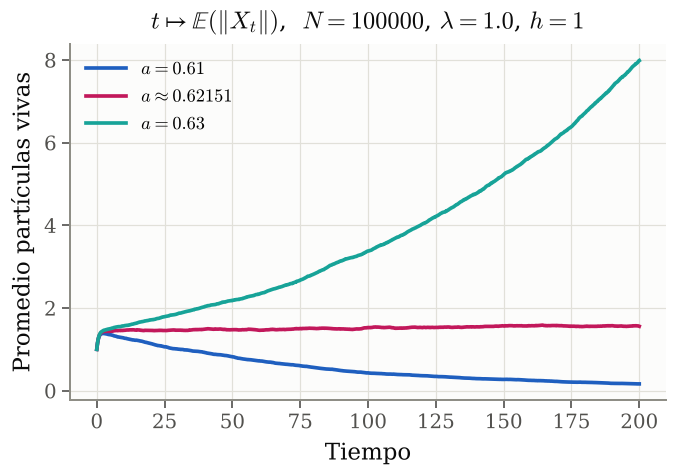

In [ ]:
# simulamos el promedio de particulas vivas con tres valores de a cerca del critico
N, T, lam, mu0 = NN(100_000), 200.0, 1.0, [0.0]
ts = np.arange(0, T + 1e-9, 0.1)
t0 = time.time()
curvas = {}
# cada corrida usa semillas distintas para que los errores no queden correlacionados
for i, a in enumerate([0.61, 0.62151, 0.63]):
    curvas[a] = promedio_vivos(N, T, a, lam, mu0, ts, seed=1000 * (i + 1))
print(f"{3*N} simulaciones en {time.time()-t0:.1f} s")

fig, ax = plt.subplots(figsize=(7, 4.2))
for (a, y), c in zip(curvas.items(), [C[0], C[4], C[2]]):
    ax.plot(ts, y, color=c, lw=2.4, label=rf"$a={a}$" if a != 0.62151 else r"$a\approx 0.62151$")
ax.set(xlabel="Tiempo", ylabel="Promedio partículas vivas",
       title=rf"$t\mapsto\mathbb{{E}}(\|X_t\|)$,  $N={N}$, $\lambda={lam}$, $h=1$")
ax.legend(loc="upper left")
guardar(fig, "fig01_tres_a"); plt.show()

### 1.2 Many-to-one

La fórmula many-to-one reduce el sistema de partículas a un solo paseo $Z$ con un peso:

$$m(t,x)=\mathbb E_{\delta_x}[\|X_t\|]=\mathbb E_x\Big[\exp\Big(\int_0^t (a-Z_s^2)\,ds\Big)\Big].$$

a=0.61, T=10.0: 3.9 s


a=0.63, T=100.0: 34.7 s


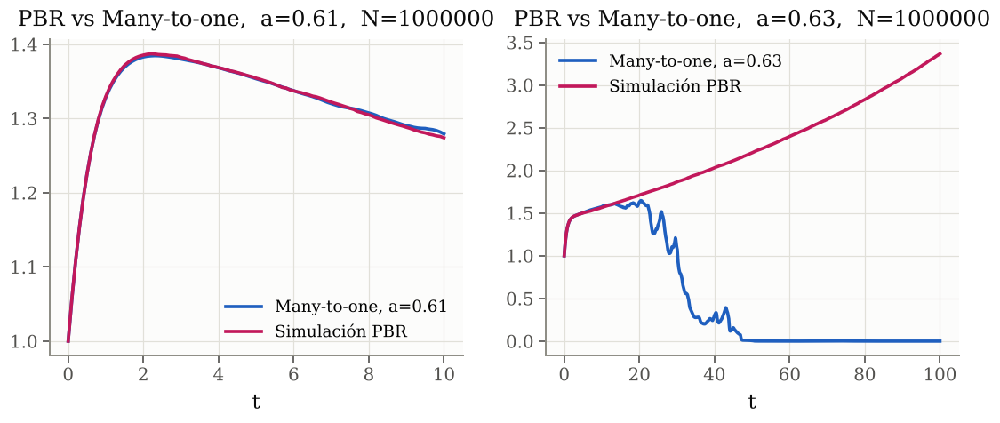

In [ ]:
# Many-to-one contra la simulacion del PBR: un tiempo corto (T=10) y uno largo (T=100)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for k, (ax, (a, T)) in enumerate(zip(axs, [(0.61, 10.0), (0.63, 100.0)])):
    ts = np.arange(0, T + 1e-9, 0.1)
    N = NN(1_000_000)
    t0 = time.time()
    m2o = many_to_one_simulacion(N, T, 1.0, [0.0], ts, a, seed=10_000 * (k + 1))
    sim = promedio_vivos(N, T, a, 1.0, [0.0], ts, seed=10_000 * (k + 1) + 5000)
    print(f"a={a}, T={T}: {time.time()-t0:.1f} s")
    ax.plot(ts, m2o, color=C[0], lw=2.4, label=f"Many-to-one, a={a}")
    ax.plot(ts, sim, color=C[4], lw=2.4, label="Simulación PBR")
    ax.set(xlabel="t", title=f"PBR vs Many-to-one,  a={a},  N={N}")
    ax.legend()
guardar(fig, "fig02_many_to_one_vs_pbr"); plt.show()

### 1.3 Por qué Many-to-one se rompe a tiempos largos

En la figura anterior Many-to-one funciona para $T=10$ y se cae para $T=100$. La razón principal es que hay trayectorias cuyo peso $W_t=\exp\big(\int_0^t(a-Z_s^2)ds\big)$ no está acotado en $t$:

- la trayectoria típica difunde, $\int_0^tZ_s^2ds$ crece como $t^2$ y su peso se va a $0$;
- la trayectoria que se queda en $0$ tiene probabilidad $e^{-\lambda t}$ y peso $e^{at}$, que crece sin cota.

Ojo que para cada $t$ fijo sí se tiene $W_t\le e^{at}$; lo que pasa es que esa cota no es uniforme en $t$. La esperanza la sostienen esas pocas trayectorias raras, así que con $N$ trayectorias casi nunca aparece una y el estimador queda por debajo del valor real; cuando aparece una, pega un salto.

En números: la varianza relativa del estimador crece como $e^{\gamma t}$ con $\gamma=\Lambda(2p)-2\Lambda(p)\approx0.47$, donde $\Lambda(q)$ es el mayor valor propio de $L-q$ y $L$ el generador del paseo. Para $T=100$ harían falta del orden de $10^{20}$ trayectorias.

**Arreglo: transformada $h$ de Doob.** Si $\varphi_0>0$ es la autofunción principal de $L-p$ (con valor propio $-a^*$), se simula el paseo con tasas $\frac\lambda2\frac{\varphi_0(x\pm h)}{\varphi_0(x)}$, que se queda cerca del origen, y

$$m(t,x)=e^{(a-a^*)t}\,\varphi_0(x)\;\mathbb E_x\Big[\frac{1}{\varphi_0(Z^{\varphi}_t)}\Big].$$

Ahí ya no hay peso exponencial.

In [ ]:
# subred x0 + hZ que cubre [-L, L]:  r + h k, |k| <= L/h, con r = x0 - h*round(x0/h)
def red(L, h=1.0, x0=0.0):
    K = int(round(L / h))
    r = x0 - h * np.round(x0 / h)
    return r + h * np.arange(-K, K + 1)

# evalua p en los puntos de la red
def pvals_de(p, x):
    return np.array([p(float(xi)) for xi in x])

# autovalor principal Λ0 de L - p (Dirichlet en la caja, matriz tridiagonal simetrica)
# y su autovector φ0 > 0 normalizado en ℓ². Los sitios con p > pmax se eliminan
# (equivale a matar instantaneamente: error O(λ²/pmax)) para evitar perdida de precision
def autopar_principal(p=p_cuadrado, lam=1.0, h=1.0, L=20.0, x0=0.0, pmax=1e8):
    x = red(L, h, x0)
    pv = pvals_de(p, x)
    keep = pv <= pmax
    x, pv = x[keep], pv[keep]
    # matriz de L - p: diagonal -lam - p(x), fuera de la diagonal lam/2
    d = -lam - pv
    e = np.where(np.isclose(np.diff(x), h), lam / 2, 0.0)   # vecinos solo si son contiguos
    # solo se pide el mayor valor propio y su vector
    w, v = sla.eigh_tridiagonal(d, e, select="i", select_range=(len(d) - 1, len(d) - 1))
    phi = np.abs(v[:, 0])
    return w[0], phi, x

# m(t, x0) = [e^{t(L - p + a)} 1](x0) en la caja [-L, L] (Dirichlet), exacto via
# descomposicion espectral de la matriz tridiagonal simetrica
def m_FK(tgrid, a, p=p_cuadrado, lam=1.0, h=1.0, L=30.0, x0=0.0, pmax=1e8):
    x = red(L, h, x0)
    pv = pvals_de(p, x); keep = pv <= pmax; x, pv = x[keep], pv[keep]
    e = np.where(np.isclose(np.diff(x), h), lam / 2, 0.0)
    w, Q = sla.eigh_tridiagonal(-lam - pv, e)
    i0 = np.argmin(np.abs(x - x0))
    # con M = Q diag(w) Q^T,  [e^{tM} 1](x0) = suma_k e^{t w_k} Q[x0,k] (Q^T 1)_k
    coef = Q[i0, :] * Q.sum(axis=0)
    tgrid = np.atleast_1d(tgrid)
    return np.exp(np.outer(tgrid, w + a)) @ coef

# a* y el exponente gamma con que crece la varianza relativa de Many-to-one
Lam_p, phi0, xs = autopar_principal(p_cuadrado)
Lam_2p, _, _ = autopar_principal(lambda x: 2.0 * x * x)   # (para la parte determinista basta una funcion de Python)
gamma = Lam_2p - 2 * Lam_p
print(f"a* = -Λ(p) = {-Lam_p:.12f}")
print(f"Λ(2p) = {Lam_2p:.6f}  ->  γ = Λ(2p) - 2Λ(p) = {gamma:.4f}")
for T in [10, 50, 100]:
    print(f"  T={T:>3}: varianza relativa ≈ e^(γT) = {np.exp(gamma*T):.2e}")

a* = -Λ(p) = 0.621510778736
Λ(2p) = -0.772431  ->  γ = Λ(2p) - 2Λ(p) = 0.4706
  T= 10: varianza relativa ≈ e^(γT) = 1.11e+02
  T= 50: varianza relativa ≈ e^(γT) = 1.65e+10
  T=100: varianza relativa ≈ e^(γT) = 2.74e+20


Para ver lo de las trayectorias, simulamos el paseo con $a=a^*$ y guardamos el peso de cada una por separado.

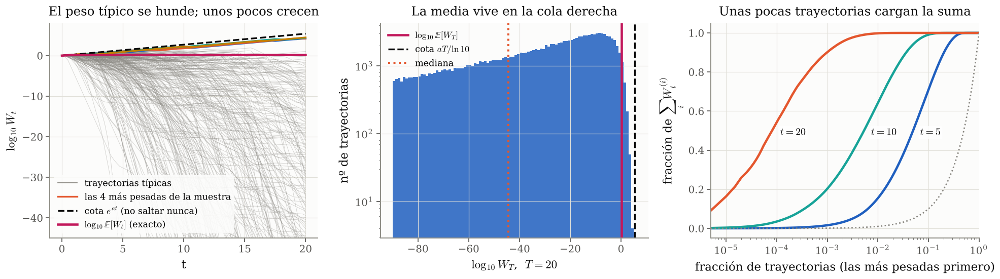

T=20, N=200000:  estimador = 1.630   exacto = 1.433
  mediana de W_T = 3.6e-45;   máximo observado = 2.98e+04;   cota e^(aT) = 2.50e+05
  las 10 trayectorias más pesadas (0.005% de la muestra) aportan el 40% de la suma
  trayectorias con W_T > 1: 0.985%
  con 1000 trayectorias: el estimador queda bajo el valor exacto en el 74% de 200 repeticiones (mediana 0.456, máximo 30.2)


In [ ]:
# guarda log W_t = ∫_0^t (a - Z_s²) ds en la grilla ts para cada una de N trayectorias del paseo desde 0
# (es el mismo Many-to-one de antes, pero sin promediar, para mirar los pesos uno por uno)
@njit(parallel=True)
def _log_pesos_m2o(N, a, lam, h, ts, nchunks, seed):
    nts = ts.shape[0]; T = ts[-1]
    out = np.empty((N, nts))
    tam = np.full(nchunks, N // nchunks); tam[: N - (N // nchunks) * nchunks] += 1
    ini = np.concatenate((np.zeros(1, np.int64), np.cumsum(tam)[:-1]))     # primera fila de cada bloque
    for c in prange(nchunks):
        np.random.seed(seed + c)
        for r in range(tam[c]):
            x = 0.0; t = 0.0; w = 0.0; k = 0
            while k < nts:
                t_sig = t + np.random.exponential() / lam
                V = a - x * x
                while k < nts and ts[k] <= t_sig:
                    out[ini[c] + r, k] = w + V * (ts[k] - t)
                    k += 1
                w += V * (t_sig - t); t = t_sig
                x += h if np.random.random() < 0.5 else -h
    return out

# con a = a* el valor exacto E[W_t] se mantiene de orden 1
a_cr = -Lam_p
Tw = 20.0; tsw = np.linspace(0, Tw, 81); Nw = NN(200_000)
logW = _log_pesos_m2o(Nw, a_cr, 1.0, 1.0, tsw, NCHUNKS, 50_000)
exacto = m_FK(tsw, a_cr)
L10 = logW / np.log(10)

fig, axs = plt.subplots(1, 3, figsize=(18, 5.2))
# (a) una muestra de trayectorias del peso (gris) y las 4 mas pesadas (color)
ax = axs[0]
orden = np.argsort(logW[:, -1])
for i in orden[:: max(1, Nw // 250)]:
    ax.plot(tsw, L10[i], color=GRIS, lw=0.6, alpha=0.35)
for j, i in enumerate(orden[-4:]):
    ax.plot(tsw, L10[i], color=C[j], lw=2.2)
ax.plot([], [], color=GRIS, lw=1.2, label="trayectorias típicas")
ax.plot([], [], color=C[1], lw=2.2, label="las 4 más pesadas de la muestra")
ax.plot(tsw, a_cr * tsw / np.log(10), color=TINTA, lw=2.2, ls="--", label=r"cota $e^{at}$ (no saltar nunca)")
ax.plot(tsw, np.log10(exacto), color=C[4], lw=3, label=r"$\log_{10}\mathbb{E}[W_t]$ (exacto)")
ax.set(ylim=(-45, 8), xlabel="t", ylabel=r"$\log_{10}W_t$", title="El peso típico se hunde; unos pocos crecen")
ax.legend(loc="lower left", fontsize=11.5, frameon=True, framealpha=0.9, edgecolor="none")

# (b) histograma de log10 W_T: la media esta en la cola derecha, lejos del peso tipico
ax = axs[1]
ax.hist(L10[:, -1], bins=np.linspace(-90, 6, 97), color=C[0], alpha=0.85)
ax.axvline(np.log10(exacto[-1]), color=C[4], lw=3, label=r"$\log_{10}\mathbb{E}[W_T]$")
ax.axvline(a_cr * Tw / np.log(10), color=TINTA, lw=2.2, ls="--", label=r"cota $aT/\ln 10$")
ax.axvline(np.median(L10[:, -1]), color=C[1], lw=2.6, ls=":", label="mediana")
ax.set(yscale="log", xlabel=rf"$\log_{{10}}W_T$,  $T={Tw:.0f}$", ylabel="nº de trayectorias",
       title="La media vive en la cola derecha")
ax.legend(loc="upper left", fontsize=11.5)

# (c) que fraccion de la suma aportan las trayectorias mas pesadas
ax = axs[2]
frac = np.arange(1, Nw + 1) / Nw
# etiqueta cada curva donde cruza 0.5
def rotular(ax, x, y, texto):
    k = int(np.searchsorted(y, 0.5))
    ax.annotate(texto, (x[k], 0.5), xytext=(9, -6), textcoords="offset points", fontsize=13, color=TINTA,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
for j, tq in enumerate([5.0, 10.0, 20.0]):
    k = int(np.argmin(np.abs(tsw - tq)))
    Wk = np.sort(np.exp(logW[:, k]))[::-1]
    cuota = np.cumsum(Wk) / Wk.sum()
    ax.plot(frac, cuota, color=C[[0, 2, 1][j]], lw=3)
    rotular(ax, frac, cuota, rf"$t={tq:.0f}$")
ax.plot(frac, frac, color=GRIS, lw=1.8, ls=":")
ax.set(xscale="log", xlim=(1 / Nw, 1), xlabel="fracción de trayectorias (las más pesadas primero)",
       ylabel=r"fracción de $\sum_i W^{(i)}_t$", title="Unas pocas trayectorias cargan la suma")
fig.tight_layout()
guardar(fig, "fig02b_trayectorias_peso"); plt.show()

# resumen en numeros
WT = np.exp(logW[:, -1]); top = np.sort(WT)[::-1]
print(f"T={Tw:.0f}, N={Nw}:  estimador = {WT.mean():.3f}   exacto = {exacto[-1]:.3f}")
print(f"  mediana de W_T = {np.median(WT):.1e};   máximo observado = {top[0]:.2e};   cota e^(aT) = {np.exp(a_cr*Tw):.2e}")
print(f"  las 10 trayectorias más pesadas ({10/Nw:.3%} de la muestra) aportan el {top[:10].sum()/WT.sum():.0%} de la suma")
print(f"  trayectorias con W_T > 1: {np.mean(WT > 1):.3%}")
lotes = WT[: (Nw // 1000) * 1000].reshape(-1, 1000).mean(axis=1)          # estimador con solo 1000 trayectorias, repetido
print(f"  con 1000 trayectorias: el estimador queda bajo el valor exacto en el {np.mean(lotes < exacto[-1]):.0%} de {len(lotes)} repeticiones "
      f"(mediana {np.median(lotes):.3f}, máximo {lotes.max():.1f})")

Con $T=20$ y $200\,000$ trayectorias, la mediana del peso es $10^{-45}$ mientras que la media exacta es $1.43$, y las 10 trayectorias más pesadas aportan el 40% de la suma. Usando solo $1000$ trayectorias el estimador queda bajo el valor exacto el 74% de las veces.

Abajo está el estimador con la transformada de Doob, que sí llega a $T=100$.

Many-to-one con Doob, N=100000: 1.4 s


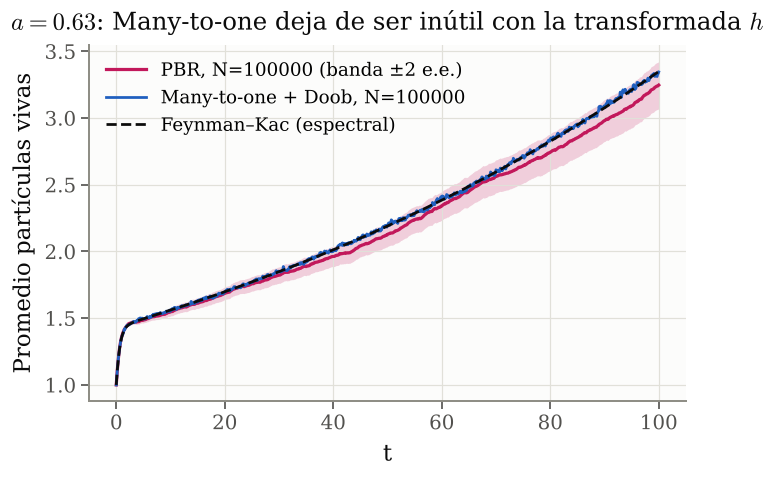

error relativo máx. Doob vs FK: 0.01523769804037367
PBR en T=100: 3.247 ± 0.177 (2 e.e.);  FK: 3.349


In [ ]:
_KERNELS_DOOB = {}
# cadena transformada: desde el sitio i sube a tasa up[i] y baja a tasa dn[i];
# se promedia 1/phi0 en los tiempos de la grilla
@njit(parallel=True)
def _doob_kernel(N, ts, up, dn, invphi, i0, nchunks, seed):
    nts = ts.shape[0]; T = ts[-1]
    acc = np.zeros((nchunks, nts))
    per = N // nchunks
    for c in prange(nchunks):
        np.random.seed(seed + c)
        m = per + (1 if c < N - per * nchunks else 0)
        for r in range(m):
            i = i0; t = 0.0; k = 0
            while k < nts:
                rate = up[i] + dn[i]
                t_sig = t + np.random.exponential() / rate
                while k < nts and ts[k] <= t_sig:
                    acc[c, k] += invphi[i]
                    k += 1
                if t_sig > T:
                    break
                t = t_sig
                # sube con probabilidad up/(up+dn)
                i = i + 1 if np.random.random() * rate < up[i] else i - 1
    return acc.sum(axis=0) / N

# estimador de Many-to-one con transformada h de Doob (varianza acotada en t)
def many_to_one_doob(N, ts, a, p=p_cuadrado, lam=1.0, h=1.0, L=12.0, x0=0.0, seed=0):
    Lam0, phi, x = autopar_principal(p, lam, h, L, x0)      # x0 fija la subred x0 + hZ
    n = len(x)
    up = np.zeros(n); dn = np.zeros(n)
    # tasas de salto transformadas: (lam/2) * phi0(vecino) / phi0(x)
    up[:-1] = lam / 2 * phi[1:] / phi[:-1]
    dn[1:] = lam / 2 * phi[:-1] / phi[1:]
    i0 = int(np.argmin(np.abs(x - x0)))
    ts = np.asarray(ts, float)
    E = _doob_kernel(int(N), ts, up, dn, 1.0 / phi, i0, NCHUNKS, seed)
    # m(t,x0) = e^{(a - a*) t} phi0(x0) E[1/phi0(Z_t)],  con a* = -Lam0
    return np.exp((a + Lam0) * ts) * phi[i0] * E

# comparacion hasta T=100: PBR, Many-to-one con Doob y Feynman-Kac
T, a = 100.0, 0.63
ts = np.arange(0, T + 1e-9, 0.1)
t0 = time.time()
md = many_to_one_doob(NN(100_000), ts, a, seed=30_000)
print(f"Many-to-one con Doob, N={NN(100_000)}: {time.time()-t0:.1f} s")
mfk = m_FK(ts, a)
fig, ax = plt.subplots(figsize=(7, 4.2))
curvas_ref, se_ref = promedio_vivos(NN(100_000), T, a, 1.0, [0.0], ts, seed=40_000, se=True)
ax.fill_between(ts, curvas_ref - 2 * se_ref, curvas_ref + 2 * se_ref, color=C[4], alpha=0.2, lw=0)
ax.plot(ts, curvas_ref, color=C[4], lw=2.1, label=f"PBR, N={NN(100_000)} (banda ±2 e.e.)")
ax.plot(ts, md, color=C[0], lw=1.8, label=f"Many-to-one + Doob, N={NN(100_000)}")
ax.plot(ts, mfk, color=TINTA, lw=1.8, ls="--", label="Feynman–Kac (espectral)")
ax.set(xlabel="t", ylabel="Promedio partículas vivas", title=r"$a=0.63$: Many-to-one deja de ser inútil con la transformada $h$")
ax.legend(loc="upper left")
guardar(fig, "fig03_doob"); plt.show()
print("error relativo máx. Doob vs FK:", np.max(np.abs(md / mfk - 1)))
print(f"PBR en T=100: {curvas_ref[-1]:.3f} ± {2*se_ref[-1]:.3f} (2 e.e.);  FK: {mfk[-1]:.3f}")

### 1.4 Ecuación de Feynman–Kac

$m(t,x)$ resuelve el sistema de EDOs en la red

$$\partial_t m_t(x)=\tfrac{\lambda}{2}\big(m_t(x+1)+m_t(x-1)-2m_t(x)\big)+(a-x^2)\,m_t(x),\qquad m_0\equiv 1 .$$

Es el port de `build_rhs` y `solve_pde`, con `solve_ivp` en vez de `Rosenbrock23`. Tres cosas del código Julia que cambiamos o hay que tener presentes:

- `build_rhs` usa la variable global `dx`; acá es un argumento.
- Con `dx = 0.5` hay dos índices que leen fuera del arreglo (bajo `@inbounds` no da error). Acá los saltos que salen de la caja se suprimen.
- Con `dx = 0.5` la grilla tiene dos subredes que no se comunican ($\mathbb Z$ y $\mathbb Z+\tfrac12$), porque los saltos son de tamaño 1. Por eso se resuelven todas las condiciones iniciales a la vez.

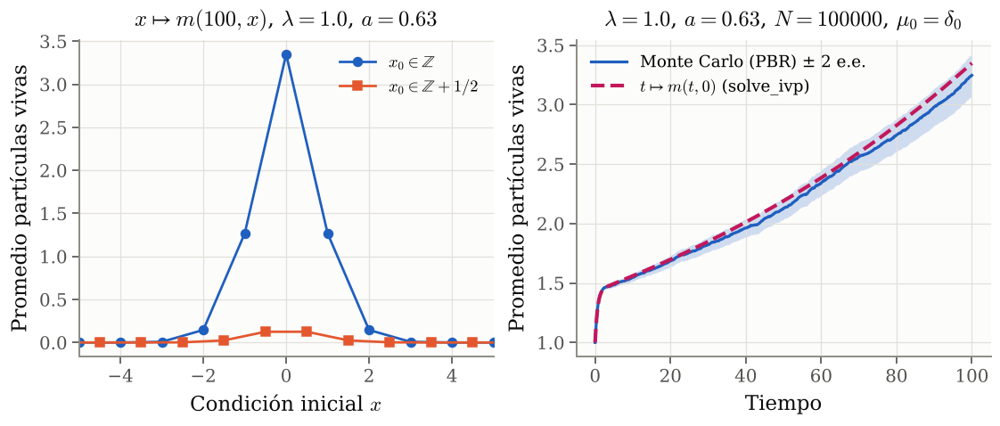

máx |solve_ivp - espectral| en x=0: 8.32960078689382e-09


In [ ]:
# lado derecho de la EDO de Feynman–Kac (port de Julia, borde reflejante)
def build_rhs(x, lam, a, dx, p=p_cuadrado):
    n = len(x)
    salto = int(round(1 / dx))
    idx = np.arange(n)
    # indices de los vecinos x+1 y x-1 (estan a 1/dx casillas); si el salto sale de la caja,
    # la particula se queda en su sitio (borde reflejante)
    ip = np.minimum(idx + salto, n - 1); ip[idx + salto > n - 1] = idx[idx + salto > n - 1]
    im = np.maximum(idx - salto, 0);     im[idx - salto < 0] = idx[idx - salto < 0]
    V = a - pvals_de(p, x)
    # matriz dispersa del operador (util tambien como jacobiano)
    rows = np.concatenate([idx, idx, idx]); cols = np.concatenate([ip, im, idx])
    vals = np.concatenate([np.full(n, lam / 2), np.full(n, lam / 2), -lam + V])
    A = sp.csr_matrix((vals, (rows, cols)), shape=(n, n))
    def rhs(t, u):
        return A @ u
    return rhs, A

# resuelve la EDO en la grilla {-L, ..., L} de paso dx, partiendo de m(0) = 1 (port de solve_pde)
def solve_pde(lam, a, dx, L, T, p=p_cuadrado, saveat=0.1, rtol=1e-8, atol=1e-10):
    x = np.arange(-L, L + dx / 2, dx)
    u0 = np.ones_like(x)                  # condicion inicial φ ≡ 1
    rhs, A = build_rhs(x, lam, a, dx, p)
    t_eval = np.arange(0, T + 1e-9, saveat)
    sol = solve_ivp(rhs, (0.0, T), u0, method="BDF", jac=A, t_eval=t_eval, rtol=rtol, atol=atol)
    return x, sol

# con dx = 0.5 se resuelven a la vez las dos subredes, Z y Z + 1/2
lam, a, dx, L, T = 1.0, 0.63, 0.5, 10.0, 100.0
x, sol = solve_pde(lam, a, dx, L, T)
vT = sol.y[:, -1]

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axs[0]
# (a) m(T, x) segun la condicion inicial, separando las dos subredes
mz = np.isclose(x % 1, 0)
ax.plot(x[mz], vT[mz], "o-", color=C[0], ms=6.5, lw=1.8, label=r"$x_0\in\mathbb{Z}$")
ax.plot(x[~mz], vT[~mz], "s-", color=C[1], ms=6.5, lw=1.8, label=r"$x_0\in\mathbb{Z}+1/2$")
ax.set(xlim=(-5, 5), xlabel="Condición inicial $x$", ylabel="Promedio partículas vivas",
       title=rf"$x\mapsto m({T:.0f},x)$, $\lambda={lam}$, $a={a}$")
ax.legend()

# (b) m(t, 0) contra el Monte Carlo
N = NN(100_000); ts = np.arange(0, T + 1e-9, 0.1)
mc = curvas_ref                                       # PBR con a=0.63 de la celda anterior
i0 = np.argmin(np.abs(x - 0.0))
axs[1].fill_between(ts, mc - 2 * se_ref, mc + 2 * se_ref, color=C[0], alpha=0.2, lw=0)
axs[1].plot(ts, mc, color=C[0], lw=2.1, label="Monte Carlo (PBR) ± 2 e.e.")
axs[1].plot(sol.t, sol.y[i0], color=C[4], lw=2.7, ls="--", label=r"$t\mapsto m(t,0)$ (solve_ivp)")
axs[1].set(xlabel="Tiempo", ylabel="Promedio partículas vivas", title=rf"$\lambda={lam}$, $a={a}$, $N={N}$, $\mu_0=\delta_0$")
axs[1].legend(loc="upper left")
guardar(fig, "fig04_feynman_kac"); plt.show()
# chequeo contra la solucion espectral
print("máx |solve_ivp - espectral| en x=0:", np.max(np.abs(sol.y[i0] - m_FK(sol.t, a, L=10.0))))

La diferencia entre Monte Carlo y la EDO a tiempos grandes es ruido: la banda de $\pm2$ errores estándar la cubre. (En todo el notebook las bandas son puntuales, y como las mismas simulaciones aportan a todos los tiempos, una curva que se sale de la banda suele quedarse afuera un rato.)

### 1.5 $a^*$ como valor propio

Port de `construir_matriz_saltos`: $a^*$ es el mayor valor propio de la matriz de $L-x^2$, con el signo cambiado.

In [ ]:
# matriz de L - p en la grilla de paso dx, con borde Dirichlet (port de construir_matriz_saltos)
def construir_matriz_saltos(lam, L, dx, p=p_cuadrado):
    assert abs(1 / dx - round(1 / dx)) < 1e-12, "dx debe dividir exactamente a 1"
    x = np.arange(-L, L + dx / 2, dx)
    n = len(x); salto = int(round(1 / dx))
    M = np.zeros((n, n))
    for i in range(n):
        M[i, i] = -lam - p(float(x[i]))
        if i + salto < n: M[i, i + salto] = lam / 2
        if i - salto >= 0: M[i, i - salto] = lam / 2
    return M, x

# mayor valor propio de la matriz; a* es ese valor con el signo cambiado
def valor_propio_principal(lam, L, dx, p=p_cuadrado):
    M, _ = construir_matriz_saltos(lam, L, dx, p)
    return np.max(np.linalg.eigvalsh(M))          # M es simetrica

# vector propio asociado (el estado fundamental)
def vector_propio_principal(lam, L, dx, p=p_cuadrado):
    M, x = construir_matriz_saltos(lam, L, dx, p)
    w, V = np.linalg.eigh(M)
    return x, np.abs(V[:, -1]), w[-1]

print("valor_propio_principal(1, 10, 1)   =", valor_propio_principal(1.0, 10, 1.0))
print("valor_propio_principal(1, 10, 0.5) =", valor_propio_principal(1.0, 10, 0.5), " (máximo sobre las 2 subredes)")
# con dx = 0.5 el maximo es el de la subred Z; la subred Z + 1/2 tiene su propio critico
L0, phi_half, _ = autopar_principal(p_cuadrado, x0=0.5)
print(f"a* para x0 ∈ Z+1/2: {-L0:.10f}   (≠ 0.6215107787 para x0 ∈ Z)")

valor_propio_principal(1, 10, 1)   = -0.621510778735887
valor_propio_principal(1, 10, 0.5) = -0.621510778735887  (máximo sobre las 2 subredes)
a* para x0 ∈ Z+1/2: 0.6523308747   (≠ 0.6215107787 para x0 ∈ Z)


Se reproduce $a^*=0.621510778735887$, igual que en Julia.

Ojo que $a^*$ depende de la subred: una partícula que parte de $x_0\in\mathbb Z+\tfrac12$ nunca pasa por el origen y su crítico es $0.65233$. Con `dx = 0.5`, `valor_propio_principal` devuelve el de $\mathbb Z$.

---
## 2. Pregunta 1: funciones $p$ generales

Ahora la tasa de muerte es una $p:\mathbb R\to\mathbb R^+$ cualquiera. Usamos $G=x_0+h\mathbb Z$ para la subred, $L$ para el generador del paseo y $V=a-p$.

**Many-to-one y Feynman–Kac valen para toda $p\ge0$:**

$$m(t,x)=\mathbb E_x\Big[\exp\Big(\int_0^t \big(a-p(Z_s)\big)\,ds\Big)\Big],\qquad \partial_tm=Lm+(a-p)\,m,\quad m_0=1 .$$

No hace falta que $p$ sea continua ni que crezca de alguna forma, porque la red solo ve los valores $p(x_0+hk)$. Lo que se usa es que los nacimientos no dependen de la posición: así $V\le a$ y los pesos quedan acotados por $e^{at}$. (Lo que sí rompería la fórmula es una tasa neta no acotada por arriba, como $V=a+x^2$.)

**El crítico** es

$$a^*(p)=-\sup\operatorname{spec}(L-p)=\inf_{\|\phi\|_2=1}\Big\{\frac\lambda2\sum_{x\in G}\big(\phi(x+h)-\phi(x)\big)^2+\sum_{x\in G}p(x)\,\phi(x)^2\Big\},$$

y el promedio crece o decae con tasa $a-a^*$. Siempre se cumple $\inf p\le a^*\le\lambda+\inf p$ y $a^*\le\liminf_{|x|\to\infty}p$.

**Qué pasa en $a=a^*$** depende de $p$:

- **(E1)** si hay un valor propio aislado ($p\to\infty$, o $p$ con un pozo), el promedio se estabiliza: $m(t,x)\to\varphi_0(x)\|\varphi_0\|_1$;
- **(E2)** si $p$ es periódica también se estabiliza;
- **(E3)** si $p=c+q$ con $q\ge0$ que se va a $0$ (una "joroba"), $a^*=c$ existe pero en $a=a^*$ el promedio decae como una potencia de $t$;
- si $p$ se hace chica en regiones arbitrariamente largas (por ejemplo $p\to0$ hacia un lado), $a^*=0$ y no hay crítico positivo.

### 2.1 Catálogo de funciones $p$

Probamos 15 funciones. Para cada una calculamos $a^*_\ell$ en la caja $|x|\le\ell$ con varios $\ell$; $a^*_\ell$ decrece con $\ell$ y converge a $a^*$.

In [ ]:
# catalogo de funciones p (compiladas con Numba para poder usarlas tambien en la simulacion)
@njit
def p_abs(x): return abs(x)
@njit
def p_x4(x): return x**4
@njit
def p_log(x): return math.log(1.0 + x * x)
@njit
def p_cosh(x): return math.cosh(x) - 1.0
@njit
def p_doble_pozo(x): return (x * x - 4.0)**2 / 16.0
@njit
def p_desplazada(x): return (x - 0.5)**2
@njit
def p_gauss(x): return 1.0 - math.exp(-x * x / 4.0)
@njit
def p_satura(x): return x * x / (1.0 + x * x)
@njit
def p_caja(x): return 2.0 if abs(x) >= 3.0 else 0.0
@njit
def p_periodica(x): return math.sin(math.pi * x / 4.0)**2
@njit
def p_lorentz(x): return 1.0 / (1.0 + x * x)
@njit
def p_media(x): return x * x if x > 0 else 0.0
@njit
def p_const(x): return 0.5
@njit
def p_joroba(x): return 1.0 + math.exp(-x * x)

CATALOGO = [
    # nombre, LaTeX, funcion, familia
    ("x2",        r"$x^2$",                         p_cuadrado,   "confinante"),
    ("abs",       r"$|x|$",                         p_abs,        "confinante"),
    ("x4",        r"$x^4$",                         p_x4,         "confinante"),
    ("log",       r"$\log(1+x^2)$",                 p_log,        "confinante"),
    ("cosh",      r"$\cosh x-1$",                   p_cosh,       "confinante"),
    ("doblepozo", r"$(x^2-4)^2/16$",                p_doble_pozo, "confinante"),
    ("despl",     r"$(x-1/2)^2$",               p_desplazada, "confinante"),
    ("gauss",     r"$1-e^{-x^2/4}$",                p_gauss,      "pozo"),
    ("satura",    r"$\frac{x^2}{1+x^2}$",           p_satura,     "pozo"),
    ("caja",      r"$2\cdot\mathbf{1}_{|x|\geq 3}$",p_caja,       "pozo"),
    ("periodica", r"$\sin^2(\pi x/4)$",             p_periodica,  "periódica"),
    ("const",     r"$0.5$",                         p_const,      "borde (trivial)"),
    ("joroba",    r"$1+e^{-x^2}$",                  p_joroba,     "borde (joroba)"),
    ("lorentz",   r"$\frac{1}{1+x^2}$",             p_lorentz,    "no admisible"),
    ("media",     r"$(x^+)^2$",                     p_media,      "no admisible"),
]

# a* en cajas |x| <= l cada vez mas grandes: si el valor no cambia con l, ya convergio
ells = [10, 20, 40, 80, 160]
tabla = {}
for nombre, tex, p, fam in CATALOGO:
    tabla[nombre] = [-autopar_principal(p, L=l)[0] for l in ells]

# tabla: a*_l para cada l, junto con las cotas inf p <= a* <= lam + inf p y el liminf de p
xg = red(400.0)                     # en esta tabla λ = h = 1
print(f"{'p(x)':<12}{'familia':<17}" + "".join(f"{'ℓ='+str(l):>11}" for l in ells)
      + f"{'inf p':>9}{'λ+inf p':>9}{'liminf p':>10}")
for nombre, tex, p, fam in CATALOGO:
    pv = pvals_de(p, xg)
    cola = np.abs(xg) >= 300                       # liminf aproximado: minimo de p en |x| ∈ [300, 400]
    lim = pv[cola].min()
    lim_txt = "∞" if lim > 1e4 else f"{lim:.3f}"
    print(f"{nombre:<12}{fam:<17}" + "".join(f"{v:11.6f}" for v in tabla[nombre])
          + f"{pv.min():9.3f}{1.0 + pv.min():9.3f}{lim_txt:>10}")

p(x)        familia                 ℓ=10       ℓ=20       ℓ=40       ℓ=80      ℓ=160    inf p  λ+inf p  liminf p
x2          confinante          0.621511   0.621511   0.621511   0.621511   0.621511    0.000    1.000         ∞
abs         confinante          0.609990   0.609990   0.609990   0.609990   0.609990    0.000    1.000   300.000
x4          confinante          0.630724   0.630724   0.630724   0.630724   0.630724    0.000    1.000         ∞
log         confinante          0.521941   0.521941   0.521941   0.521941   0.521941    0.000    1.000    11.408
cosh        confinante          0.488528   0.488528   0.488528   0.488528   0.488528    0.000    1.000         ∞
doblepozo   confinante          0.520725   0.520725   0.520725   0.520725   0.520725    0.000    1.000         ∞
despl       confinante          0.652331   0.652331   0.652331   0.652331   0.652331    0.250    1.250         ∞
gauss       pozo                0.295908   0.295908   0.295908   0.295908   0.295908    0.000   

- **Confinantes:** $a^*$ ya está convergido con $\ell=10$. $(x-\frac12)^2$ da $0.65233$, el mismo número que $x^2$ en la subred $\mathbb Z+\frac12$.
- **Pozos** ($p\to1$ o $2$): $a^*$ queda por debajo del límite de $p$ y converge rápido.
- **Periódica:** $a^*_\ell$ baja lentamente hacia $\frac{3-\sqrt5}{2}=0.381966$ (abajo se calcula exacto con una matriz $4\times4$).
- **Constante y joroba:** bajan lentamente hacia $0.5$ y $1$.
- **No admisibles:** $a^*_\ell\to0$.

Un detalle numérico con $\cosh x-1$: sin recortar los sitios donde $p$ es enorme, la matriz pierde precisión y da un valor equivocado.

In [ ]:
# cosh(x) - 1 crece tanto que la matriz completa pierde precision; el recorte pmax de autopar_principal lo evita
for l in [10, 20, 40, 80]:
    M, _ = construir_matriz_saltos(1.0, l, 1.0, p_cosh)
    sin_recorte = -np.max(np.linalg.eigvalsh(M))
    con_recorte = -autopar_principal(p_cosh, L=l)[0]
    print(f"ℓ={l:>3}:  sin recorte a* = {sin_recorte:.6f}   con recorte a* = {con_recorte:.6f}   (‖M‖ ≈ {np.cosh(l):.1e})")

# caso periodico (periodo 4): basta la matriz 4x4 en el toro Z/4Z, y a* sale exacto
pv4 = np.array([p_periodica(float(k)) for k in range(4)])
M4 = np.diag(-1.0 - pv4) + 0.5 * (np.roll(np.eye(4), 1, axis=1) + np.roll(np.eye(4), -1, axis=1))
print(f"\nperiódica: a* (toro 4x4) = {-np.max(np.linalg.eigvalsh(M4)):.15f},  (3-√5)/2 = {(3-np.sqrt(5))/2:.15f}")

ℓ= 10:  sin recorte a* = 0.488528   con recorte a* = 0.488528   (‖M‖ ≈ 1.1e+04)
ℓ= 20:  sin recorte a* = 0.488528   con recorte a* = 0.488528   (‖M‖ ≈ 2.4e+08)
ℓ= 40:  sin recorte a* = 0.617683   con recorte a* = 0.488528   (‖M‖ ≈ 1.2e+17)
ℓ= 80:  sin recorte a* = 0.617683   con recorte a* = 0.488528   (‖M‖ ≈ 2.8e+34)

periódica: a* (toro 4x4) = 0.381966011250105,  (3-√5)/2 = 0.381966011250105


### 2.2 Galería

Las funciones $p$ y sus estados fundamentales $\varphi_0$, que dan la forma en que se reparten las partículas en $a=a^*$.

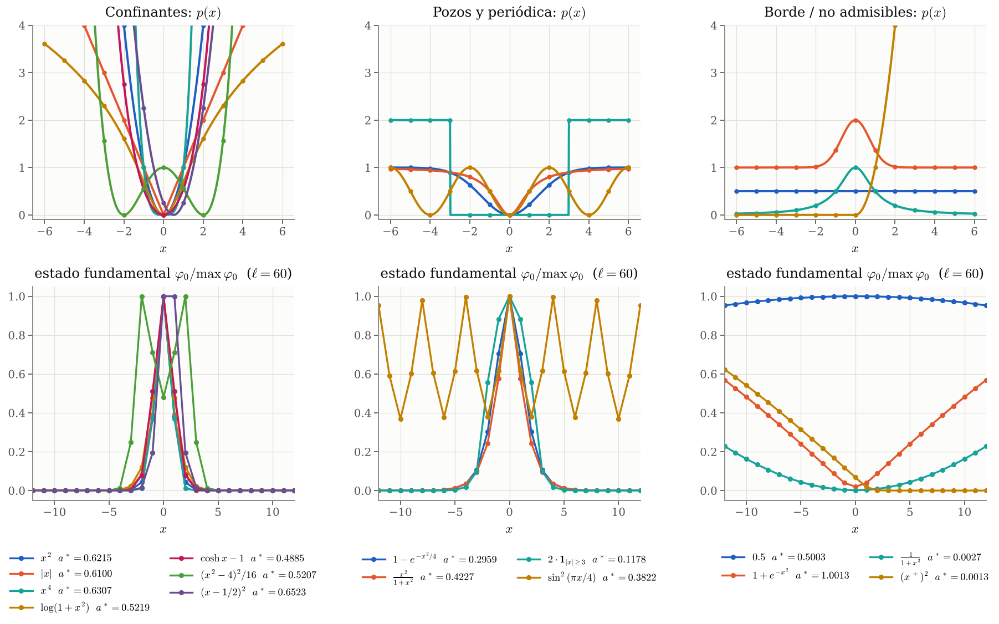

In [ ]:
# las 15 funciones en tres grupos: arriba p(x) (los puntos son los sitios de la red), abajo su estado fundamental
grupos = [("Confinantes", ["x2", "abs", "x4", "log", "cosh", "doblepozo", "despl"]),
          ("Pozos y periódica", ["gauss", "satura", "caja", "periodica"]),
          ("Borde / no admisibles", ["const", "joroba", "lorentz", "media"])]
info = {n: (tex, p, fam) for n, tex, p, fam in CATALOGO}
xx = np.linspace(-6, 6, 601); xk = np.arange(-6, 7)

fig, axs = plt.subplots(2, 3, figsize=(17, 10.5), gridspec_kw=dict(height_ratios=[1, 1.1]))
for j, (titulo, nombres) in enumerate(grupos):
    ax = axs[0, j]
    for i, n in enumerate(nombres):
        tex, p, _ = info[n]
        ax.plot(xx, [p(v) for v in xx], color=C[i % 8], lw=2.6, label=tex)
        ax.plot(xk, [p(float(v)) for v in xk], "o", color=C[i % 8], ms=4.5)
    ax.set(ylim=(-0.1, 4), title=titulo + ": $p(x)$", xlabel="$x$")
    ax = axs[1, j]
    for i, n in enumerate(nombres):
        tex, p, _ = info[n]
        Lam0, phi, x = autopar_principal(p, L=60.0)
        sel = np.abs(x) <= 12
        ax.plot(x[sel], phi[sel] / phi.max(), "o-", color=C[i % 8], ms=5, lw=2.2,
                label=tex + f"  $a^*={-Lam0:.4f}$")
    ax.set(title=r"estado fundamental $\varphi_0/\max\varphi_0$  ($\ell=60$)", xlabel="$x$", xlim=(-12, 12))
    ax.legend(fontsize=12, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2))      # misma leyenda (y colores) para la columna
fig.tight_layout()
guardar(fig, "fig05_galeria_p_phi0"); plt.show()

En el doble pozo $\varphi_0$ tiene dos máximos, en $x=\pm2$ donde $p=0$. En los casos de borde y no admisibles la autofunción se extiende por toda la caja: eso es efecto del truncamiento e indica que no hay un valor propio de verdad.

### 2.3 Validación con Monte Carlo

Para 9 funciones simulamos el sistema en $a=a^*(p)$, resolvemos Feynman–Kac y estimamos Many-to-one directo hasta $t=8$.

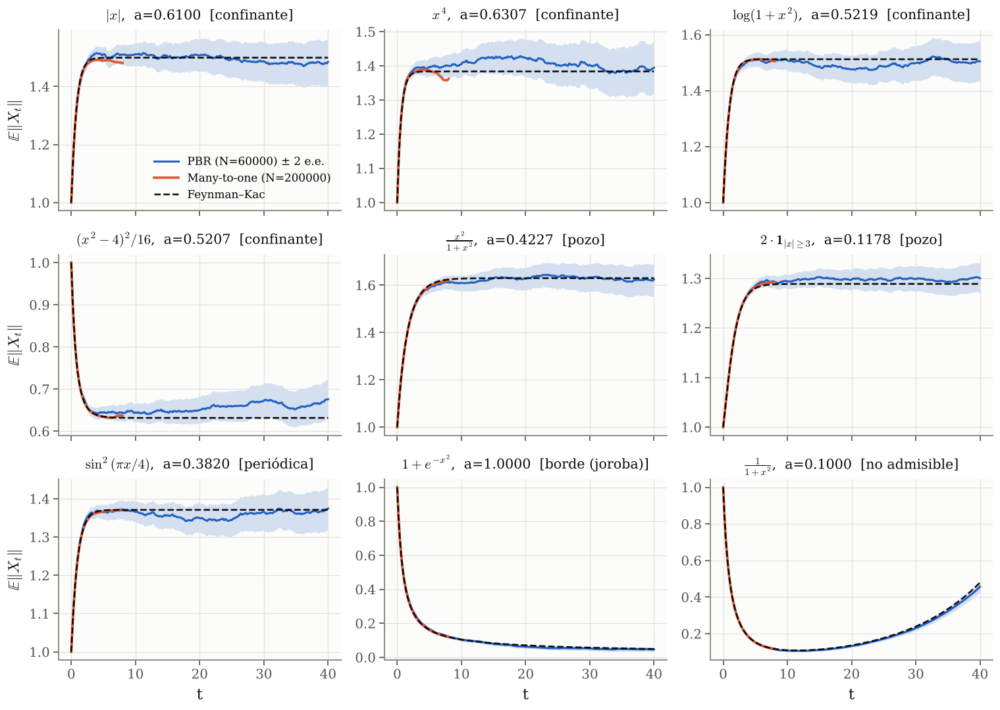

tiempo: 43.3 s
abs        a=0.60999   PBR(T)=  1.485 ± 0.080   FK(T)=  1.499   z=(PBR-FK)/e.e.=-0.36
x4         a=0.63072   PBR(T)=  1.394 ± 0.076   FK(T)=  1.384   z=(PBR-FK)/e.e.=+0.28
log        a=0.52194   PBR(T)=  1.504 ± 0.072   FK(T)=  1.512   z=(PBR-FK)/e.e.=-0.21
doblepozo  a=0.52072   PBR(T)=  0.676 ± 0.047   FK(T)=  0.632   z=(PBR-FK)/e.e.=+1.89
satura     a=0.42268   PBR(T)=  1.624 ± 0.068   FK(T)=  1.630   z=(PBR-FK)/e.e.=-0.17
caja       a=0.11782   PBR(T)=  1.300 ± 0.029   FK(T)=  1.289   z=(PBR-FK)/e.e.=+0.78
periodica  a=0.38197   PBR(T)=  1.374 ± 0.056   FK(T)=  1.371   z=(PBR-FK)/e.e.=+0.12
joroba     a=1.00003   PBR(T)=  0.046 ± 0.014   FK(T)=  0.049   z=(PBR-FK)/e.e.=-0.38
lorentz    a=0.10000   PBR(T)=  0.457 ± 0.031   FK(T)=  0.479   z=(PBR-FK)/e.e.=-1.46


In [ ]:
# nueve funciones p; None significa usar a = a*(p), y en el caso no admisible se fija a = 0.1
casos = [("abs", None), ("x4", None), ("log", None), ("doblepozo", None), ("satura", None),
         ("caja", None), ("periodica", None), ("joroba", None), ("lorentz", 0.1)]
# Many-to-one directo solo hasta t = 8, despues su varianza es demasiado grande
T, Tm2o = 40.0, 8.0
ts = np.arange(0, T + 1e-9, 0.2); ts2 = np.arange(0, Tm2o + 1e-9, 0.2)
N, N2 = NN(60_000), NN(200_000)
fig, axs = plt.subplots(3, 3, figsize=(14, 10), sharex=True)
t0 = time.time()
resumen_mc = []
for j, (ax, (n, a_fija)) in enumerate(zip(axs.flat, casos)):
    tex, p, fam = info[n]
    # si p no confina, el paseo se va lejos y hace falta una caja mas grande
    confin = fam in ("confinante", "pozo")
    a = a_fija if a_fija is not None else -autopar_principal(p, L=40.0 if confin else 400.0)[0]
    # las tres vias: sistema de particulas, Many-to-one y Feynman-Kac
    sim, se = promedio_vivos(N, T, a, 1.0, [0.0], ts, p=p, seed=1000 * (j + 1), se=True)   # semillas distintas
    m2o = many_to_one_simulacion(N2, Tm2o, 1.0, [0.0], ts2, a, p=p, seed=1000 * (j + 1) + 500)
    fk = m_FK(ts, a, p=p, L=40.0 if confin else 200.0)
    ax.fill_between(ts, sim - 2 * se, sim + 2 * se, color=C[0], alpha=0.18, lw=0)
    ax.plot(ts, sim, color=C[0], lw=2, label=f"PBR (N={N}) ± 2 e.e.")
    ax.plot(ts2, m2o, color=C[1], lw=2.4, label=f"Many-to-one (N={N2})")
    ax.plot(ts, fk, color=TINTA, lw=1.7, ls="--", label="Feynman–Kac")
    ax.set_title(f"{tex},  a={a:.4f}  [{fam}]", fontsize=13.5)
    resumen_mc.append((n, a, sim[-1], se[-1], fk[-1]))
for ax in axs[-1]: ax.set_xlabel("t")
for ax in axs[:, 0]: ax.set_ylabel(r"$\mathbb{E}\|X_t\|$")
axs[0, 0].legend(fontsize=11)
fig.tight_layout()
guardar(fig, "fig06_validacion_p"); plt.show()
print(f"tiempo: {time.time()-t0:.1f} s")
# z = diferencia PBR - FK en unidades de error estandar (deberia ser del orden de 1)
for n, a, s, e, f in resumen_mc:
    print(f"{n:<10} a={a:.5f}   PBR(T)={s:7.3f} ± {2*e:.3f}   FK(T)={f:7.3f}   z=(PBR-FK)/e.e.={(s-f)/e:+.2f}")

Las tres curvas coinciden en las 9 funciones, incluyendo una discontinua, una periódica y una no confinante. Las diferencias entre el PBR y Feynman–Kac son todas menores que 2 errores estándar.

### 2.4 Comportamiento en $a=a^*$ a tiempos largos

Resolvemos Feynman–Kac hasta $t=400$ para ver los casos (E1), (E2) y (E3).

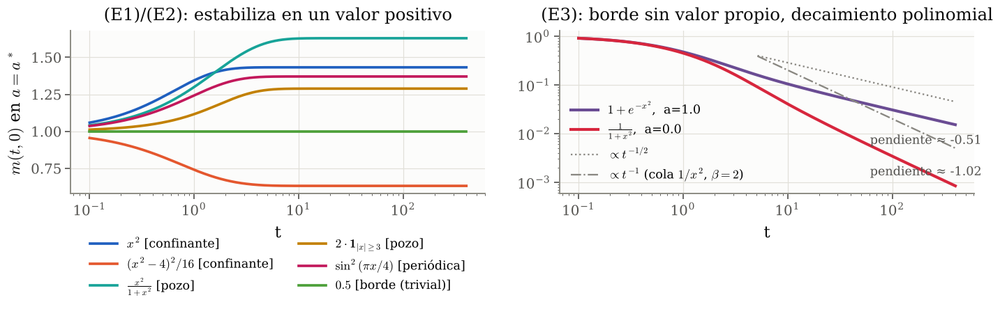

In [ ]:
# m(t,0) en a = a* hasta t = 400, resolviendo Feynman-Kac en una caja grande
tt = np.logspace(-1, np.log10(400), 300)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
# (a) casos en que el promedio se estabiliza
for i, n in enumerate(["x2", "doblepozo", "satura", "caja", "periodica", "const"]):
    tex, p, fam = info[n]
    l = 40.0 if fam in ("confinante", "pozo") else 600.0
    a = -autopar_principal(p, L=l)[0] if n != "periodica" else (3 - np.sqrt(5)) / 2
    # para p periodica y p constante se usa el a* exacto
    if n == "const": a = 0.5
    axs[0].plot(tt, m_FK(tt, a, p=p, L=l), color=C[i], lw=2.4, label=f"{tex} [{fam}]")
axs[0].set(xscale="log", xlabel="t", ylabel=r"$m(t,0)$ en $a=a^*$", title="(E1)/(E2): estabiliza en un valor positivo")
axs[0].legend(fontsize=11.5, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2))

# (b) casos sin valor propio en el borde: el promedio decae como una potencia de t
for i, (n, a) in enumerate([("joroba", 1.0), ("lorentz", 0.0)]):
    tex, p, fam = info[n]
    y = m_FK(tt, a, p=p, L=600.0)
    axs[1].plot(tt, y, color=C[i + 6], lw=2.7, label=f"{tex},  a={a}")
    sel = tt > 50
    # pendiente en escala log-log (el exponente del decaimiento)
    pend = np.polyfit(np.log(tt[sel]), np.log(y[sel]), 1)[0]
    axs[1].annotate(f"pendiente ≈ {pend:.2f}", (tt[-1], y[-1]), textcoords="offset points",
                    xytext=(-80, 10 if i else -18), fontsize=11.5, color=TINTA2)
axs[1].plot(tt[tt > 5], 0.9 * tt[tt > 5]**-0.5, color=GRIS, lw=1.5, ls=":", label=r"$\propto t^{-1/2}$")
axs[1].plot(tt[tt > 5], 2.0 * tt[tt > 5]**-1.0, color=GRIS, lw=1.5, ls="-.", label=r"$\propto t^{-1}$ (cola $1/x^2$, $\beta=2$)")
axs[1].set(xscale="log", yscale="log", xlabel="t", title="(E3): borde sin valor propio, decaimiento polinomial")
axs[1].legend(fontsize=11.5)
fig.tight_layout()
guardar(fig, "fig07_regimenes"); plt.show()

En el panel izquierdo el promedio se estabiliza en un valor positivo. En el derecho decae como potencia: la pendiente es $-0.51$ para la joroba $1+e^{-x^2}$ y $-1.02$ para $\frac{1}{1+x^2}$.

### 2.5 Barridos en un parámetro

- $p=c\,x^2$: para $c\to\infty$, $a^*\to\lambda$ (la partícula solo sobrevive si no se mueve de $0$), y para $c\to0$, $a^*\approx\sqrt{c\lambda/2}$, que es la energía del oscilador armónico.
- $p=|x|^\beta$: va de $2-\sqrt2$ ($\beta\to0$) a $0.634$ ($\beta\to\infty$).

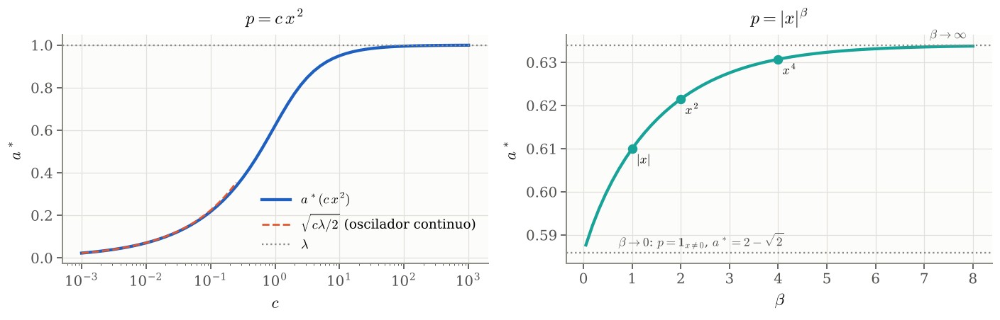

In [ ]:
# barrido en c para p = c x^2 (aca no hace falta Numba, basta una funcion de Python)
cs = np.logspace(-3, 3, 61)
a_c = [-autopar_principal(lambda x, c=c: c * x * x, L=max(20.0, 6 / c**0.25))[0] for c in cs]
# barrido en beta para p = |x|^beta
betas = np.linspace(0.05, 8, 60)
def p_beta_factory(b):
    return lambda x: abs(x)**b
a_b = [-autopar_principal(p_beta_factory(b), L=30.0)[0] for b in betas]
# los dos limites: beta -> infinito (solo quedan los sitios -1, 0, 1) y beta -> 0 (p = 1 fuera del origen)
M0 = np.array([[-2.0, .5, 0], [.5, -1.0, .5], [0, .5, -2.0]])   # sitios -1,0,1; p=(1,0,1), Dirichlet fuera
lim_inf_beta = -np.max(np.linalg.eigvalsh(M0))
lim_0_beta = -autopar_principal(lambda x: 0.0 if x == 0 else 1.0, L=60.0)[0]

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
axs[0].plot(cs, a_c, color=C[0], label=r"$a^*(c\,x^2)$")
axs[0].plot(cs[cs < 0.3], np.sqrt(cs[cs < 0.3] / 2), color=C[1], lw=1.8, ls="--", label=r"$\sqrt{c\lambda/2}$ (oscilador continuo)")
axs[0].axhline(1.0, color=GRIS, lw=1.5, ls=":", label=r"$\lambda$")
axs[0].set(xscale="log", xlabel="$c$", ylabel="$a^*$", title=r"$p=c\,x^2$")
axs[0].legend()
axs[1].plot(betas, a_b, color=C[2], label=r"$a^*(|x|^\beta)$")
axs[1].axhline(lim_inf_beta, color=GRIS, lw=1.5, ls=":")
axs[1].axhline(lim_0_beta, color=GRIS, lw=1.5, ls=":")
axs[1].annotate(r"$\beta\to\infty$", (betas[-1], lim_inf_beta), xytext=(-40, 6), textcoords="offset points", fontsize=11.5, color=TINTA2)
axs[1].annotate(r"$\beta\to0$: $p=\mathbf{1}_{x\neq0}$, $a^*=2-\sqrt{2}$", (betas[0], lim_0_beta), xytext=(30, 6), textcoords="offset points", fontsize=11.5, color=TINTA2)
for b, tx in [(1, "|x|"), (2, "x^2"), (4, "x^4")]:
    axs[1].plot(b, -autopar_principal(p_beta_factory(float(b)), L=30.0)[0], "o", color=C[2], ms=7.8)
    axs[1].annotate(f"${tx}$", (b, -autopar_principal(p_beta_factory(float(b)), L=30.0)[0]), xytext=(4, -14), textcoords="offset points", fontsize=11.5)
axs[1].set(xlabel=r"$\beta$", ylabel="$a^*$", title=r"$p=|x|^\beta$")
fig.tight_layout()
guardar(fig, "fig08_barridos"); plt.show()

### 2.6 El caso $p(x)=\dfrac{1}{1+1/x^2}$

Esta función es $\frac{x^2}{1+x^2}$ (la `satura` del catálogo): vale $0$ en el origen y tiende a $1$ en el infinito. Como es acotada uno podría pensar que la población explota y no hay $a^*$. Lo que sale es:

- **Para $a>1$ sí explota**, desde cualquier punto: la tasa neta $a-p$ es positiva en todos los sitios y $m(t,x)\ge e^{(a-1)t}$. Con $p=x^2$ eso no pasa nunca, porque lejos del origen las partículas mueren muy rápido.
- **Pero $a^*$ existe igual.** El pozo en $x=0$ atrapa (caso E1) y da $a^*=0.4227<1$. En $a=a^*$ el promedio se estabiliza en $\varphi_0(x)\|\varphi_0\|_1$.
- **Entre $a^*$ y $1$** el promedio crece como $e^{(a-a^*)t}$ aunque lejos del origen la tasa neta sea negativa: el crecimiento lo sostiene el pozo.

La diferencia con el caso confinante es que acá $\varphi_0$ decae solo exponencialmente, $\varphi_0(x)\approx e^{-\kappa|x|}$ con $\cosh\kappa=1+(1-a^*)/\lambda$. El caso que sí queda sin crítico es el "espejo" $\frac{1}{1+x^2}$, donde $p\to0$.

a* = 0.422685;   segundo autovalor de -(L-p): 0.9294 (borde del espectro esencial: 1)
decaimiento de φ0: pendiente ajustada = 1.026,  κ = arccosh(1+(1-a*)/λ) = 1.029


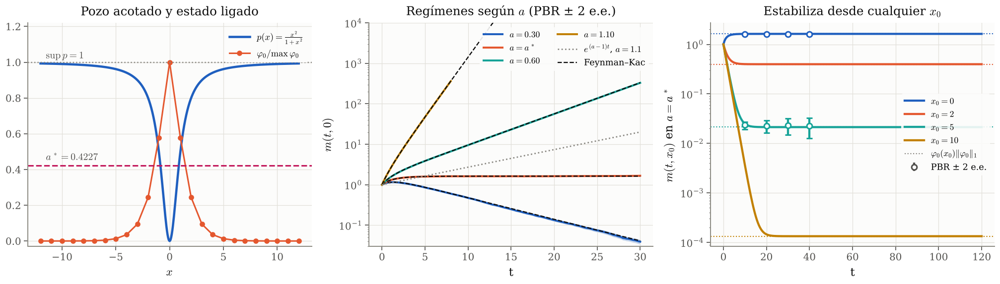

In [ ]:
# p(x) = 1/(1 + 1/x^2) = x^2/(1 + x^2): vale 0 en el origen y satura en 1
p_s = p_satura
Lam_s, phi_s, x_s = autopar_principal(p_s, L=200.0)
a_s = -Lam_s
# segundo autovalor (para ver que el principal esta aislado) y tasa de decaimiento de φ0
xx_s = red(200.0); pv_s = pvals_de(p_s, xx_s)
w2 = sla.eigh_tridiagonal(-1.0 - pv_s, np.full(len(xx_s) - 1, 0.5), select="i", select_range=(len(xx_s) - 2, len(xx_s) - 1))[0]
# lejos del origen p ≈ 1, y la ecuacion de valores propios da phi0 ~ e^{-kappa |x|}
kappa = np.arccosh(1 + (1 - a_s) / 1.0)
i0s = int(np.argmin(np.abs(x_s)))
pend = -np.polyfit(x_s[i0s + 10:i0s + 30], np.log(phi_s[i0s + 10:i0s + 30]), 1)[0]
print(f"a* = {a_s:.6f};   segundo autovalor de -(L-p): {-w2[0]:.4f} (borde del espectro esencial: 1)")
print(f"decaimiento de φ0: pendiente ajustada = {pend:.3f},  κ = arccosh(1+(1-a*)/λ) = {kappa:.3f}")

fig, axs = plt.subplots(1, 3, figsize=(18.5, 5.4))
# (A) el pozo y su estado ligado
ax = axs[0]
xc = np.linspace(-12, 12, 481); sel = np.abs(x_s) <= 12
ax.plot(xc, [p_s(v) for v in xc], color=C[0], lw=3, label=r"$p(x)=\frac{x^2}{1+x^2}$")
ax.plot(x_s[sel], phi_s[sel] / phi_s.max(), "o-", color=C[1], ms=6, lw=2, label=r"$\varphi_0/\max\varphi_0$")
ax.axhline(1.0, color=GRIS, lw=1.6, ls=":"); ax.axhline(a_s, color=C[4], lw=2, ls="--")
ax.annotate(r"$\sup p=1$", (-11.5, 1.02), fontsize=13, color=TINTA2)
ax.annotate(rf"$a^*={a_s:.4f}$", (-11.5, a_s + 0.03), fontsize=13, color=TINTA2)
ax.set(xlabel="$x$", ylim=(-0.03, 1.22), title="Pozo acotado y estado ligado")
ax.legend(loc="upper right", fontsize=12, frameon=True, framealpha=0.9, edgecolor="none")

# (B) los regimenes en el tiempo: Feynman–Kac y Monte Carlo
ax = axs[1]
Ts_ = 30.0; ts_ = np.linspace(0, Ts_, 151); N_ = NN(40_000)
# para a = 1.1 el Monte Carlo solo llega a t = 8 (despues hay demasiadas particulas)
for j, (a_, Tmc) in enumerate([(0.30, Ts_), (a_s, Ts_), (0.60, Ts_), (1.10, 8.0)]):
    fk = m_FK(ts_, a_, p=p_s, L=300.0)
    tm = ts_[ts_ <= Tmc + 1e-9]
    mc, se = promedio_vivos(N_, Tmc, a_, 1.0, [0.0], tm, p=p_s, seed=60_000 + 1000 * j, se=True)
    ax.fill_between(tm, np.maximum(mc - 2 * se, 1e-3), mc + 2 * se, color=C[j], alpha=0.25, lw=0)
    ax.plot(tm, mc, color=C[j], lw=2.6, label=(rf"$a={a_:.2f}$" if j != 1 else r"$a=a^*$"))
    ax.plot(ts_, fk, color=TINTA, lw=1.5, ls="--")
# cota inferior e^{(a-1)t}: con a > sup p = 1 crece desde cualquier sitio
ax.plot(ts_, np.exp(0.10 * ts_), color=GRIS, lw=1.8, ls=":", label=r"$e^{(a-1)t}$, $a=1.1$")
ax.plot([], [], color=TINTA, lw=1.5, ls="--", label="Feynman–Kac")
ax.set(yscale="log", ylim=(3e-2, 1e4), xlabel="t", ylabel=r"$m(t,0)$", title="Regímenes según $a$ (PBR ± 2 e.e.)")
ax.legend(loc="upper right", fontsize=11.5, ncol=2, frameon=True, framealpha=0.9, edgecolor="none")

# (C) en a = a*: estabiliza desde cualquier punto de partida
ax = axs[2]
Tl = 120.0; tl = np.linspace(0, Tl, 241)
xb = red(300.0); pb = pvals_de(p_s, xb)
# solucion espectral de Feynman-Kac para varios puntos de partida a la vez
wq, Q = sla.eigh_tridiagonal(-1.0 - pb, np.full(len(xb) - 1, 0.5))
Qs = Q.sum(axis=0)
for j, x0_ in enumerate([0, 2, 5, 10]):
    i0_ = int(np.argmin(np.abs(xb - x0_)))
    y = np.exp(np.outer(tl, wq + a_s)) @ (Q[i0_] * Qs)
    ax.plot(tl, y, color=C[j], lw=2.8, label=rf"$x_0={x0_}$")
    # limite teorico phi0(x0) * ||phi0||_1
    lim = phi_s[np.argmin(np.abs(x_s - x0_))] * phi_s.sum()
    ax.axhline(lim, color=C[j], lw=1.4, ls=":")
    if x0_ in (0, 5):
        mc, se = promedio_vivos(NN(40_000), 40.0, a_s, 1.0, [float(x0_)], np.array([10.0, 20.0, 30.0, 40.0]), p=p_s,
                                seed=70_000 + 1000 * j, se=True)
        ax.errorbar([10, 20, 30, 40], mc, yerr=2 * se, fmt="o", color=C[j], ms=7, capsize=4, mfc="white", mew=2)
ax.plot([], [], color=GRIS, lw=1.4, ls=":", label=r"$\varphi_0(x_0)\|\varphi_0\|_1$")
ax.errorbar([], [], yerr=[], fmt="o", color=TINTA2, ms=7, mfc="white", mew=2, label="PBR ± 2 e.e.")
ax.set(yscale="log", xlabel="t", ylabel=r"$m(t,x_0)$ en $a=a^*$", title="Estabiliza desde cualquier $x_0$")
ax.legend(loc="center right", fontsize=11.5, ncol=1, frameon=True, framealpha=0.9, edgecolor="none")
fig.tight_layout()
guardar(fig, "fig08b_p_saturante"); plt.show()

### 2.7 Respuesta a la Pregunta 1

- Many-to-one y Feynman–Kac valen para cualquier $p\ge0$, sin pedirle regularidad.
- Siempre hay un umbral $a^*(p)=-\sup\operatorname{spec}(L-p)$. Es positivo salvo que $p$ se haga chica en regiones arbitrariamente largas.
- En $a=a^*$ el promedio se estabiliza si $p$ confina, tiene un pozo o es periódica. Si no, decae como potencia.

---
## 3. Pregunta 2: tasa de salto $\lambda(t)$

Volvemos a $p(x)=x^2$, pero ahora cada partícula salta a tasa $\lambda(t)$. Notación: $\Lambda(t)=\int_0^t\lambda$, $L_1$ es el generador del paseo de tasa 1 y $V(x)=a-x^2$.

### 3.1 Many-to-one

Sigue valiendo, con $Z$ el paseo que salta a tasa $\lambda(t)$ (o sea $Z_t=Y_{\Lambda(t)}$ con $Y$ de tasa 1). Para un tiempo de observación $T$ y $0\le s\le T$,

$$u(s,x):=\mathbb E\big[\|X_T\|\,\big|\,X_s=\delta_x\big]=\mathbb E\Big[e^{\int_s^T (a-Z_r^2)\,dr}\,\Big|\,Z_s=x\Big].$$

Solo se necesita que $\Lambda(t)<\infty$, o sea que el paseo dé finitos saltos. No hace falta que $\lambda$ sea continua ni acotada.

#### De dónde sale la ecuación backward

$u(s,x)$ responde: si en el tiempo $s$ hay una partícula en $x$, ¿cuántas hay en promedio en $T$?

En $s=T$ la respuesta es un dato, $u(T,x)=1$, porque no queda tiempo para que pase nada. En cambio $u(0,x)=m(T,x)$ es lo que buscamos. Por eso la condición va en el tiempo **final**.

Para los otros $s$ miramos lo que hace la partícula en $[s,s+ds]$:

- salta a $x\pm h$ con probabilidad $\tfrac12\lambda(s)ds$ cada uno, y queda $u(s+ds,x\pm h)$;
- se reemplaza por dos con probabilidad $a\,ds$, y queda $2u(s+ds,x)$;
- muere con probabilidad $x^2ds$, y queda $0$;
- si no pasa nada queda $u(s+ds,x)$.

Sumando y pasando al límite:

$$-\partial_su=\lambda(s)L_1u+(a-x^2)\,u,\qquad u(T,\cdot)=1 .\tag{B}$$

El signo menos aparece porque se deriva respecto del tiempo de partida. Con $\lambda$ constante $u$ depende solo de $T-s$ y se recupera la EDO de la sección 1; con $\lambda(t)$ eso se pierde.

### 3.2 Las cuatro ecuaciones

- **(B) backward:** la de arriba. Se resuelve de $T$ hacia $0$ y da $m(T,x)=u(0,x)$.
- **(B↺) backward revertida:** con $\sigma=T-s$ queda $\partial_\sigma w=\lambda(T-\sigma)L_1w+Vw$, $w(0)=1$. Ojo que la tasa va evaluada en $T-\sigma$. Da $m(T,x)$ para todo $x$, pero hay que resolverla de nuevo para cada $T$.
- **(F) forward:** $\partial_s\rho=\lambda(s)L_1\rho+V\rho$, $\rho_0=\delta_{x_0}$. $\rho_s(y)$ es el número esperado de partículas en $y$ y $m(s,x_0)=\sum_y\rho_s(y)$. Con una sola EDO se tiene toda la curva en $s$.
- **(N) ingenua:** $\partial_t\tilde m=\lambda(t)L_1\tilde m+V\tilde m$, $\tilde m(0)=1$, o sea la EDO de la sección 1 cambiando $\lambda$ por $\lambda(t)$. **No** calcula $m$: comparando con (B↺) se ve que calcula el sistema con el perfil invertido $\lambda(T-r)$.

(B) y (F) dan lo mismo porque $L_1$ y $V$ son simétricos: $\sum_y\rho_s(y)u(s,y)$ no depende de $s$.

Sobre lo que dice "la IA" en el enunciado: es correcto, con dos precisiones. En la fórmula $\mathbb E[f(X_T)e^{\int V}\mid X_t=x]$ el proceso $X$ tiene que ser el paseo $Z$ y no el PBR, y la "Fokker–Planck" es la ecuación del número esperado de partículas, que no es una densidad de probabilidad porque no suma 1.

### 3.3 Simulación con $\lambda(t)$

Hay tres relojes: movimiento (intensidad $n\lambda(t)$), nacimiento ($n\,a(t)$) y muerte ($\sum_ix_i^2$). Los que dependen del tiempo se sortean invirtiendo la integral, por ejemplo $\tau_{\rm mov}=\Lambda^{-1}(\Lambda(t)+E/n)$ con $E\sim\mathrm{Exp}(1)$. Así solo se necesita $\Lambda$ y funciona aunque $\lambda$ no sea acotada.

In [ ]:
# tabla (tg, G) con G(t) = ∫_0^t f, por trapecios en una malla fina
# si se entrega la primitiva exacta F se usa directamente
def tabla_acumulada(f=None, T=1.0, M=200_001, F=None, malla=None):
    tg = np.linspace(0.0, T * (1 + 1e-9) + 1e-9, M) if malla is None else np.asarray(malla, float)
    if F is not None:
        G = F(tg)
    else:
        v = f(tg)
        G = np.concatenate([[0.0], np.cumsum(0.5 * (v[1:] + v[:-1]) * np.diff(tg))])
    return tg, G

# kernels para tasas que dependen del tiempo: lam(t) y a(t) entran como tablas acumuladas
_KERNELS_T = {}
def kernels_t(pfun):
    if pfun in _KERNELS_T:
        return _KERNELS_T[pfun]

    # una realizacion del PBR con lam(t) y a(t). Hay tres relojes y gana el primero que suena:
    # movimiento (intensidad n*lam(t)), nacimiento (n*a(t)) y muerte (suma de p(x_i))
    @njit
    def una(T, h, mu0, ts, tg, LamG, tgA, AG, out, out2):
        n0 = mu0.shape[0]; cap = max(512, 4 * n0)
        pos = np.empty(cap); w = np.empty(cap)
        n = n0; P = 0.0
        for j in range(n0):
            pos[j] = mu0[j]; w[j] = pfun(mu0[j]); P += w[j]
        t = 0.0; k = 0; nts = ts.shape[0]
        LamT = LamG[-1]; AT = AG[-1]
        while n > 0:
            # los relojes que dependen del tiempo se sortean invirtiendo la tabla acumulada (cambio de tiempo),
            # asi que lam no necesita ser acotada
            s = np.interp(t, tg, LamG) + np.random.exponential() / n          # reloj de movimiento
            tm = np.interp(s, LamG, tg) if s < LamT else np.inf
            s = np.interp(t, tgA, AG) + np.random.exponential() / n           # reloj de nacimiento
            tb = np.interp(s, AG, tgA) if s < AT else np.inf
            td = t + np.random.exponential() / P if P > 0 else np.inf         # reloj de muerte
            tn = min(tm, min(tb, td))
            while k < nts and ts[k] <= tn:
                out[k] += n; out2[k] += n * n
                k += 1
            if tn > T:
                break
            t = tn
            if tn == tm:                                   # movimiento
                i = np.random.randint(n)
                y = pos[i] + (h if np.random.random() < 0.5 else -h)
                py = pfun(y); P += py - w[i]; pos[i] = y; w[i] = py
            elif tn == tb:                                 # nacimiento (copia en el mismo sitio)
                i = np.random.randint(n)
                if n == cap:
                    cap *= 2
                    p2 = np.empty(cap); w2 = np.empty(cap)
                    p2[:n] = pos[:n]; w2[:n] = w[:n]; pos = p2; w = w2
                pos[n] = pos[i]; w[n] = w[i]; P += w[i]; n += 1
            else:                                          # muerte, con prob. ∝ p(x_i)
                u = np.random.random() * P; acc = 0.0; i = n - 1
                for j in range(n):
                    acc += w[j]
                    if acc >= u:
                        i = j; break
                P -= w[i]; pos[i] = pos[n - 1]; w[i] = w[n - 1]; n -= 1
                if P < 1e-9:                               # re-sincroniza por redondeo
                    P = 0.0
                    for j in range(n): P += w[j]

    # promedio de N realizaciones en bloques paralelos
    @njit(parallel=True)
    def brw(N, T, h, mu0, ts, tg, LamG, tgA, AG, nchunks, seed):
        acc = np.zeros((nchunks, ts.shape[0])); acc2 = np.zeros((nchunks, ts.shape[0]))
        per = N // nchunks
        for c in prange(nchunks):
            np.random.seed(seed + c)
            m = per + (1 if c < N - per * nchunks else 0)
            for r in range(m):
                una(T, h, mu0, ts, tg, LamG, tgA, AG, acc[c], acc2[c])
        return acc.sum(axis=0) / N, acc2.sum(axis=0) / N

    @njit(parallel=True)
    def m2o(N, T, h, x0, ts, tg, LamG, tgA, AG, nchunks, seed):
        # Many-to-one inhomogeneo: E[exp(A(t) - ∫_0^t p(Z_r) dr)], Z con tasa λ(t)
        acc = np.zeros((nchunks, ts.shape[0])); acc2 = np.zeros((nchunks, ts.shape[0]))
        per = N // nchunks; nts = ts.shape[0]; LamT = LamG[-1]
        for c in prange(nchunks):
            np.random.seed(seed + c)
            m = per + (1 if c < N - per * nchunks else 0)
            for r in range(m):
                x = x0; t = 0.0; I = 0.0; k = 0
                while k < nts:
                    s = np.interp(t, tg, LamG) + np.random.exponential()
                    # proximo salto del paseo de tasa lam(t)
                    tn = np.interp(s, LamG, tg) if s < LamT else np.inf
                    px = pfun(x)
                    while k < nts and ts[k] <= tn:
                        # peso = exp(∫a - ∫p(Z)): I lleva la integral de p hasta el ultimo salto
                        W = math.exp(np.interp(ts[k], tgA, AG) - I - px * (ts[k] - t))
                        acc[c, k] += W; acc2[c, k] += W * W
                        k += 1
                    if tn > T:
                        break
                    I += px * (tn - t); t = tn
                    x += h if np.random.random() < 0.5 else -h
        return acc.sum(axis=0) / N, acc2.sum(axis=0) / N

    _KERNELS_T[pfun] = dict(brw=brw, m2o=m2o)
    return _KERNELS_T[pfun]

# E|X_t| y error estandar para el PBR con λ(t) y a(t) dados como tablas acumuladas
def promedio_vivos_t(N, T, tab_lam, tab_a, mu0, ts, p=p_cuadrado, h=1.0, seed=0):
    ts = np.asarray(ts, float); mu0 = np.asarray(mu0, float)
    m1, m2 = kernels_t(p)["brw"](int(N), float(T), float(h), mu0, ts, *tab_lam, *tab_a, NCHUNKS, seed)
    return _media_y_se(m1, m2, N)

# Many-to-one con lam(t): un solo paseo ponderado (misma interfaz que promedio_vivos_t)
def many_to_one_t(N, T, tab_lam, tab_a, x0, ts, p=p_cuadrado, h=1.0, seed=0):
    ts = np.asarray(ts, float)
    m1, m2 = kernels_t(p)["m2o"](int(N), float(T), float(h), float(x0), ts, *tab_lam, *tab_a, NCHUNKS, seed)
    return _media_y_se(m1, m2, N)

In [ ]:
# solvers de las ecuaciones en la caja |x| <= ell (Dirichlet), para lam(t) variable

# red, matriz L1 del paseo de tasa 1 y valores de p
def matrices_caja(ell=15.0, p=p_cuadrado, h=1.0):
    x = red(ell, h); n = len(x)
    L1 = sp.diags([np.full(n - 1, 0.5), np.full(n, -1.0), np.full(n - 1, 0.5)], [-1, 0, 1], format="csr")
    return x, L1, pvals_de(p, x)

# integra  dy/dt = cL(t) * L1 y + cV(t) * Vvec * y,  con (cL, cV) = coef(t),
# en [t0, t1] (LSODA, jacobiano exacto), reiniciando en 'cortes' (discontinuidades)
# sin t_eval devuelve (t1, y(t1)); con t_eval devuelve (t, Y) con Y de forma (n, len(t))
def integrar(coef, L1, Vvec, y0, t0, t1, t_eval=None, cortes=(), rtol=1e-10, atol=1e-13):
    L1d = L1.toarray()
    def rhs(t, u):
        cL, cV = coef(t)
        return cL * (L1 @ u) + cV * (Vvec * u)
    def jac(t, u):
        cL, cV = coef(t)
        return cL * L1d + np.diag(cV * Vvec)
    # se integra por tramos: en cada discontinuidad de lam(t) se reinicia el solver
    puntos = [t0] + sorted(c for c in cortes if t0 < c < t1) + [t1]
    y = np.asarray(y0, float)
    T_out, Y_out = [], []
    for ta, tb in zip(puntos[:-1], puntos[1:]):
        te = None
        if t_eval is not None:
            te = np.union1d([t for t in t_eval if ta <= t <= tb], [tb])   # siempre incluimos el extremo
        sol = solve_ivp(rhs, (ta, tb), y, method="LSODA", jac=jac, t_eval=te, rtol=rtol, atol=atol)
        y = sol.y[:, -1]
        if t_eval is not None:
            mask = np.isin(sol.t, t_eval)
            T_out.append(sol.t[mask]); Y_out.append(sol.y[:, mask])
    if t_eval is None:
        return t1, y
    T_out = np.concatenate(T_out); Y_out = np.concatenate(Y_out, axis=1)
    _, idx = np.unique(T_out, return_index=True)
    return T_out[idx], Y_out[:, idx]

# (F) forward: ρ' = λ(s) L1 ρ + (a - p) ρ, partiendo de una delta en x0
# ρ_s(y) es el numero esperado de particulas en y; sumando en y sale m(s, x0) para todo s de una sola vez
def fk_forward(lam_f, T, ts, a=0.5, x0=0.0, p=p_cuadrado, ell=15.0, cortes=()):
    x, L1, P = matrices_caja(ell, p)
    r0 = np.zeros(len(x)); r0[np.argmin(np.abs(x - x0))] = 1.0
    t, R = integrar(lambda s: (float(lam_f(s)), 1.0), L1, a - P, r0, 0.0, T, t_eval=ts, cortes=cortes)
    return R.sum(axis=0), R, x

# (B↺) backward revertida: w' = λ(T-σ) L1 w + (a - p) w, w(0) = 1
# ojo: la tasa va evaluada en T - σ. Devuelve m(T, x) para todo x, pero sirve para un solo T
def fk_backward_revertida(lam_f, T, a=0.5, p=p_cuadrado, ell=15.0, cortes=()):
    x, L1, P = matrices_caja(ell, p)
    _, w = integrar(lambda s: (float(lam_f(T - s)), 1.0), L1, a - P, np.ones(len(x)), 0.0, T,
                    cortes=[T - c for c in cortes])
    return x, w

# (N) ingenua: la EDO del caso homogeneo cambiando λ por λ(t), con m(0) = 1
# no calcula m(t, x) si λ no es constante (calcula el sistema con el perfil de tasas invertido)
def fk_ingenua(lam_f, T, ts, a=0.5, x0=0.0, p=p_cuadrado, ell=15.0, cortes=()):
    x, L1, P = matrices_caja(ell, p)
    t, Y = integrar(lambda s: (float(lam_f(s)), 1.0), L1, a - P, np.ones(len(x)), 0.0, T, t_eval=ts, cortes=cortes)
    return Y[np.argmin(np.abs(x - x0))]

# (B) backward tal cual:  -∂_s u = λ(s) L1 u + (a - p) u  en [0, T],  con condicion final u(T, ·) = 1
# se integra hacia atras, desde s = T hasta s = 0 (solve_ivp admite t_span decreciente)
# devuelve (x, s, U) con U[:, j] = u(s[j], ·) = E[ |X_T|  |  X_s = δ_x ],  s en orden creciente
def fk_backward(lam_f, T, s_eval, a=0.5, p=p_cuadrado, ell=15.0, cortes=(), rtol=1e-10, atol=1e-13):
    x, L1, P = matrices_caja(ell, p)
    L1d = L1.toarray(); Vvec = a - P
    def rhs(s, u):
        # du/ds = -(λ(s) L1 u + V u): el signo menos viene de derivar respecto del tiempo inicial
        return -(float(lam_f(s)) * (L1 @ u) + Vvec * u)
    def jac(s, u):
        return -(float(lam_f(s)) * L1d + np.diag(Vvec))
    s_eval = np.asarray(s_eval, float)
    puntos = [T] + sorted((c for c in cortes if 0.0 < c < T), reverse=True) + [0.0]
    # se parte del dato en s = T y se retrocede hasta s = 0
    u = np.ones(len(x)); S_out, U_out = [], []
    for sa, sb in zip(puntos[:-1], puntos[1:]):                       # sa > sb: retrocedemos
        te = np.union1d(s_eval[(s_eval <= sa) & (s_eval >= sb)], [sb])[::-1]
        sol = solve_ivp(rhs, (sa, sb), u, method="LSODA", jac=jac, t_eval=te, rtol=rtol, atol=atol)
        u = sol.y[:, -1]
        mask = np.isin(sol.t, s_eval)
        S_out.append(sol.t[mask]); U_out.append(sol.y[:, mask])
    S = np.concatenate(S_out); U = np.concatenate(U_out, axis=1)
    S, idx = np.unique(S, return_index=True)
    return x, S, U[:, idx]

# criticos de referencia, para elegir a cerca del critico en los experimentos

# critico del caso homogeneo en funcion de la tasa de salto, a*(λ)
def a_estrella_lam(lam, p=p_cuadrado, ell=20.0):
    return -autopar_principal(p, lam=float(lam), L=ell)[0]

# critico de Floquet para λ periodica de periodo τ: a*_F = -(1/τ) log r(U_τ), donde U_τ es el
# propagador en un periodo (producto de exponenciales, con λ evaluada en el punto medio de cada paso)
def floquet_a(lam_f, tau, ell=15.0, M=None, p=p_cuadrado):
    x, L1, P = matrices_caja(ell, p)
    L1d = L1.toarray(); Pd = np.diag(P)
    M = M or int(max(400, 60 * tau))
    dt = tau / M; U = np.eye(len(x))
    for j in range(M):
        U = sla.expm((lam_f((j + 0.5) * dt) * L1d - Pd) * dt) @ U
    return -np.log(np.max(np.abs(np.linalg.eigvals(U)))) / tau

### 3.4 Validación

Usamos tres perfiles hasta $T=50$, partiendo de $x_0=0$: $\lambda_{\downarrow}(t)=0.2+1.8e^{-t/5}$, $\lambda_{\uparrow}(t)=2-1.8e^{-t/5}$ y $\lambda_{\sim}(t)=1+0.9\sin(2\pi t/5)$.

Con un mismo $a$ para los tres, a $T=50$ el promedio termina en $10^5$ o en $10^{-7}$ según el perfil. Por eso para cada uno tomamos el crítico de su régimen final: $a^*(0.2)$, $a^*(2)$ y el crítico de Floquet para el periódico (ver 3.6).

**(a) ¿El código resuelve la ecuación backward?** `fk_backward` integra (B) tal cual, partiendo de $u(T,\cdot)=1$ y retrocediendo hasta $s=0$. La comparamos con:

- el sistema de partículas que arranca en el tiempo $s$,
- la revertida, en todos los $x$,
- la forward.

$\lambda_\downarrow(t)=0.2+1.8e^{-t/5}$        a = 0.18034
$\lambda_\uparrow(t)=2-1.8e^{-t/5}$            a = 0.92987
$\lambda_\sim(t)=1+0.9\sin(2\pi t/5)$          a = 0.58810


perfil 1:  máx_x |B(0,x) - B↺(T,x)| = 8.2e-12;   |B(0,0) - F| = 3.6e-11;   u(T,·) = 1.000..1.000;   z de Monte Carlo en s=[0, 10, 20, 30, 40, 46]: +0.1 +1.4 +0.2 -1.2 +1.0 -1.3


perfil 2:  máx_x |B(0,x) - B↺(T,x)| = 8.1e-09;   |B(0,0) - F| = 5.4e-07;   u(T,·) = 1.000..1.000;   z de Monte Carlo en s=[0, 10, 20, 30, 40, 46]: +0.2 -0.0 -1.5 -1.9 +0.0 +0.1


perfil 3:  máx_x |B(0,x) - B↺(T,x)| = 4.1e-10;   |B(0,0) - F| = 4.4e-09;   u(T,·) = 1.000..1.000;   z de Monte Carlo en s=[0, 10, 20, 30, 40, 46]: +1.5 -1.4 -0.5 -0.2 -0.0 +0.0


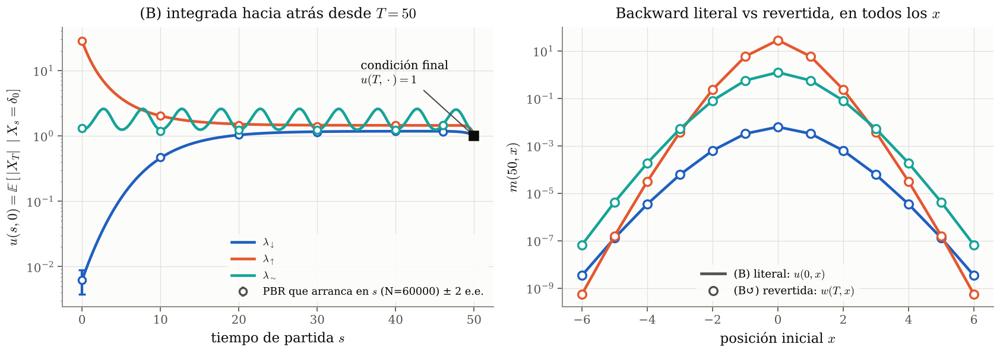

tiempo: 132.2 s


In [ ]:
# tres perfiles de λ(t); para cada uno se usa el a critico de su regimen final,
# asi el promedio converge a una constante en vez de irse a 0 o a infinito
T, x0 = 50.0, 0.0
lam_dn = lambda t: 0.2 + 1.8 * np.exp(-np.asarray(t) / 5)
lam_up = lambda t: 2.0 - 1.8 * np.exp(-np.asarray(t) / 5)
lam_os = lambda t: 1.0 + 0.9 * np.sin(2 * np.pi * np.asarray(t) / 5)
perfiles = {      # nombre: (λ(t), a de referencia, etiqueta del a)
    r"$\lambda_\downarrow(t)=0.2+1.8e^{-t/5}$": (lam_dn, a_estrella_lam(0.2), r"a^*(\lambda_\infty{=}0.2)"),
    r"$\lambda_\uparrow(t)=2-1.8e^{-t/5}$":     (lam_up, a_estrella_lam(2.0), r"a^*(\lambda_\infty{=}2)"),
    r"$\lambda_\sim(t)=1+0.9\sin(2\pi t/5)$":    (lam_os, floquet_a(lam_os, 5.0), r"a^*_F(\tau{=}5)"),
}
for nombre, (lam_f, a_ref, tex_a) in perfiles.items():
    print(f"{nombre:<45}  a = {a_ref:.5f}")

# tiempos de partida s: grilla para la ecuacion y unos pocos puntos para el Monte Carlo
s_grid = np.linspace(0, T, 251)
s_mc = np.array([0.0, 10.0, 20.0, 30.0, 40.0, 46.0])
N = NN(60_000)
fig, axs = plt.subplots(1, 2, figsize=(15.5, 5.6))
t0 = time.time()
for j, (nombre, (lam_f, a_ref, tex_a)) in enumerate(perfiles.items()):
    xb, sb, U = fk_backward(lam_f, T, s_grid, a_ref)                    # (B) literal, de T hacia 0
    i0 = int(np.argmin(np.abs(xb - x0)))
    xr, wr = fk_backward_revertida(lam_f, T, a_ref)                     # (B↺)
    mF, _, _ = fk_forward(lam_f, T, np.array([T]), a_ref)               # (F)
    # Monte Carlo: PBR que arranca en el tiempo s con una particula en 0 y se observa en T
    # (se simula con el perfil desplazado r -> λ(s + r) durante un tiempo T - s)
    mc_s, se_s = [], []
    for i, s in enumerate(s_mc):
        tab_s = tabla_acumulada(lambda r, s=s: lam_f(s + r), T - s)
        tab_as = tabla_acumulada(lambda r: a_ref + 0 * r, T - s)
        m_, e_ = promedio_vivos_t(N, T - s, tab_s, tab_as, [x0], np.array([T - s]), seed=90_000 + 5000 * j + 500 * i)
        mc_s.append(m_[0]); se_s.append(e_[0])
    mc_s, se_s = np.array(mc_s), np.array(se_s)
    # las tres comprobaciones: contra Monte Carlo (z), contra la revertida y contra la forward
    z = (mc_s - np.interp(s_mc, sb, U[i0])) / se_s
    print(f"perfil {j+1}:  máx_x |B(0,x) - B↺(T,x)| = {np.max(np.abs(U[:, 0] - wr)):.1e};   "
          f"|B(0,0) - F| = {abs(U[i0, 0] - mF[-1]):.1e};   u(T,·) = {U[:, -1].min():.3f}..{U[:, -1].max():.3f};   "
          f"z de Monte Carlo en s={[int(v) for v in s_mc]}: " + " ".join(f"{v:+.1f}" for v in z))
    ax = axs[0]
    ax.plot(sb, U[i0], color=C[j], lw=3, label=nombre.split("(t)")[0] + "$")
    ax.errorbar(s_mc, mc_s, yerr=2 * se_s, fmt="o", color=C[j], ms=8, capsize=4, mfc="white", mew=2.2, zorder=4)
    ax = axs[1]
    sel = np.abs(xb) <= 6
    ax.plot(xb[sel], U[sel, 0], "-", color=C[j], lw=3)
    ax.plot(xr[sel], wr[sel], "o", color=C[j], ms=9, mfc="white", mew=2.2)
ax = axs[0]
ax.plot([T], [1.0], "s", color=TINTA, ms=11, zorder=5)
ax.annotate("condición final\n$u(T,\\cdot)=1$", (T, 1.0), xytext=(-125, 58), textcoords="offset points", fontsize=13,
            arrowprops=dict(arrowstyle="->", color=TINTA2, lw=1.4))
ax.errorbar([], [], yerr=[], fmt="o", color=TINTA2, ms=8, mfc="white", mew=2.2, label=f"PBR que arranca en $s$ (N={N}) ± 2 e.e.")
ax.set(yscale="log", xlabel="tiempo de partida $s$", ylabel=r"$u(s,0)=\mathbb{E}\,[\,|X_T|\ \mid X_s=\delta_0]$",
       title=rf"(B) integrada hacia atrás desde $T={T:.0f}$")
ax.legend(loc="lower right", fontsize=11.5, frameon=True, framealpha=0.9, edgecolor="none")
ax = axs[1]
ax.plot([], [], "-", color=TINTA2, lw=3, label=r"(B) literal: $u(0,x)$")
ax.plot([], [], "o", color=TINTA2, ms=9, mfc="white", mew=2.2, label=r"(B↺) revertida: $w(T,x)$")
ax.set(yscale="log", xlabel="posición inicial $x$", ylabel=rf"$m({T:.0f},x)$", title="Backward literal vs revertida, en todos los $x$")
ax.legend(loc="lower center", fontsize=12, frameon=True, framealpha=0.9, edgecolor="none")
fig.tight_layout()
guardar(fig, "fig09a_backward"); plt.show()
print(f"tiempo: {time.time()-t0:.1f} s")

Las tres comprobaciones pasan: los puntos de Monte Carlo caen sobre la curva, y la backward coincide con la revertida en todos los $x$ (diferencia $\le10^{-8}$) y con la forward. O sea el código sí es la ecuación backward, y la revertida con $\lambda(T-\sigma)$ es la correcta.

**(b) Las cuatro ecuaciones en función de $T$.** Ahora graficamos $T\mapsto m(T,0)$. Para que la revertida salga como curva continua la resolvemos en 125 valores de $T$. También simulamos el PBR con el perfil invertido $\lambda(50-r)$, para confirmar que eso es lo que calcula (N).

perfil 1:  máx |F - B↺| = 7.7e-11;   m(50): PBR = 0.00585 ± 0.0019,  F = 0.006222,  B↺ = 0.006222,  N = 0.01171,  PBR invertido = 0.0114 ± 0.00092


perfil 2:  máx |F - B↺| = 5.5e-07;   m(50): PBR = 28.2 ± 0.44,  F = 28.46,  B↺ = 28.46,  N = 17.59,  PBR invertido = 18.16 ± 0.94


perfil 3:  máx |F - B↺| = 4.8e-09;   m(50): PBR = 1.247 ± 0.069,  F = 1.243,  B↺ = 1.243,  N = 1.68,  PBR invertido = 1.658 ± 0.064


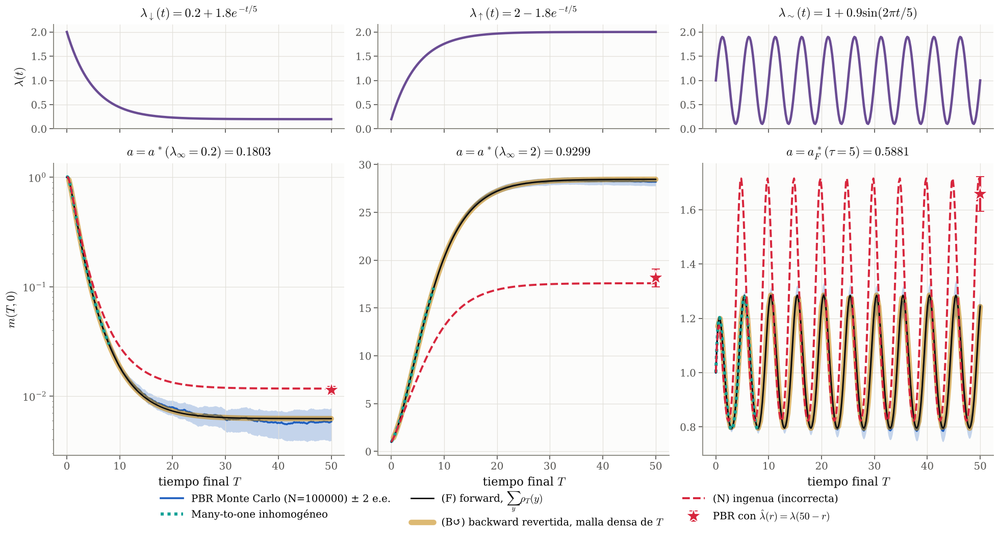

tiempo: 211.7 s


In [ ]:
# m(T, 0) en funcion del tiempo final T, calculado de todas las maneras
ts = np.linspace(0, T, 251); ts_m2o = np.linspace(0, 8, 81)
Ts_back = ts[2::2]                                        # malla densa de tiempos finales para (B↺): 125 valores
N, N2 = NN(100_000), NN(400_000)
fig, axs = plt.subplots(2, 3, figsize=(18, 9), gridspec_kw=dict(height_ratios=[1, 2.8]), sharex=True)
t0 = time.time()
for j, (nombre, (lam_f, a, tex_a)) in enumerate(perfiles.items()):
    tab_lam = tabla_acumulada(lam_f, T); tab_a = tabla_acumulada(lambda t: a + 0 * t, T)
    mc, se = promedio_vivos_t(N, T, tab_lam, tab_a, [x0], ts, seed=100_000 + 10_000 * j)
    m2, se2 = many_to_one_t(N2, 8.0, tab_lam, tab_a, x0, ts_m2o, seed=200_000 + 10_000 * j)
    mF, _, _ = fk_forward(lam_f, T, ts, a)                                 # (F): una sola EDO
    mB = np.empty(len(Ts_back))
    for i, TT in enumerate(Ts_back):                                       # (B↺): un problema por cada T
        xb, wb = fk_backward_revertida(lam_f, TT, a)
        mB[i] = wb[np.argmin(np.abs(xb - x0))]
    mN = fk_ingenua(lam_f, T, ts, a)                                       # (N)
    # PBR con el perfil invertido λ(T - r): es lo que en realidad calcula la ecuacion ingenua
    lam_inv = lambda r, lam_f=lam_f: lam_f(T - np.asarray(r))
    mcI, seI = promedio_vivos_t(N, T, tabla_acumulada(lam_inv, T), tab_a, [x0], np.array([T]), seed=300_000 + 10_000 * j)
    # arriba el perfil λ(t), abajo las curvas
    ax = axs[0, j]
    ax.plot(ts, lam_f(ts), color=C[6], lw=3)
    ax.set(title=nombre, ylim=(0, 2.15)); ax.set_ylabel(r"$\lambda(t)$" if j == 0 else "")
    ax = axs[1, j]
    ax.fill_between(ts, np.maximum(mc - 2 * se, 1e-6), mc + 2 * se, color=C[0], alpha=0.25, lw=0)
    h_mc, = ax.plot(ts, mc, color=C[0], lw=2.4)
    h_b, = ax.plot(Ts_back, mB, color=C[3], lw=7, alpha=0.55, solid_capstyle="round")
    h_f, = ax.plot(ts, mF, color=TINTA, lw=1.8)
    h_m2, = ax.plot(ts_m2o, m2, color=C[2], lw=4, ls=(0, (1, 1.2)))
    h_n, = ax.plot(ts, mN, color=C[7], lw=2.6, ls="--")
    h_i = ax.errorbar([T], mcI, yerr=2 * seI, fmt="*", color=C[7], ms=20, capsize=5, mec="white", mew=1.2, zorder=5)
    ax.set(yscale="log" if j == 0 else "linear", xlabel="tiempo final $T$", title=rf"$a={tex_a}={a:.4f}$")
    ax.set_ylabel(r"$m(T,0)$" if j == 0 else "")
    print(f"perfil {j+1}:  máx |F - B↺| = {np.max(np.abs(mF[2::2] - mB)):.1e};   "
          f"m(50): PBR = {mc[-1]:.4g} ± {2*se[-1]:.2g},  F = {mF[-1]:.4g},  B↺ = {mB[-1]:.4g},  "
          f"N = {mN[-1]:.4g},  PBR invertido = {mcI[0]:.4g} ± {2*seI[0]:.2g}")
fig.legend([h_mc, h_m2, h_f, h_b, h_n, h_i],
           [f"PBR Monte Carlo (N={N}) ± 2 e.e.", "Many-to-one inhomogéneo", r"(F) forward, $\sum_y\rho_T(y)$",
            "(B↺) backward revertida, malla densa de $T$", "(N) ingenua (incorrecta)", r"PBR con $\hat\lambda(r)=\lambda(50-r)$"],
           loc="lower center", ncol=3, fontsize=13, frameon=False, bbox_to_anchor=(0.5, -0.075))
fig.tight_layout()
guardar(fig, "fig09_lambda_t_validacion"); plt.show()
print(f"tiempo: {time.time()-t0:.1f} s")

- (F) y (B↺) coinciden (diferencia $\le6\cdot10^{-7}$) y las dos coinciden con el Monte Carlo y con Many-to-one.
- (N) da otra curva: a $T=50$ da $17.6$ contra $28.5$ en el perfil creciente, y $0.0117$ contra $0.0062$ en el decreciente. Su valor coincide con el PBR de perfil invertido (la estrella).
- Con el $a$ crítico de cada régimen el promedio converge a una constante, o a un ciclo en el caso periódico.

### 3.5 $\lambda$ discontinua y no acotada

- **Escalón:** $\lambda=2$ hasta $t=5$ y $0.25$ después. Las EDOs se integran por tramos.
- **$\lambda(t)=1/\sqrt t$:** infinita en $t=0$, pero $\Lambda(t)=2\sqrt t$ es finita. Con el cambio de variable $\sigma=\Lambda(s)$ la ecuación forward queda sin singularidad: $\frac{d\rho}{d\sigma}=L_1\rho+\frac\sigma2(a-x^2)\rho$.

Para el escalón usamos $a=a^*(0.25)$ y para $1/\sqrt t$ usamos $a=0.2$.

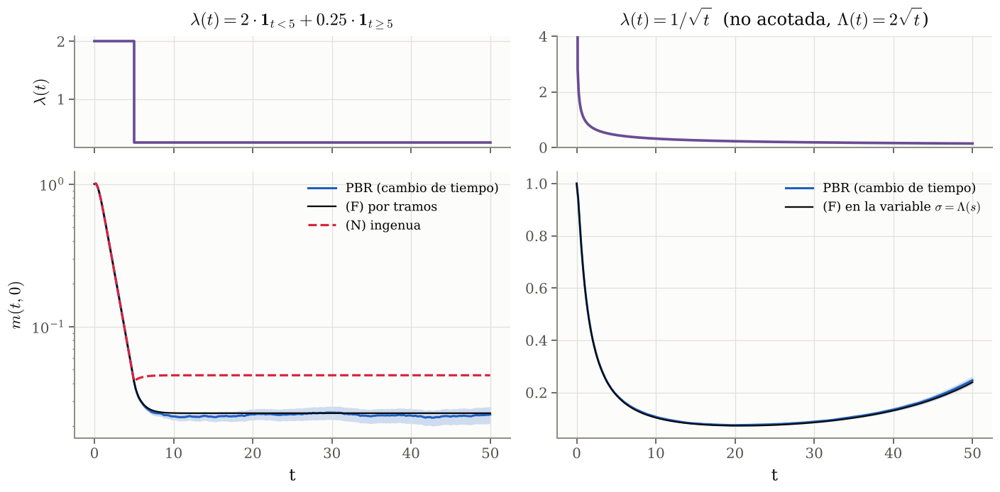

escalón (a=0.2196):   PBR(50) = 0.024 ± 0.003,  (F) = 0.0247,  (N) = 0.0456
singular (a=0.2):  máx |PBR - F|/e.e. = 2.73


In [ ]:
T = 50.0; ts = np.linspace(0, T, 251)
a_esc = a_estrella_lam(0.25)      # critico del regimen final del escalon (λ = 0.25)
a_sing = 0.2                      # λ = 1/√t no tiene critico constante (seccion 3.6); 0.2 mantiene el promedio de orden 1 en [0, 50]
N = NN(200_000)
fig, axs = plt.subplots(2, 2, figsize=(13, 6.5), gridspec_kw=dict(height_ratios=[1, 2.4]), sharex=True)

# (i) escalon: λ = 2 hasta t = 5 y 0.25 despues. La primitiva es exacta y las EDOs se reinician en t = 5
lam_esc = lambda t: np.where(np.asarray(t) < 5.0, 2.0, 0.25)
tab = tabla_acumulada(F=lambda t: np.where(t < 5.0, 2.0 * t, 10.0 + 0.25 * (t - 5.0)), T=T)
mc, se = promedio_vivos_t(N, T, tab, tabla_acumulada(lambda t: a_esc + 0 * t, T), [0.0], ts, seed=400_000)
mc_esc, se_esc = mc, se
mF, _, _ = fk_forward(lambda t: 2.0 if t < 5.0 else 0.25, T, ts, a_esc, cortes=[5.0])
mN = fk_ingenua(lambda t: 2.0 if t < 5.0 else 0.25, T, ts, a_esc, cortes=[5.0])
axs[0, 0].plot(ts, lam_esc(ts), color=C[6], lw=2.4, drawstyle="steps-post")
axs[0, 0].set(title=r"$\lambda(t)=2\cdot\mathbf{1}_{t<5}+0.25\cdot\mathbf{1}_{t\geq 5}$", ylabel=r"$\lambda(t)$")
ax = axs[1, 0]
ax.fill_between(ts, mc - 2 * se, mc + 2 * se, color=C[0], alpha=0.2, lw=0)
ax.plot(ts, mc, color=C[0], lw=2, label="PBR (cambio de tiempo)")
ax.plot(ts, mF, color=TINTA, lw=1.5, label="(F) por tramos")
ax.plot(ts, mN, color=C[7], lw=2.1, ls="--", label="(N) ingenua")
ax.set(yscale="log", xlabel="t", ylabel=r"$m(t,0)$"); ax.legend(fontsize=11.5)

# (ii) λ = 1/√t: no es acotada, pero su integral Λ(t) = 2√t es finita y el cambio de tiempo funciona igual
M = 200_001
tg = np.linspace(0, np.sqrt(T * (1 + 1e-9)), M)**2          # malla refinada cerca de 0
tab = (tg, 2.0 * np.sqrt(tg))                                # Λ(t) = 2√t exacta en los nodos
mc, se = promedio_vivos_t(N, T, tab, tabla_acumulada(lambda t: a_sing + 0 * t, T), [0.0], ts, seed=500_000)
x, L1, P = matrices_caja(15.0)
r0 = np.zeros(len(x)); r0[np.argmin(np.abs(x))] = 1.0
# para la EDO se cambia de variable a σ = Λ(s) = 2√s, que quita la singularidad:
# dρ/dσ = L1 ρ + (σ/2)(a - x²) ρ
sig_eval = 2 * np.sqrt(ts)
_, R = integrar(lambda sig: (1.0, sig / 2), L1, a_sing - P, r0, 0.0, sig_eval[-1], t_eval=sig_eval)
mF_sig = R.sum(axis=0)
tt_ = np.linspace(1e-3, T, 400)
axs[0, 1].plot(tt_, 1 / np.sqrt(tt_), color=C[6], lw=2.4)
axs[0, 1].set(title=r"$\lambda(t)=1/\sqrt{t}$  (no acotada, $\Lambda(t)=2\sqrt{t}$)", ylim=(0, 4))
ax = axs[1, 1]
ax.fill_between(ts, mc - 2 * se, mc + 2 * se, color=C[0], alpha=0.2, lw=0)
ax.plot(ts, mc, color=C[0], lw=2, label="PBR (cambio de tiempo)")
ax.plot(ts, mF_sig, color=TINTA, lw=1.5, label=r"(F) en la variable $\sigma=\Lambda(s)$")
ax.set(xlabel="t"); ax.legend(fontsize=11.5)
fig.tight_layout()
guardar(fig, "fig10_regularidad"); plt.show()
print(f"escalón (a={a_esc:.4f}):   PBR({T:.0f}) = {mc_esc[-1]:.3f} ± {2*se_esc[-1]:.3f},  (F) = {mF[-1]:.4f},  (N) = {mN[-1]:.4f}")
print(f"singular (a={a_sing}):  máx |PBR - F|/e.e. = {np.max(np.abs(mc[1:] - mF_sig[1:]) / np.maximum(se[1:], 1e-12)):.2f}")

En los dos casos el PBR coincide con (F). En el escalón (N) da $0.046$ contra $0.025$.

### 3.6 Estabilización

**(a) Siempre hay un $a(t)$ que deja el promedio constante.** Si $\nu_t$ es la solución de (F) con $a=0$ normalizada a suma 1, basta tomar

$$a(t)=\langle p,\nu_t\rangle=\sum_yy^2\,\nu_t(y),$$

o sea que los nacimientos compensen la tasa media de muerte. Con $\lambda$ constante $a(t)\to a^*$.

**(b) Si $\lambda(t)\to\lambda_\infty$**, el crítico es el del problema límite, $a^*(\lambda_\infty)$.

**(c) Si $\lambda$ es periódica** de período $\tau$, el crítico es el de Floquet, $a^*_F=-\frac1\tau\log r(U_\tau)$, donde $U_\tau$ es el propagador en un período. En $a=a^*_F$ el promedio converge a un ciclo, y

$$\frac1\tau\int_0^\tau a^*(\lambda(t))\,dt\ \le\ a^*_F\ \le\ a^*(\bar\lambda).$$

**(d) Si $\lambda\to\infty$ o $\int_0^\infty\lambda<\infty$**, no hay $a^*$ constante y solo sirve $a(t)$.

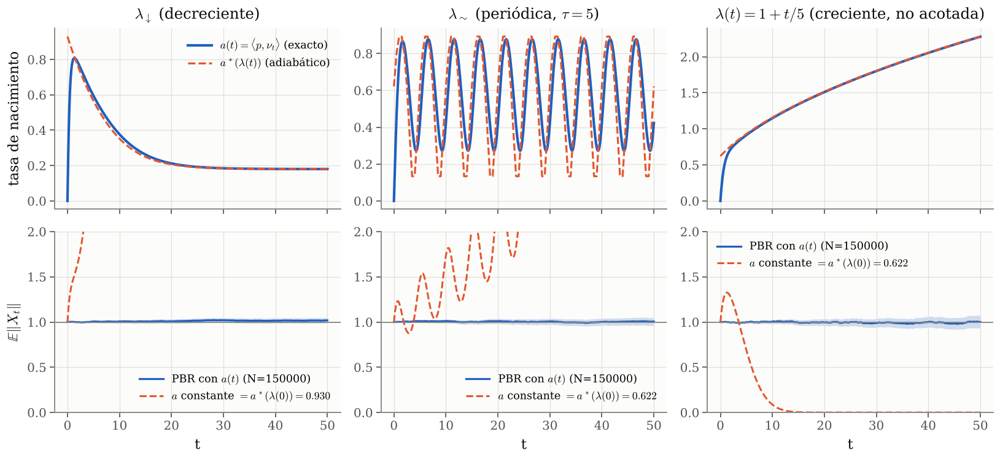

In [ ]:
# tres perfiles: uno que converge, uno periodico y uno que crece sin cota
T = 50.0; tsd = np.linspace(0, T, 5001)
perf_estab = {
    r"$\lambda_\downarrow$ (decreciente)": lambda t: 0.2 + 1.8 * np.exp(-np.asarray(t) / 5),
    r"$\lambda_\sim$ (periódica, $\tau=5$)": lambda t: 1.0 + 0.9 * np.sin(2 * np.pi * np.asarray(t) / 5),
    r"$\lambda(t)=1+t/5$ (creciente, no acotada)": lambda t: 1.0 + np.asarray(t) / 5,
}
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
N = NN(150_000); ts = np.linspace(0, T, 251)
# a(t) que deja el promedio constante: a(t) = <p, ν_t>, la tasa media de muerte bajo ν_t,
# donde ν_t es la solucion de (F) con a = 0 normalizada a suma 1
# se integra por tramos renormalizando (ν_t no cambia al escalar) para no perder precision
def a_estabilizadora(lam_f, T, tgrid, x0=0.0, p=p_cuadrado, ell=15.0, tramo=1.0):
    x, L1, P = matrices_caja(ell, p)
    r = np.zeros(len(x)); r[np.argmin(np.abs(x - x0))] = 1.0
    out = np.empty(len(tgrid)); t_ini = 0.0
    while t_ini < T - 1e-12:
        t_fin = min(T, t_ini + tramo)
        sel = (tgrid >= t_ini) & (tgrid <= t_fin)
        te = np.union1d(tgrid[sel], [t_fin])
        _, R = integrar(lambda s: (float(lam_f(s)), 1.0), L1, -P, r, t_ini, t_fin, t_eval=te)
        Rn = R / R.sum(axis=0)
        out[sel] = (P @ Rn)[np.isin(te, tgrid[sel])]
        r = Rn[:, -1]; t_ini = t_fin
    return out

for j, (nombre, lam_f) in enumerate(perf_estab.items()):
    a_t = a_estabilizadora(lam_f, T, tsd)                           # a(t) = <p, ν_t>
    a_ad = np.array([a_estrella_lam(lam_f(t)) for t in tsd[::50]])  # adiabatico: a*(λ(t))
    ax = axs[0, j]
    ax.plot(tsd, a_t, color=C[0], lw=2.7, label=r"$a(t)=\langle p,\nu_t\rangle$ (exacto)")
    ax.plot(tsd[::50], a_ad, color=C[1], lw=2.1, ls="--", label=r"$a^*(\lambda(t))$ (adiabático)")
    ax.set(title=nombre, ylabel="tasa de nacimiento" if j == 0 else None)
    if j == 0: ax.legend(fontsize=11.5)
    # Monte Carlo del PBR con ese a(t): se arma la tabla acumulada de a por trapecios
    tgA = tsd; AG = np.concatenate([[0.0], np.cumsum(0.5 * (a_t[1:] + a_t[:-1]) * np.diff(tsd))])
    tgA = np.append(tgA, T * (1 + 1e-9) + 1e-9); AG = np.append(AG, AG[-1] + a_t[-1] * (tgA[-1] - T))
    mc, se = promedio_vivos_t(N, T, tabla_acumulada(lam_f, T), (tgA, AG), [0.0], ts, seed=600_000 + 10_000 * j)
    ax = axs[1, j]
    ax.fill_between(ts, mc - 2 * se, mc + 2 * se, color=C[0], alpha=0.2, lw=0)
    ax.plot(ts, mc, color=C[0], lw=2.1, label=f"PBR con $a(t)$ (N={N})")
    # para comparar: con a constante (el critico de λ(0)) el promedio no se queda en 1
    a_cte = a_estrella_lam(lam_f(0.0))
    mF_cte, _, _ = fk_forward(lam_f, T, ts, a=a_cte)
    ax.plot(ts, mF_cte, color=C[1], lw=2, ls="--", label=rf"$a$ constante $=a^*(\lambda(0))={a_cte:.3f}$")
    ax.axhline(1.0, color=GRIS, lw=1.2)
    ax.set(xlabel="t", ylabel=r"$\mathbb{E}\|X_t\|$" if j == 0 else None, ylim=(0, 2.0))
    ax.legend(fontsize=11.5, loc="upper left" if j == 2 else "lower right")
fig.tight_layout()
guardar(fig, "fig11_a_de_t"); plt.show()

Arriba: el $a(t)$ exacto parte de $0$ y sigue con algo de retardo al valor $a^*(\lambda(t))$. Abajo: con ese $a(t)$ el promedio simulado se queda en $1$, y con $a$ constante se va a $0$ o a infinito.

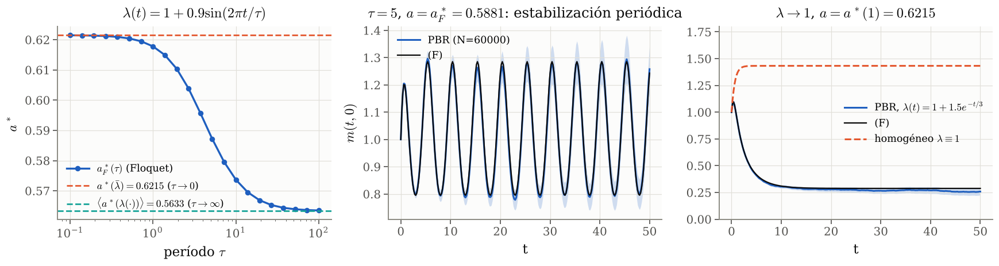

a*(λ̄) = 0.62151,  <a*(λ(·))> = 0.56334,  a*_F(τ=5) = 0.58810
λ→1: m(50) = 0.2877 (vs 1.4328 homogéneo)


In [ ]:
# (a) critico de Floquet en funcion del periodo, con sus dos limites: periodo corto (a* de la tasa media)
# y periodo largo (promedio de a*(λ(t)) sobre un periodo)
eps = 0.9
taus = np.logspace(-1, 2, 22)
aF = [floquet_a(lambda t, tau=tau: 1 + eps * np.sin(2 * np.pi * t / tau), tau) for tau in taus]
a_bar = a_estrella_lam(1.0)
fase = np.linspace(0, 1, 801)[:-1]
a_adiab = np.mean([a_estrella_lam(1 + eps * np.sin(2 * np.pi * f)) for f in fase])

fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axs[0]
ax.plot(taus, aF, "o-", color=C[0], ms=5.2, lw=2.2, label=r"$a^*_F(\tau)$ (Floquet)")
ax.axhline(a_bar, color=C[1], lw=1.8, ls="--", label=rf"$a^*(\bar\lambda)={a_bar:.4f}$ ($\tau\to0$)")
ax.axhline(a_adiab, color=C[2], lw=1.8, ls="--", label=rf"$\langle a^*(\lambda(\cdot))\rangle={a_adiab:.4f}$ ($\tau\to\infty$)")
ax.set(xscale="log", xlabel=r"período $\tau$", ylabel="$a^*$", title=r"$\lambda(t)=1+0.9\sin(2\pi t/\tau)$")
ax.legend(fontsize=11.5)

# (b) m(t) en a = a*_F para τ = 5: el promedio no converge a una constante sino a un ciclo
tau = 5.0; lam_f = lambda t: 1 + eps * np.sin(2 * np.pi * np.asarray(t) / tau)
aF5 = floquet_a(lam_f, tau)
T = 50.0; ts = np.linspace(0, T, 251); N = NN(60_000)
mc, se = promedio_vivos_t(N, T, tabla_acumulada(lam_f, T), tabla_acumulada(lambda t: aF5 + 0 * t, T), [0.0], ts, seed=700_000)
mF, _, _ = fk_forward(lam_f, T, ts, a=aF5)
ax = axs[1]
ax.fill_between(ts, mc - 2 * se, mc + 2 * se, color=C[0], alpha=0.2, lw=0)
ax.plot(ts, mc, color=C[0], lw=2, label=f"PBR (N={N})")
ax.plot(ts, mF, color=TINTA, lw=1.5, label="(F)")
ax.set(xlabel="t", ylabel=r"$m(t,0)$", title=rf"$\tau=5$, $a=a^*_F={aF5:.4f}$: estabilización periódica")
ax.legend(fontsize=11.5)

# (c) λ(t) = 1 + 1.5 e^{-t/3} -> 1 con a = a*(1): se estabiliza, pero en otro nivel que el caso λ = 1
lam_c = lambda t: 1 + 1.5 * np.exp(-np.asarray(t) / 3)
mc, se = promedio_vivos_t(N, T, tabla_acumulada(lam_c, T), tabla_acumulada(lambda t: a_bar + 0 * t, T), [0.0], ts, seed=800_000)
mF, _, _ = fk_forward(lam_c, T, ts, a=a_bar)
mH = m_FK(ts, a_bar)
ax = axs[2]
ax.fill_between(ts, mc - 2 * se, mc + 2 * se, color=C[0], alpha=0.2, lw=0)
ax.plot(ts, mc, color=C[0], lw=2, label=r"PBR, $\lambda(t)=1+1.5e^{-t/3}$")
ax.plot(ts, mF, color=TINTA, lw=1.5, label="(F)")
ax.plot(ts, mH, color=C[1], lw=2, ls="--", label=r"homogéneo $\lambda\equiv1$")
ax.set(xlabel="t", title=rf"$\lambda\to1$, $a=a^*(1)={a_bar:.4f}$", ylim=(0, 1.8))
ax.legend(fontsize=11.5, loc="center right")
fig.tight_layout()
guardar(fig, "fig12_floquet"); plt.show()
print(f"a*(λ̄) = {a_bar:.5f},  <a*(λ(·))> = {a_adiab:.5f},  a*_F(τ=5) = {aF5:.5f}")
print(f"λ→1: m({T:.0f}) = {mF[-1]:.4f} (vs {mH[-1]:.4f} homogéneo)")

Para $\lambda(t)=1+0.9\sin(2\pi t/\tau)$ el crítico de Floquet va de $0.6215$ (períodos cortos) a $0.5633$ (períodos largos); con $\tau=5$ da $0.5881$. En el caso $\lambda\to1$ el promedio se estabiliza en $0.288$ en vez de $1.43$: el nivel depende del transitorio.

### 3.7 Respuesta a la Pregunta 2

- La EDO de la sección 1 con $\lambda(t)$ en vez de $\lambda$ ya no calcula $m(t,x)$.
- Many-to-one se mantiene, con el paseo de tasa $\lambda(t)$.
- Feynman–Kac se mantiene como problema con condición final (B). La revertida lleva $\lambda(T-\sigma)$ y hay que resolverla para cada $T$; la forward da toda la curva de una vez.
- Basta que $\lambda$ sea integrable en cada intervalo: sirven escalones y $1/\sqrt t$.
- Siempre hay un $a(t)$ que estabiliza. Hay un $a^*$ constante si $\lambda$ converge o es periódica.

---
## 4. Pregunta 3: dimensión $d$

Ahora $\mathbf x\in h\mathbb Z^d$, $\alpha(\mathbf x)=a+\|\mathbf x\|^2$, $p_0=\frac{\|\mathbf x\|^2}{a+\|\mathbf x\|^2}$, $p_2=\frac{a}{a+\|\mathbf x\|^2}$, y la partícula salta a tasa $\lambda$ a uno de sus $2d$ vecinos.

El paseo en $\mathbb Z^d$ es lo mismo que $d$ paseos 1D independientes, uno por coordenada, cada uno de tasa $\lambda/d$. Como además $\|\mathbf x\|^2=\sum_ix_i^2$, todo se separa:

$$m_d(t,\mathbf x)=e^{at}\prod_{i=1}^dq(t,x_i),\qquad q(t,y)=\mathbb E_y\Big[e^{-\int_0^tZ_s^2ds}\Big]\ \text{con } Z \text{ de tasa } \lambda/d,$$

y entonces

$$\boxed{\ a^*_d(\lambda)=d\cdot a^*_1\!\Big(\frac{\lambda}{d}\Big)\ }$$

donde $a^*_1(\kappa)$ es el crítico en una dimensión con tasa $\kappa$.

- $a^*_d$ crece con $d$: $0.6215,\ 0.7724,\ 0.8407,\ 0.8782,\ldots$
- $a^*_d<\lambda$ y $a^*_d\to\lambda$, con $a^*_d=\lambda-\frac{\lambda^2}{2d}+\frac{7\lambda^4}{32d^3}+\ldots$
- La interpretación: el origen es el único sitio donde no se muere. En dimensión alta, si la partícula sale casi nunca vuelve, así que para sobrevivir hay que no moverse y eso cuesta $\lambda$.

### 4.1 Cálculo de $a^*_d$

Lo calculamos con la fórmula y lo comprobamos armando directamente el operador en $\mathbb Z^d$ (sin usar la separación) para $d\le4$.

In [ ]:
# critico en dimension d: a*_d = d * a*_1(λ/d), y el nivel donde se estabiliza el promedio, c_d = c_1(λ/d)^d
# (cada coordenada es un paseo 1D independiente de tasa λ/d)
def a_estrella_d(d, lam=1.0, h=1.0, ell=20.0):
    Lam1, phi, x = autopar_principal(p_cuadrado, lam=lam / d, h=h, L=ell)
    i0 = np.argmin(np.abs(x))
    c1 = phi[i0] * phi.sum()
    return -d * Lam1, c1**d

# generador L_d - ||x||^2 en la caja {-ell..ell}^d (Dirichlet), armado sitio por sitio
def operador_d_directo(d, ell, lam=1.0, h=1.0):
    K = int(ell); n1 = 2 * K + 1; N = n1**d
    idx = np.arange(N)
    coords = np.stack(np.unravel_index(idx, (n1,) * d), axis=1) - K        # (N, d) enteros
    # diagonal: -λ - ||x||²; cada uno de los 2d vecinos entra con λ/(2d)
    diag = -lam - (h * coords.astype(float))**2 @ np.ones(d)
    rows, cols, vals = [idx], [idx], [diag]
    for i in range(d):
        for s in (+1, -1):
            nb = coords.copy(); nb[:, i] += s
            # los vecinos fuera de la caja se descartan (Dirichlet)
            ok = np.abs(nb[:, i]) <= K
            j = np.ravel_multi_index(tuple((nb[ok] + K).T), (n1,) * d)
            rows.append(idx[ok]); cols.append(j); vals.append(np.full(ok.sum(), lam / (2 * d)))
    return sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(N, N))

# tabla: formula de separacion, operador d-dimensional directo (d <= 4) y expansion en 1/d
print(f"{'d':>3} {'a*_d = d a*_1(λ/d)':>20} {'directo (eigsh)':>17} {'λ-λ²/2d+7λ⁴/32d³':>19} {'c_d':>8}")
filas = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, 20, 50, 100]:
    ad, cd = a_estrella_d(d)
    directo = ""
    if d <= 4:
        ell = {1: 20, 2: 10, 3: 7, 4: 5}[d]
        H = operador_d_directo(d, ell)
        directo = f"{-spla.eigsh(H, k=1, which='LA')[0][0]:.12f}"
    asin = 1 - 1 / (2 * d) + 7 / (32 * d**3)
    filas.append((d, ad, cd))
    print(f"{d:>3} {ad:20.12f} {directo:>17} {asin:19.6f} {cd:8.4f}")
print(f"e^λ = {np.e:.4f}")

  d   a*_d = d a*_1(λ/d)   directo (eigsh)    λ-λ²/2d+7λ⁴/32d³      c_d
  1       0.621510778736    0.621510778736            0.718750   1.4328
  2       0.772430697946    0.772430697946            0.777344   1.8061
  3       0.840699617193    0.840699617193            0.841435   2.0364
  4       0.878234455059    0.878234455059            0.878418   2.1801
  5       0.901688390253                              0.901750   2.2759
  6       0.917654302515                              0.917679   2.3435
  8       0.937921209049                              0.937927   2.4320
 10       0.950216759104                              0.950219   2.4870
 20       0.975027280997                              0.975027   2.6007
 50       0.990001749357                              0.990002   2.6709
100       0.995000218729                              0.995000   2.6945
e^λ = 2.7183


La construcción directa coincide con $d\,a^*_1(\lambda/d)$ en todas las cifras.

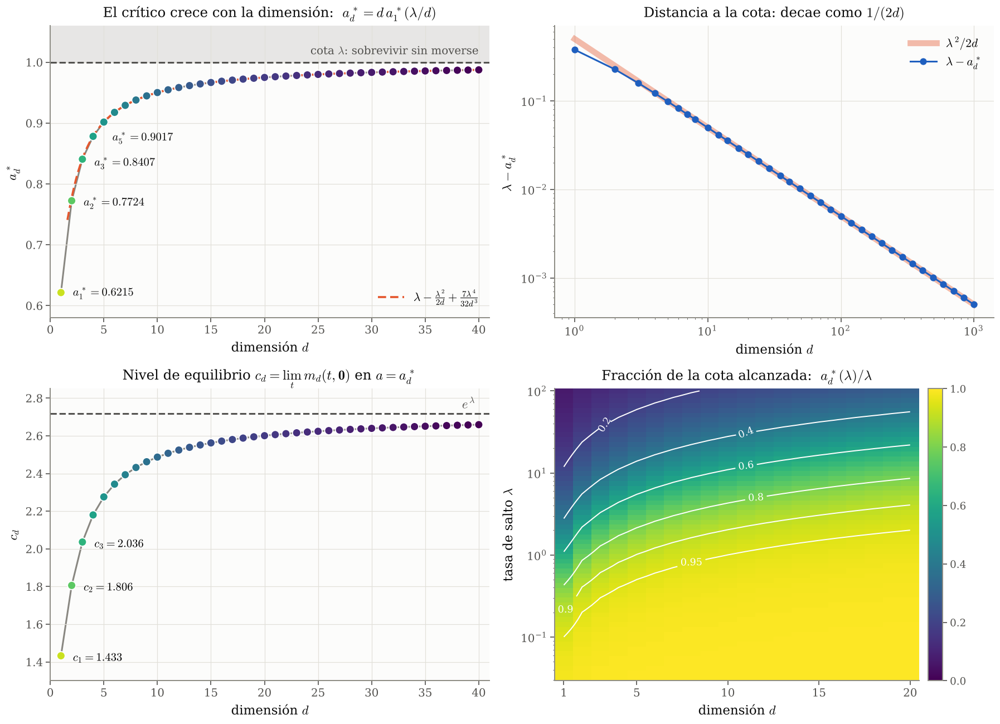

In [ ]:
# critico a*_d y nivel de equilibrio c_d para d = 1, ..., 40
ds = np.arange(1, 41)
ad = np.array([a_estrella_d(int(d))[0] for d in ds]); cd = np.array([a_estrella_d(int(d))[1] for d in ds])
cmap_d = mpl.colormaps["viridis"]; col_d = cmap_d(0.92 * (1 - np.log(ds) / np.log(ds[-1])))    # d chico = claro, d grande = oscuro

fig, axs = plt.subplots(2, 2, figsize=(16.5, 12))

# (A) el critico sube con la dimension y se satura en λ
ax = axs[0, 0]
ax.axhspan(1.0, 1.06, color=GRIS, alpha=0.18, lw=0)
ax.axhline(1.0, color=TINTA2, lw=2, ls="--")
ax.annotate(r"cota $\lambda$: sobrevivir sin moverse", (40, 1.008), ha="right", va="bottom", fontsize=13, color=TINTA2)
ax.plot(ds, ad, color=GRIS, lw=2, zorder=1)
ax.scatter(ds, ad, c=col_d, s=95, edgecolors="white", linewidths=1.2, zorder=3)
dd = np.linspace(1.6, 40, 300)
ax.plot(dd, 1 - 1 / (2 * dd) + 7 / (32 * dd**3), color=C[1], lw=2.4, ls=(0, (4, 2)), zorder=2,
        label=r"$\lambda-\frac{\lambda^2}{2d}+\frac{7\lambda^4}{32d^3}$")
for d_, (dx_, dy_) in zip([1, 2, 3, 5], [(14, -4), (14, -6), (14, -8), (10, -22)]):
    ax.annotate(rf"$a^*_{d_}={ad[d_-1]:.4f}$", (d_, ad[d_ - 1]), xytext=(dx_, dy_), textcoords="offset points", fontsize=13.5, color=TINTA)
ax.set(xlabel="dimensión $d$", ylabel=r"$a^*_d$", ylim=(0.58, 1.06), xlim=(0, 41),
       title=r"El crítico crece con la dimensión:  $a^*_d=d\,a^*_1(\lambda/d)$")
ax.legend(loc="lower right", fontsize=14)

# (B) cuanto falta para la cota: ley 1/(2d)
ax = axs[0, 1]
ds_l = np.unique(np.round(np.logspace(0, 3, 40)).astype(int))
gap = np.array([1.0 - a_estrella_d(int(d))[0] for d in ds_l])
ax.plot(ds_l, 1 / (2 * ds_l), color=C[1], lw=7, alpha=0.4, label=r"$\lambda^2/2d$")
ax.plot(ds_l, gap, "o-", color=C[0], ms=7, lw=2, label=r"$\lambda-a^*_d$")
ax.set(xscale="log", yscale="log", xlabel="dimensión $d$", ylabel=r"$\lambda-a^*_d$",
       title=r"Distancia a la cota: decae como $1/(2d)$")
ax.legend(loc="upper right", fontsize=14)

# (C) nivel de equilibrio del promedio
ax = axs[1, 0]
ax.axhline(np.e, color=TINTA2, lw=2, ls="--"); ax.annotate(r"$e^{\lambda}$", (40, np.e), xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=15, color=TINTA2)
ax.plot(ds, cd, color=GRIS, lw=2, zorder=1)
ax.scatter(ds, cd, c=col_d, s=95, edgecolors="white", linewidths=1.2, zorder=3)
for d_ in [1, 2, 3]:
    ax.annotate(rf"$c_{d_}={cd[d_-1]:.3f}$", (d_, cd[d_ - 1]), xytext=(14, -6), textcoords="offset points", fontsize=13.5)
ax.set(xlabel="dimensión $d$", ylabel=r"$c_d$", xlim=(0, 41), ylim=(1.3, 2.85),
       title=r"Nivel de equilibrio $c_d=\lim_t m_d(t,\mathbf{0})$ en $a=a^*_d$")

# (D) mapa de a*_d / λ en el plano (dimension, tasa de salto)
ax = axs[1, 1]
d_map = np.arange(1, 21); lam_map = np.logspace(-1.5, 2, 60)
Z = np.array([[-d * autopar_principal(p_cuadrado, lam=l / d, L=max(20.0, 3 * (l / d)**0.25 + 10))[0] / l for d in d_map] for l in lam_map])
im = ax.pcolormesh(d_map, lam_map, Z, cmap="viridis", vmin=0, vmax=1, shading="nearest", rasterized=True)
cs = ax.contour(d_map, lam_map, Z, levels=[0.2, 0.4, 0.6, 0.8, 0.9, 0.95], colors="white", linewidths=1.3)
ax.clabel(cs, fmt="%.2g", fontsize=11.5)
ax.grid(False)
ax.set(yscale="log", xlabel="dimensión $d$", ylabel=r"tasa de salto $\lambda$", xticks=[1, 5, 10, 15, 20],
       title=r"Fracción de la cota alcanzada:  $a^*_d(\lambda)/\lambda$")
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.ax.tick_params(labelsize=12)
fig.tight_layout()
guardar(fig, "fig13_a_estrella_dimension"); plt.show()

Arriba: $a^*_d$ sube rápido y se pega a la cota $\lambda$; lo que falta decae como $\lambda^2/(2d)$. Abajo a la izquierda: el nivel en que se estabiliza el promedio, $c_d$, crece hacia $e^\lambda$. Abajo a la derecha: $a^*_d(\lambda)/\lambda$ en función de $d$ y de $\lambda$.

### 4.2 Simulación del PBR en $\mathbb Z^d$

El mismo simulador, con las posiciones en $\mathbb Z^d$. Comparamos con la fórmula producto en $a=a^*_d$.

d=1: PBR(T)=1.440 ± 0.048,  FK = 1.433,  c_d = 1.433


d=2: PBR(T)=1.808 ± 0.067,  FK = 1.806,  c_d = 1.806


d=3: PBR(T)=2.070 ± 0.080,  FK = 2.036,  c_d = 2.036


d=5: PBR(T)=2.332 ± 0.095,  FK = 2.276,  c_d = 2.276


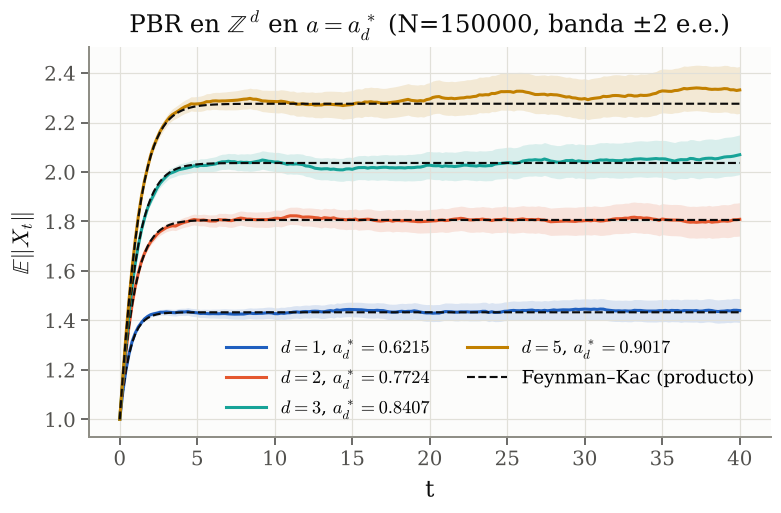

tiempo: 12.0 s


In [ ]:
# una realizacion del PBR en Z^d partiendo de una particula en el origen
# (igual que en 1D, pero el salto elige ademas una de las d coordenadas)
@njit
def _sim_d(T, a, lam, h, d, ts, out, out2):
    cap = 512
    pos = np.zeros((cap, d)); w = np.zeros(cap)          # todas parten en el origen
    n = 1; tasa_p = 0.0
    t = 0.0; k = 0; nts = ts.shape[0]
    while n > 0 and t <= T:
        tasa_alpha = a * n + tasa_p
        rate = tasa_alpha + lam * n
        t += np.random.exponential() / rate
        while k < nts and t >= ts[k]:
            out[k] += n; out2[k] += n * n
            k += 1
        if np.random.random() < lam * n / rate:                 # salto a uno de los 2d vecinos
            i = np.random.randint(n); j = np.random.randint(d)
            xo = pos[i, j]; xn = xo + (h if np.random.random() < 0.5 else -h)
            pos[i, j] = xn
            # la tasa de muerte ||x||² cambia solo por la coordenada que salto
            dw = xn * xn - xo * xo
            w[i] += dw; tasa_p += dw
        else:
            u = np.random.random() * tasa_alpha; acc = 0.0; i = n - 1
            for jj in range(n):
                acc += w[jj] + a
                if acc >= u:
                    i = jj; break
            px = w[i]
            if np.random.random() < px / (a + px):              # muere
                pos[i, :] = pos[n - 1, :]; w[i] = w[n - 1]; n -= 1; tasa_p -= px
            else:                                               # dos hijos
                if n == cap:
                    cap *= 2
                    pos2 = np.zeros((cap, d)); w2 = np.zeros(cap)
                    pos2[:n] = pos[:n]; w2[:n] = w[:n]; pos = pos2; w = w2
                pos[n, :] = pos[i, :]; w[n] = px; n += 1; tasa_p += px

# promedio de N realizaciones en bloques paralelos
@njit(parallel=True)
def _promedio_d(N, T, a, lam, h, d, ts, nchunks, seed):
    acc = np.zeros((nchunks, ts.shape[0])); acc2 = np.zeros((nchunks, ts.shape[0]))
    per = N // nchunks
    for c in prange(nchunks):
        np.random.seed(seed + c)
        m = per + (1 if c < N - per * nchunks else 0)
        for r in range(m):
            _sim_d(T, a, lam, h, d, ts, acc[c], acc2[c])
    return acc.sum(axis=0) / N, acc2.sum(axis=0) / N

# E|X_t| y su error estandar en dimension d
def promedio_vivos_d(N, T, a, d, ts, lam=1.0, h=1.0, seed=0):
    m1, m2 = _promedio_d(int(N), float(T), float(a), float(lam), float(h), int(d), np.asarray(ts, float), NCHUNKS, seed)
    return _media_y_se(m1, m2, N)

# m_d(t, 0) = e^{at} q^{(λ/d)}(t, 0)^d  (separacion de variables)
def m_FK_d(ts, a, d, lam=1.0):
    return np.exp(a * np.asarray(ts)) * m_FK(ts, 0.0, lam=lam / d)**d

# en cada dimension se usa su propio critico a*_d; el promedio deberia quedarse en c_d
T = 40.0; ts = np.linspace(0, T, 201); N = NN(150_000)
fig, ax = plt.subplots(figsize=(8, 4.6))
t0 = time.time()
for i, d in enumerate([1, 2, 3, 5]):
    a_d = a_estrella_d(d)[0]
    mc, se = promedio_vivos_d(N, T, a_d, d, ts, seed=900_000 + 10_000 * d)
    ax.fill_between(ts, mc - 2 * se, mc + 2 * se, color=C[i], alpha=0.15, lw=0)
    ax.plot(ts, mc, color=C[i], lw=2, label=rf"$d={d}$, $a^*_d={a_d:.4f}$")
    ax.plot(ts, m_FK_d(ts, a_d, d), color=TINTA, lw=1.4, ls="--")
    print(f"d={d}: PBR(T)={mc[-1]:.3f} ± {2*se[-1]:.3f},  FK = {m_FK_d([T], a_d, d)[0]:.3f},  c_d = {a_estrella_d(d)[1]:.3f}")
ax.plot([], [], color=TINTA, lw=1.4, ls="--", label="Feynman–Kac (producto)")
ax.set(xlabel="t", ylabel=r"$\mathbb{E}\|X_t\|$", title=rf"PBR en $\mathbb{{Z}}^d$ en $a=a^*_d$ (N={N}, banda ±2 e.e.)")
ax.legend(loc="lower right", ncol=2)
guardar(fig, "fig14_pbr_dimension"); plt.show()
print(f"tiempo: {time.time()-t0:.1f} s")

Cada dimensión se estabiliza en su $c_d$ usando su propio $a^*_d$.

### 4.3 Las tres vías en $d=2$ y $d=3$

Falta ver que Many-to-one también da lo mismo en dimensión $d$. Comparamos:

- Monte Carlo del sistema de partículas;
- Many-to-one directo (un paseo en $\mathbb Z^d$ con peso), solo hasta $t=8$ por la varianza;
- Many-to-one con la transformada de Doob, que llega hasta $t=40$;
- Feynman–Kac con el operador $d$-dimensional completo, sin separar variables.

d=2:  γ_d = 0.667  (varianza relativa del Many-to-one directo ≈ e^(γ_d t): 207 en t=8, 3.8e+11 en t=40)
   t=8:  PBR = 1.808 ± 0.029 | M2O directo = 1.837 ± 0.036 | M2O+Doob = 1.793 ± 0.013 | FK directo = 1.8060
   t=40:  PBR = 1.837 ± 0.069 | M2O+Doob = 1.814 ± 0.037 | FK directo = 1.8061
   máx |FK directo - fórmula producto| = 2.1e-13


d=3:  γ_d = 0.764  (varianza relativa del Many-to-one directo ≈ e^(γ_d t): 450 en t=8, 1.9e+13 en t=40)
   t=8:  PBR = 2.047 ± 0.034 | M2O directo = 2.019 ± 0.052 | M2O+Doob = 2.046 ± 0.045 | FK directo = 2.0362
   t=40:  PBR = 2.043 ± 0.079 | M2O+Doob = 2.032 ± 0.023 | FK directo = 2.0364
   máx |FK directo - fórmula producto| = 1.5e-12


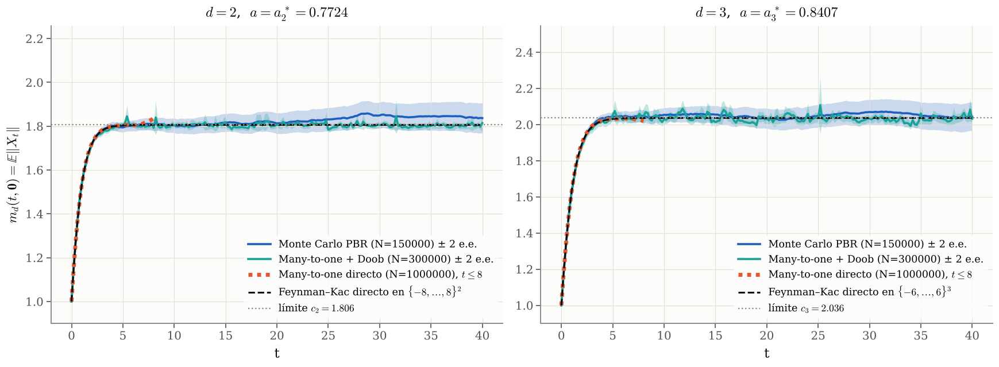

tiempo: 10.1 s


In [ ]:
# Many-to-one directo en Z^d: un solo paseo que parte del origen, con peso exp(∫_0^t (a - ||Z_s||²) ds)
@njit(parallel=True)
def _m2o_d(N, a, lam, h, d, ts, nchunks, seed):
    nts = ts.shape[0]; T = ts[-1]
    acc = np.zeros((nchunks, nts)); acc2 = np.zeros((nchunks, nts))
    per = N // nchunks
    for c in prange(nchunks):
        np.random.seed(seed + c)
        m = per + (1 if c < N - per * nchunks else 0)
        pos = np.zeros(d)
        for r in range(m):
            pos[:] = 0.0; r2 = 0.0; t = 0.0; w = 0.0; k = 0
            while k < nts:
                t_sig = t + np.random.exponential() / lam
                # r2 lleva ||Z||² actualizado; entre saltos el potencial es constante
                V = a - r2
                while k < nts and ts[k] <= t_sig:
                    W = math.exp(w + V * (ts[k] - t))
                    acc[c, k] += W; acc2[c, k] += W * W
                    k += 1
                w += V * (t_sig - t); t = t_sig
                j = np.random.randint(d)                        # coordenada uniforme, signo uniforme
                xo = pos[j]; xn = xo + (h if np.random.random() < 0.5 else -h)
                pos[j] = xn; r2 += xn * xn - xo * xo
    return acc.sum(axis=0) / N, acc2.sum(axis=0) / N

# cadena de Doob en Z^d. El estado fundamental es el producto de los de cada coordenada, asi que
# cada coordenada salta con las tasas 1D (up, dn); se simulan todas juntas y se promedia Π_i 1/φ0(Z^i_t)
@njit(parallel=True)
def _doob_d(N, d, ts, up, dn, invphi, i0, nchunks, seed):
    nts = ts.shape[0]; T = ts[-1]
    acc = np.zeros((nchunks, nts)); acc2 = np.zeros((nchunks, nts))
    per = N // nchunks
    for c in prange(nchunks):
        np.random.seed(seed + c)
        m = per + (1 if c < N - per * nchunks else 0)
        idx = np.empty(d, np.int64)
        for r in range(m):
            idx[:] = i0; t = 0.0; k = 0
            while k < nts:
                # tasa total de salto y valor de Π 1/φ0 en el estado actual
                rate = 0.0; G = 1.0
                for j in range(d):
                    rate += up[idx[j]] + dn[idx[j]]; G *= invphi[idx[j]]
                t_sig = t + np.random.exponential() / rate
                while k < nts and ts[k] <= t_sig:
                    acc[c, k] += G; acc2[c, k] += G * G
                    k += 1
                if t_sig > T:
                    break
                t = t_sig
                # se elige que coordenada salta y hacia donde, con probabilidad proporcional a su tasa
                u = np.random.random() * rate; s = 0.0
                for j in range(d):
                    s += up[idx[j]]
                    if u < s:
                        idx[j] += 1; break
                    s += dn[idx[j]]
                    if u < s:
                        idx[j] -= 1; break
    return acc.sum(axis=0) / N, acc2.sum(axis=0) / N

# interfaz del Many-to-one directo (media y error estandar)
def many_to_one_d(N, T, a, d, ts, lam=1.0, h=1.0, seed=0):
    m1, m2 = _m2o_d(int(N), float(a), float(lam), float(h), int(d), np.asarray(ts, float), NCHUNKS, seed)
    return _media_y_se(m1, m2, N)

# Many-to-one con Doob en dimension d:  m_d(t, 0) = e^{(a - a*_d) t} φ0(0)^d E[ Π_i 1/φ0(Z^i_t) ]
def many_to_one_doob_d(N, a, d, ts, lam=1.0, h=1.0, L=8.0, seed=0):
    Lam1, phi, x = autopar_principal(p_cuadrado, lam / d, h, L)       # problema 1D con tasa λ/d
    n = len(x); up = np.zeros(n); dn = np.zeros(n)
    up[:-1] = lam / (2 * d) * phi[1:] / phi[:-1]
    dn[1:] = lam / (2 * d) * phi[:-1] / phi[1:]
    i0 = int(np.argmin(np.abs(x))); ts = np.asarray(ts, float)
    m1, m2 = _doob_d(int(N), int(d), ts, up, dn, 1.0 / phi, i0, NCHUNKS, seed)
    f = np.exp((a + d * Lam1) * ts) * phi[i0]**d
    E, se = _media_y_se(m1, m2, N)
    return f * E, f * se

# Feynman-Kac en la caja {-ell..ell}^d sin usar la separacion de variables:
# m(t, 0) = [e^{t(H_d + a)} 1](0), con el operador d-dimensional completo (ts debe ser una grilla uniforme)
def m_FK_d_directo(ts, a, d, ell, lam=1.0):
    H = operador_d_directo(d, ell, lam) + a * sp.identity((2 * int(ell) + 1)**d, format="csr")
    Y = spla.expm_multiply(H, np.ones(H.shape[0]), start=ts[0], stop=ts[-1], num=len(ts), endpoint=True)
    return Y[:, H.shape[0] // 2]                                         # el origen es el sitio central

# comparacion de las tres vias en d = 2 y d = 3, cada una en su critico a*_d
# el Many-to-one directo solo se muestra hasta t = 8 por su varianza
T, Tm = 40.0, 8.0
ts = np.linspace(0, T, 201); tsm = ts[ts <= Tm + 1e-9]
N, Nm, Nd = NN(150_000), NN(1_000_000), NN(300_000)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
t0 = time.time()
for ax, d, ell in zip(axs, [2, 3], [8, 6]):
    a_d = a_estrella_d(d)[0]
    mc, se = promedio_vivos_d(N, T, a_d, d, ts, seed=1_100_000 + 10_000 * d)
    m2, s2 = many_to_one_d(Nm, Tm, a_d, d, tsm, seed=1_200_000 + 10_000 * d)
    md, sd = many_to_one_doob_d(Nd, a_d, d, ts, seed=1_300_000 + 10_000 * d)
    fk = m_FK_d_directo(ts, a_d, d, ell)
    fk_prod = m_FK_d(ts, a_d, d)
    # exponente con que crece la varianza relativa del Many-to-one directo: γ_d = Λ(2p) - 2Λ(p)
    H2 = operador_d_directo(d, ell); pd2 = -(H2.diagonal() + 1.0)          # ||x||² en cada sitio
    gam = (spla.eigsh(H2 - sp.diags(pd2), k=1, which="LA")[0][0] - 2 * spla.eigsh(H2, k=1, which="LA")[0][0])
    ax.fill_between(ts, mc - 2 * se, mc + 2 * se, color=C[0], alpha=0.22, lw=0)
    ax.plot(ts, mc, color=C[0], lw=2.4, label=f"Monte Carlo PBR (N={N}) ± 2 e.e.")
    ax.fill_between(ts, md - 2 * sd, md + 2 * sd, color=C[2], alpha=0.25, lw=0)
    ax.plot(ts, md, color=C[2], lw=2.4, label=f"Many-to-one + Doob (N={Nd}) ± 2 e.e.")
    ax.plot(tsm, m2, color=C[1], lw=4.5, ls=(0, (1, 1.2)), label=f"Many-to-one directo (N={Nm}), $t\\leq 8$")
    ax.plot(ts, fk, color=TINTA, lw=2, ls="--", label=rf"Feynman–Kac directo en $\{{-{ell},\ldots,{ell}\}}^{d}$")
    ax.axhline(a_estrella_d(d)[1], color=GRIS, lw=1.5, ls=":", label=rf"límite $c_{d}={a_estrella_d(d)[1]:.3f}$")
    ax.set(xlabel="t", ylim=(0.9, 1.25 * a_estrella_d(d)[1]), title=rf"$d={d}$,  $a=a^*_{d}={a_d:.4f}$")
    ax.legend(loc="lower right", fontsize=11.5, frameon=True, framealpha=0.9, edgecolor="none")
    # valores de las tres vias en t = 8 y en t = T
    k8 = int(np.argmin(np.abs(ts - Tm)))
    print(f"d={d}:  γ_d = {gam:.3f}  (varianza relativa del Many-to-one directo ≈ e^(γ_d t): {np.exp(gam*Tm):.0f} en t=8, {np.exp(gam*T):.1e} en t=40)")
    print(f"   t={Tm:.0f}:  PBR = {mc[k8]:.3f} ± {2*se[k8]:.3f} | M2O directo = {m2[-1]:.3f} ± {2*s2[-1]:.3f} | "
          f"M2O+Doob = {md[k8]:.3f} ± {2*sd[k8]:.3f} | FK directo = {fk[k8]:.4f}")
    print(f"   t={T:.0f}:  PBR = {mc[-1]:.3f} ± {2*se[-1]:.3f} | M2O+Doob = {md[-1]:.3f} ± {2*sd[-1]:.3f} | FK directo = {fk[-1]:.4f}")
    print(f"   máx |FK directo - fórmula producto| = {np.max(np.abs(fk - fk_prod)):.1e}")
axs[0].set_ylabel(r"$m_d(t,\mathbf{0})=\mathbb{E}\|X_t\|$")
fig.tight_layout()
guardar(fig, "fig14b_tres_metodos_d"); plt.show()
print(f"tiempo: {time.time()-t0:.1f} s")

En $d=2$ y $d=3$ todo coincide: a $t=40$ el PBR da $1.84\pm0.07$ y $2.04\pm0.08$, Many-to-one con Doob $1.81\pm0.04$ y $2.03\pm0.02$, y Feynman–Kac $1.806$ y $2.036$. El Feynman–Kac directo coincide con la fórmula producto hasta $10^{-12}$.

La varianza del Many-to-one directo empeora con la dimensión ($\gamma_2=0.67$ y $\gamma_3=0.76$ contra $0.47$ en 1D). El estimador de Doob tiene algunos picos aislados, cuando la cadena visita sitios lejanos.

### 4.4 Animaciones

Una realización en $a=a^*_d$ partiendo de varias familias en el origen (el color es la familia). Como el proceso crítico se extingue casi siempre, se elige una realización que llegue viva al final. Los nacimientos son anillos verdes, las muertes cruces rojas, y el fondo es más rojo donde la tasa de muerte es mayor.

In [ ]:
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection
ANIMDIR = "animaciones_v2"; os.makedirs(ANIMDIR, exist_ok=True)

# estilo de las animaciones: fondo blanco, particulas con halo, estelas y pulsos en los eventos
CLARO = {"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white", "axes.grid": True}
FAM = [C[0], C[1], C[2], C[3], C[4], C[6]]                                    # 6 familias (sin el verde ni el rojo, reservados)
NACE, MUERE = VERDE_OK, ROJO_CRIT                                             # nacimientos y muertes
ZONA = mpl.colors.LinearSegmentedColormap.from_list("zona", ["#ffffff", "#fde9e5", "#f6c1b8"])   # tasa de muerte ||x||²
# color con transparencia
def rgba(color, alpha):
    r, g, b = mpl.colors.to_rgb(color)
    return (r, g, b, float(alpha))

# una realizacion del PBR en Z^d con registro de todo: fotos en una grilla de tiempos,
# eventos de nacimiento y muerte, y (en 1D) los segmentos de cada trayectoria
def simular_eventos(d, a, lam=1.0, h=1.0, T=30.0, familias=6, por_familia=1, dt_frame=0.1, seed=0, nmax=3000):
    rng = np.random.default_rng(seed)
    n = familias * por_familia
    pos = np.zeros((n, d)); fam = np.repeat(np.arange(familias), por_familia)
    pid = np.arange(n); nid = n
    t_ini = np.zeros(n)                                    # inicio del tramo horizontal actual (1D)
    frames_t = np.arange(0, T + 1e-9, dt_frame)
    fotos, eventos, segmentos, saltos = [], [], [], []
    t = 0.0; k = 0
    while k < len(frames_t):
        if n == 0:
            break
        # tasas totales de los tres tipos de evento: salto, nacimiento y muerte
        pv = (pos**2).sum(axis=1)
        r_mov, r_nac, r_mue = lam * n, a * n, pv.sum()
        R = r_mov + r_nac + r_mue
        t_new = t + rng.exponential() / R
        # se guarda una foto del sistema en cada cuadro de la animacion
        while k < len(frames_t) and frames_t[k] <= t_new:
            fotos.append((frames_t[k], pos.copy(), fam.copy(), pid.copy()))
            k += 1
        if t_new > T:
            break
        t = t_new
        u = rng.random() * R
        if u < r_mov:                                      # salto
            i = rng.integers(n); j = rng.integers(d)
            if d == 1:
                segmentos.append((t_ini[i], t, pos[i, 0], fam[i], pid[i]))
                saltos.append((t, pos[i, 0], fam[i], pid[i]))
            pos[i, j] += h if rng.random() < 0.5 else -h
            if d == 1:
                saltos[-1] = saltos[-1] + (pos[i, 0],)
                t_ini[i] = t
        elif u < r_mov + r_nac:                            # nacimiento: copia en el mismo sitio
            i = rng.integers(n)
            pos = np.vstack([pos, pos[i]]); fam = np.append(fam, fam[i]); pid = np.append(pid, nid)
            t_ini = np.append(t_ini, t); nid += 1; n += 1
            eventos.append((t, "nac", pos[i].copy(), fam[i]))
            if n > nmax:
                break
        else:                                              # muerte, con prob. ∝ ||x||^2
            i = rng.choice(n, p=pv / r_mue)
            if d == 1:
                segmentos.append((t_ini[i], t, pos[i, 0], fam[i], pid[i]))
            eventos.append((t, "muerte", pos[i].copy(), fam[i]))
            pos = np.delete(pos, i, axis=0); fam = np.delete(fam, i); pid = np.delete(pid, i)
            t_ini = np.delete(t_ini, i); n -= 1
    if d == 1:                                             # cerrar tramos abiertos
        for i in range(n):
            segmentos.append((t_ini[i], T, pos[i, 0], fam[i], pid[i]))
    sobrevive = (n > 0) and (len(fotos) == len(frames_t))
    return dict(fotos=fotos, eventos=eventos, segmentos=segmentos, saltos=saltos, sobrevive=sobrevive,
                d=d, a=a, T=T, dt=dt_frame, familias=familias)

# el proceso critico se extingue casi siempre: se prueban semillas hasta encontrar una realizacion
# que llegue viva al final y con un numero razonable de particulas
def elegir_realizacion(d, a, T, nmin_final=4, nmax=400, semillas=range(1000), **kw):
    for s in semillas:
        sim = simular_eventos(d, a, T=T, seed=s, nmax=nmax, **kw)
        if sim["sobrevive"]:
            n_final = len(sim["fotos"][-1][1])
            n_max = max(len(f[1]) for f in sim["fotos"])
            if n_final >= nmin_final and n_max <= nmax:
                sim["semilla"] = s
                return sim
    raise RuntimeError("no se encontró una realización que sobreviva")

_JIT = {}
# desplazamiento visual fijo por particula (para distinguir las que comparten sitio)
def jitter(pid, d, amp=0.28):
    out = []
    for q in np.atleast_1d(pid):
        clave = (int(q), d, amp)
        if clave not in _JIT:
            _JIT[clave] = np.random.default_rng(int(q) * 7919 + 17).uniform(-amp, amp, d)
        out.append(_JIT[clave])
    return np.array(out).reshape(-1, d)

# pid -> (primer cuadro, posiciones cuadro a cuadro): sirve para dibujar las estelas
def historias(sim):
    H = {}
    for k, (_, P, F, I) in enumerate(sim["fotos"]):
        for q, pos in zip(I, P):
            if int(q) not in H:
                H[int(q)] = [k, []]
            H[int(q)][1].append(pos)
    return {q: (k0, np.array(v)) for q, (k0, v) in H.items()}

# segmentos (con transparencia creciente hacia el presente) de las ultimas posiciones de cada particula viva
def estelas(sim, H, k, d, largo=14, amp=0.3):
    _, P, F, I = sim["fotos"][k]
    segs, cols = [], []
    for q, f in zip(I, F):
        k0, tray = H[int(q)]
        ini = max(k0, k - largo)
        pts = tray[ini - k0: k - k0 + 1] + jitter(q, d, amp)[0]
        for j in range(len(pts) - 1):
            if (pts[j] != pts[j + 1]).any():
                segs.append([pts[j], pts[j + 1]])
                cols.append(rgba(FAM[int(f)], 0.12 + 0.75 * (ini + j + 1 - (k - largo)) / largo))
    return segs, cols

# MP4 con todos los cuadros (si hay ffmpeg) y GIF liviano con uno de cada tres cuadros
def guardar_animacion(fig, cuadro, nframes, nombre, fps=20):
    rutas = []
    try:
        anim = FuncAnimation(fig, cuadro, frames=nframes, blit=False)
        anim.save(os.path.join(ANIMDIR, nombre + ".mp4"), writer=FFMpegWriter(fps=fps, bitrate=1200), dpi=110)
        rutas.append(nombre + ".mp4")
    except Exception as e:
        print("sin ffmpeg (sólo GIF):", e)
    anim_g = FuncAnimation(fig, cuadro, frames=range(0, nframes, 3), blit=False)
    anim_g.save(os.path.join(ANIMDIR, nombre + ".gif"), writer=PillowWriter(fps=max(1, fps // 3)), dpi=62)
    rutas.append(nombre + ".gif")
    print("guardado:", ", ".join(os.path.join(ANIMDIR, r) for r in rutas))

semilla 1D: 32  partículas finales: 11


guardado: animaciones_v2/pbr_1d.mp4, animaciones_v2/pbr_1d.gif


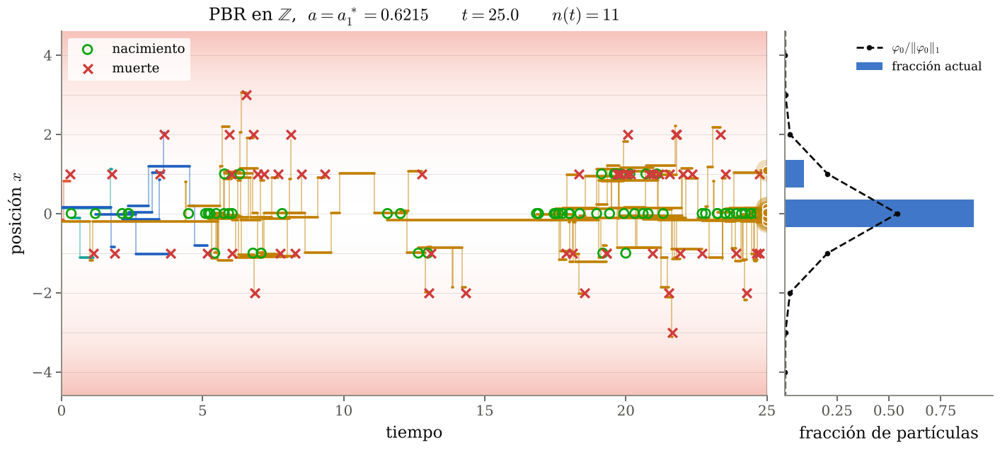

In [ ]:
# animacion 1D: arbol genealogico en el espacio-tiempo + histograma de posiciones
a1 = a_estrella_d(1)[0]
sim1 = elegir_realizacion(1, a1, T=25.0, familias=4, por_familia=1, dt_frame=0.125, nmin_final=4, nmax=18)
print("semilla 1D:", sim1["semilla"], " partículas finales:", len(sim1["fotos"][-1][1]))
# perfil de equilibrio esperado, para comparar con el histograma
_, phi1, x1 = autopar_principal(p_cuadrado, L=12.0)
perfil1 = phi1 / phi1.sum()                                          # forma de equilibrio ν = φ0/||φ0||_1

# tramos horizontales (una particula quieta), saltos (tramos verticales) y eventos, pasados a arreglos
seg = np.array([(s[0], s[1], s[2], s[3], s[4]) for s in sim1["segmentos"]])
jit_seg = np.array([jitter(q, 1, 0.22)[0, 0] for q in seg[:, 4]])
sal = np.array([(s[0], s[1], s[4], s[2], s[3]) for s in sim1["saltos"]])   # t, x0, x1, fam, pid
jit_sal = np.array([jitter(q, 1, 0.22)[0, 0] for q in sal[:, 4]]) if len(sal) else np.zeros(0)
ev = sim1["eventos"]
ev_t = np.array([e[0] for e in ev]); ev_x = np.array([e[2][0] for e in ev]); ev_k = np.array([e[1] for e in ev])
tt1 = np.array([f[0] for f in sim1["fotos"]]); nn1 = np.array([len(f[1]) for f in sim1["fotos"]])

with plt.rc_context(CLARO):
    fig = plt.figure(figsize=(13, 6))
    gs = fig.add_gridspec(1, 2, width_ratios=[3.4, 1], wspace=0.04, left=0.06, right=0.98, top=0.9, bottom=0.12)
    ax = fig.add_subplot(gs[0]); axh = fig.add_subplot(gs[1], sharey=ax)
    ax.grid(False); axh.grid(False)
    # fondo: mas rojo donde la tasa de muerte x² es mayor
    yy = np.linspace(-4.6, 4.6, 200)                                 # fondo: tasa de muerte x²
    ax.imshow(np.tile((yy**2)[:, None], (1, 2)), extent=(0, sim1["T"], -4.6, 4.6), origin="lower", aspect="auto",
              cmap=ZONA, vmin=0, vmax=22, zorder=0)
    for y in range(-4, 5):
        ax.axhline(y, color=GRIS, lw=0.5, alpha=0.30, zorder=1)
    ax.set(xlim=(0, sim1["T"]), ylim=(-4.6, 4.6), xlabel="tiempo", ylabel="posición $x$")
    lc_h = LineCollection([], linewidths=2.4, capstyle="round", zorder=3)
    lc_v = LineCollection([], linewidths=1.1, alpha=0.5, zorder=2)
    ax.add_collection(lc_h); ax.add_collection(lc_v)
    sc_n = ax.scatter([], [], s=70, marker="o", facecolors="none", edgecolors=NACE, linewidths=1.8, zorder=4, label="nacimiento")
    sc_m = ax.scatter([], [], s=70, marker="x", color=MUERE, linewidths=2.2, zorder=4, label="muerte")
    halo = ax.scatter([], [], s=420, linewidths=0, zorder=5)
    cab = ax.scatter([], [], s=62, edgecolors="white", linewidths=1.0, zorder=6)
    cursor = ax.axvline(0, color=TINTA2, lw=1.0, alpha=0.6, zorder=2)
    ax.legend(loc="upper left", fontsize=12, frameon=True, facecolor="white", edgecolor="none", framealpha=0.85)
    titulo = ax.set_title("", fontsize=16)
    axh.plot(perfil1, x1, color=TINTA, lw=1.8, ls="--", marker="o", ms=4, label=r"$\varphi_0/\|\varphi_0\|_1$")
    barras = axh.barh(np.arange(-6, 7), np.zeros(13), height=0.7, color=FAM[0], alpha=0.85, label="fracción actual")
    axh.set(xlim=(0, 1), xlabel="fracción de partículas", xticks=[0.25, 0.5, 0.75]); axh.tick_params(labelleft=False)
    axh.legend(loc="upper right", fontsize=11, frameon=False)

    # dibuja el cuadro k: todo lo ocurrido hasta el tiempo tf
    def cuadro1(k):
        tf, P, F, I = sim1["fotos"][k]
        m = seg[:, 0] <= tf
        s = seg[m]
        xs = s[:, 2] + jit_seg[m]
        lc_h.set_segments([[(a_, y), (min(b_, tf), y)] for a_, b_, y in zip(s[:, 0], s[:, 1], xs)])
        lc_h.set_color([FAM[int(f)] for f in s[:, 3]])
        if len(sal):
            mv = sal[:, 0] <= tf
            lc_v.set_segments([[(t_, x0_ + j_), (t_, x1_ + j_)] for t_, x0_, x1_, j_ in zip(sal[mv, 0], sal[mv, 1], sal[mv, 2], jit_sal[mv])])
            lc_v.set_color([FAM[int(f)] for f in sal[mv, 3]])
        mn = (ev_t <= tf) & (ev_k == "nac"); mm = (ev_t <= tf) & (ev_k == "muerte")
        sc_n.set_offsets(np.c_[ev_t[mn], ev_x[mn]] if mn.any() else np.empty((0, 2)))
        sc_m.set_offsets(np.c_[ev_t[mm], ev_x[mm]] if mm.any() else np.empty((0, 2)))
        if len(P):
            pts = np.c_[np.full(len(P), tf), P[:, 0] + jitter(I, 1, 0.22)[:, 0]]
            cab.set_offsets(pts); cab.set_facecolor([FAM[int(f)] for f in F])
            halo.set_offsets(pts); halo.set_facecolor([rgba(FAM[int(f)], 0.25) for f in F])
        cursor.set_xdata([tf, tf])
        # histograma de posiciones actuales
        cuenta = np.array([(P[:, 0] == y).sum() for y in range(-6, 7)]) / max(len(P), 1)
        for b, c in zip(barras, cuenta): b.set_width(c)
        titulo.set_text(rf"PBR en $\mathbb{{Z}}$,  $a=a^*_1={a1:.4f}$      $t={tf:5.1f}$      $n(t)={len(P)}$")
        return lc_h, lc_v, sc_n, sc_m, cab, halo, cursor, titulo

    guardar_animacion(fig, cuadro1, len(sim1["fotos"]), "pbr_1d")
    cuadro1(len(sim1["fotos"]) - 1); guardar(fig, "fig15_anim1d_final"); plt.show()

semilla 2D: 0  partículas finales: 47


guardado: animaciones_v2/pbr_2d.mp4, animaciones_v2/pbr_2d.gif


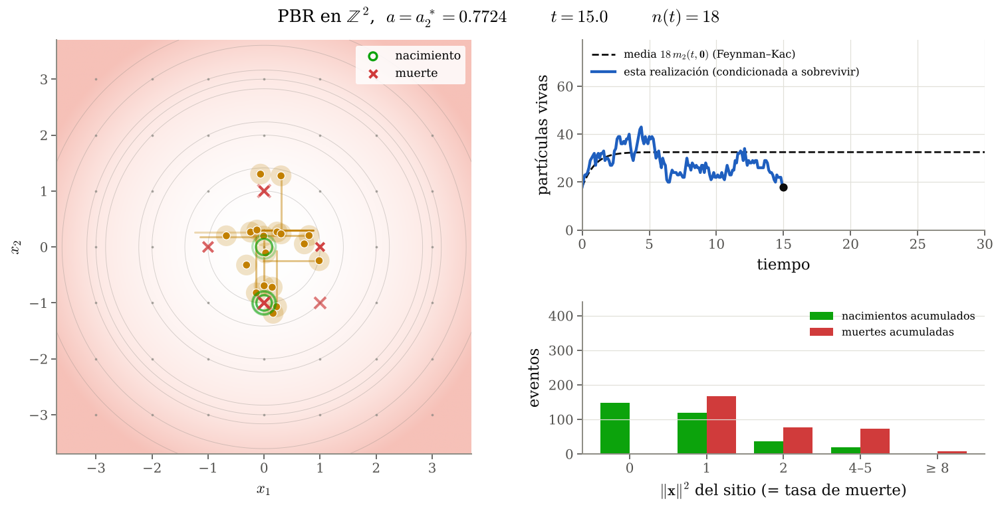

In [ ]:
# animacion 2D: plano con estelas, nacimientos y muertes
a2 = a_estrella_d(2)[0]
sim2 = elegir_realizacion(2, a2, T=30.0, familias=6, por_familia=3, dt_frame=0.1, nmin_final=8)
print("semilla 2D:", sim2["semilla"], " partículas finales:", len(sim2["fotos"][-1][1]))
# historia de cada particula (para las estelas) y eventos pasados a arreglos
H2h = historias(sim2)
ev2 = sim2["eventos"]
ev2_t = np.array([e[0] for e in ev2]); ev2_p = np.array([e[2] for e in ev2]); ev2_k = np.array([e[1] for e in ev2])
ev2_r2 = (ev2_p**2).sum(axis=1)
tt2 = np.array([f[0] for f in sim2["fotos"]]); nn2 = np.array([len(f[1]) for f in sim2["fotos"]])
# media teorica: 18 particulas iniciales por m_2(t, 0)
m_esp2 = 18 * m_FK_d(tt2, a2, 2)
R2 = 3.7; VENTANA = 0.7                                      # VENTANA: duracion visual de los eventos
clases = [(0, 0, "0"), (1, 1, "1"), (2, 2, "2"), (4, 5, "4–5"), (8, 1e9, "≥ 8")]      # clases de ||x||²

with plt.rc_context(CLARO):
    fig = plt.figure(figsize=(14, 7))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 1], height_ratios=[1.25, 1], wspace=0.2, hspace=0.42,
                          left=0.045, right=0.975, top=0.91, bottom=0.1)
    ax = fig.add_subplot(gs[:, 0]); axn = fig.add_subplot(gs[0, 1]); axb = fig.add_subplot(gs[1, 1])
    # fondo: mas rojo donde la tasa de muerte ||x||² es mayor, con sus curvas de nivel
    g = np.linspace(-R2, R2, 400); GX, GY = np.meshgrid(g, g)
    ax.imshow(GX**2 + GY**2, extent=(-R2, R2, -R2, R2), origin="lower", cmap=ZONA, vmin=0, vmax=18, zorder=0)
    ax.contour(GX, GY, GX**2 + GY**2, levels=[1, 2, 4, 5, 8, 9, 10, 13, 16], colors=GRIS, linewidths=0.6, alpha=0.35)
    kk = np.arange(-3, 4); KX, KY = np.meshgrid(kk, kk)
    ax.plot(KX.ravel(), KY.ravel(), ".", color=GRIS, ms=3, alpha=0.6, zorder=1)
    ax.set(xlim=(-R2, R2), ylim=(-R2, R2), aspect="equal", xlabel="$x_1$", ylabel="$x_2$"); ax.grid(False)
    lc = LineCollection([], linewidths=2.0, capstyle="round", zorder=2); ax.add_collection(lc)
    halo = ax.scatter([], [], s=420, linewidths=0, zorder=3)
    sc = ax.scatter([], [], s=60, edgecolors="white", linewidths=0.8, zorder=4)
    sc_n = ax.scatter([], [], s=[], facecolors="none", edgecolors=NACE, linewidths=2.2, zorder=5)
    sc_m = ax.scatter([], [], s=[], marker="x", color=MUERE, linewidths=2.6, zorder=5)
    ax.scatter([], [], s=60, facecolors="none", edgecolors=NACE, linewidths=2.2, label="nacimiento")
    ax.scatter([], [], s=60, marker="x", color=MUERE, linewidths=2.6, label="muerte")
    ax.legend(loc="upper right", fontsize=11.5, frameon=True, facecolor="white", edgecolor="none", framealpha=0.85)
    titulo = fig.suptitle("", fontsize=17, y=0.975)
    axn.plot(tt2, m_esp2, color=TINTA, lw=1.8, ls="--", label=r"media $18\,m_2(t,\mathbf{0})$ (Feynman–Kac)")
    linea_n, = axn.plot([], [], color=FAM[0], lw=2.8, label="esta realización (condicionada a sobrevivir)")
    punto_n, = axn.plot([], [], "o", color=TINTA, ms=7)
    axn.set(xlim=(0, sim2["T"]), ylim=(0, max(nn2.max(), m_esp2.max()) * 1.3), xlabel="tiempo", ylabel="partículas vivas")
    axn.legend(fontsize=10.5, loc="upper left", frameon=False)
    xb = np.arange(len(clases)); anch = 0.38
    bn = axb.bar(xb - anch / 2, np.zeros(len(clases)), anch, color=NACE, label="nacimientos acumulados")
    bm = axb.bar(xb + anch / 2, np.zeros(len(clases)), anch, color=MUERE, label="muertes acumuladas")
    # totales finales por clase de ||x||², solo para fijar la escala del grafico de barras
    tot_n = [((ev2_k == "nac") & (ev2_r2 >= lo) & (ev2_r2 <= hi)).sum() for lo, hi, _ in clases]
    tot_m = [((ev2_k == "muerte") & (ev2_r2 >= lo) & (ev2_r2 <= hi)).sum() for lo, hi, _ in clases]
    axb.set(xticks=xb, xticklabels=[c[2] for c in clases], ylim=(0, 1.25 * max(max(tot_n), max(tot_m), 1)),
            xlabel=r"$\|\mathbf{x}\|^2$ del sitio (= tasa de muerte)", ylabel="eventos")
    axb.legend(fontsize=10.5, loc="upper right", frameon=False); axb.grid(axis="x", visible=False)

    # dibuja el cuadro k
    def cuadro2(k):
        tf, P, F, I = sim2["fotos"][k]
        if len(P):
            Q = P + jitter(I, 2, 0.34)
            sc.set_offsets(Q); sc.set_facecolor([FAM[int(f)] for f in F])
            halo.set_offsets(Q); halo.set_facecolor([rgba(FAM[int(f)], 0.22) for f in F])
        else:
            sc.set_offsets(np.empty((0, 2))); halo.set_offsets(np.empty((0, 2)))
        segs, cols = estelas(sim2, H2h, k, 2, amp=0.34)
        lc.set_segments(segs); lc.set_color(cols if cols else "none")
        # eventos recientes: el anillo o la cruz crece y se desvanece con la edad del evento
        rec = (ev2_t <= tf) & (ev2_t > tf - VENTANA)
        mn = rec & (ev2_k == "nac"); mm = rec & (ev2_k == "muerte")
        edad_n = (tf - ev2_t[mn]) / VENTANA; edad_m = (tf - ev2_t[mm]) / VENTANA
        sc_n.set_offsets(ev2_p[mn] if mn.any() else np.empty((0, 2))); sc_n.set_sizes(40 + 620 * edad_n)
        sc_n.set_edgecolors([rgba(NACE, 1 - 0.9 * e) for e in edad_n])
        sc_m.set_offsets(ev2_p[mm] if mm.any() else np.empty((0, 2))); sc_m.set_sizes(60 + 160 * edad_m)
        sc_m.set_color([rgba(MUERE, 1 - 0.85 * e) for e in edad_m])
        linea_n.set_data(tt2[:k + 1], nn2[:k + 1]); punto_n.set_data([tf], [len(P)])
        # barras: nacimientos y muertes acumulados hasta ahora, segun la distancia al origen
        pas = ev2_t <= tf
        for j, (lo, hi, _) in enumerate(clases):
            en = pas & (ev2_r2 >= lo) & (ev2_r2 <= hi)
            bn[j].set_height((en & (ev2_k == "nac")).sum()); bm[j].set_height((en & (ev2_k == "muerte")).sum())
        titulo.set_text(rf"PBR en $\mathbb{{Z}}^2$,  $a=a^*_2={a2:.4f}$        $t={tf:5.1f}$        $n(t)={len(P)}$")
        return sc, halo, lc, sc_n, sc_m, linea_n, titulo

    guardar_animacion(fig, cuadro2, len(sim2["fotos"]), "pbr_2d")
    cuadro2(len(sim2["fotos"]) // 2); guardar(fig, "fig16_anim2d_cuadro"); plt.show()

semilla 3D: 0  partículas finales: 25


guardado: animaciones_v2/pbr_3d.mp4, animaciones_v2/pbr_3d.gif


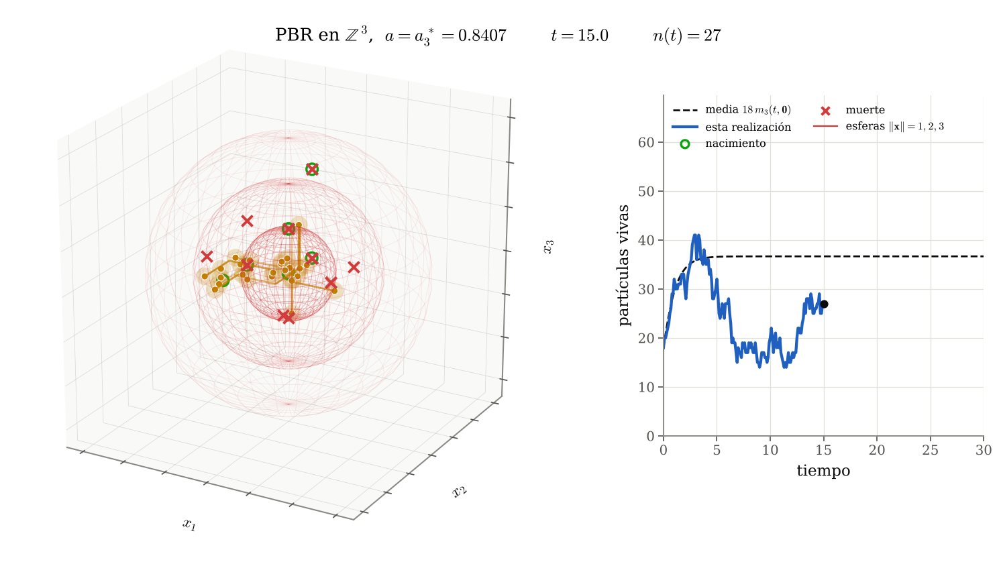

In [ ]:
# animacion 3D: espacio con camara giratoria y estelas
a3 = a_estrella_d(3)[0]
sim3 = elegir_realizacion(3, a3, T=30.0, familias=6, por_familia=3, dt_frame=0.1, nmin_final=8)
print("semilla 3D:", sim3["semilla"], " partículas finales:", len(sim3["fotos"][-1][1]))
H3h = historias(sim3)
ev3 = sim3["eventos"]
ev3_t = np.array([e[0] for e in ev3]); ev3_p = np.array([e[2] for e in ev3]); ev3_k = np.array([e[1] for e in ev3])
tt3 = np.array([f[0] for f in sim3["fotos"]]); nn3 = np.array([len(f[1]) for f in sim3["fotos"]])
m_esp3 = 18 * m_FK_d(tt3, a3, 3)
R3 = 3.4

with plt.rc_context(CLARO):
    fig = plt.figure(figsize=(14, 7))
    ax = fig.add_axes([-0.04, -0.06, 0.66, 1.06], projection="3d")
    axn = fig.add_axes([0.66, 0.17, 0.31, 0.66])
    ax.set_facecolor("white")
    u_, v_ = np.mgrid[0:2 * np.pi:36j, 0:np.pi:18j]
    for rad, al in [(1.0, 0.38), (2.0, 0.2), (3.0, 0.1)]:        # esferas ||x|| = 1, 2, 3 (tasa de muerte 1, 4, 9)
        ax.plot_wireframe(rad * np.cos(u_) * np.sin(v_), rad * np.sin(u_) * np.sin(v_), rad * np.cos(v_),
                          color=ROJO_CRIT, alpha=al, linewidth=0.5)
    ax.set(xlim=(-R3, R3), ylim=(-R3, R3), zlim=(-R3, R3), xlabel="$x_1$", ylabel="$x_2$", zlabel="$x_3$")
    ax.set_box_aspect((1, 1, 1))
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    # paneles y grilla claros
    for eje in (ax.xaxis, ax.yaxis, ax.zaxis):
        eje.set_pane_color((0.975, 0.975, 0.97, 1.0)); eje.line.set_color(GRIS)
        eje._axinfo["grid"]["color"] = (0.80, 0.80, 0.78, 0.7); eje._axinfo["grid"]["linewidth"] = 0.5
    lc3 = Line3DCollection([[(0, 0, 0), (0, 0, 0)]], linewidths=1.8); ax.add_collection3d(lc3)
    halo = ax.scatter([], [], [], s=300, linewidths=0, depthshade=False)
    sc = ax.scatter([], [], [], s=44, edgecolors="white", linewidths=0.7, depthshade=False)
    sc_n = ax.scatter([], [], [], s=120, facecolors="none", edgecolors=NACE, linewidths=2.2, depthshade=False)
    sc_m = ax.scatter([], [], [], s=110, marker="x", color=MUERE, linewidths=2.6, depthshade=False)
    titulo = fig.suptitle("", y=0.965, fontsize=17)
    axn.plot(tt3, m_esp3, color=TINTA, lw=1.8, ls="--", label=r"media $18\,m_3(t,\mathbf{0})$")
    linea_n, = axn.plot([], [], color=FAM[0], lw=2.8, label="esta realización")
    punto_n, = axn.plot([], [], "o", color=TINTA, ms=7)
    axn.scatter([], [], s=60, facecolors="none", edgecolors=NACE, linewidths=2.2, label="nacimiento")
    axn.scatter([], [], s=60, marker="x", color=MUERE, linewidths=2.6, label="muerte")
    axn.plot([], [], color=ROJO_CRIT, lw=1.5, label=r"esferas $\|\mathbf{x}\|=1,2,3$")
    axn.set(xlim=(0, sim3["T"]), ylim=(0, max(nn3.max(), m_esp3.max()) * 1.45), xlabel="tiempo", ylabel="partículas vivas")
    axn.legend(fontsize=10.5, loc="upper left", frameon=False, ncol=2)

    # dibuja el cuadro k
    def cuadro3(k):
        tf, P, F, I = sim3["fotos"][k]
        Q = P + jitter(I, 3, 0.3) if len(P) else np.zeros((0, 3))
        cols = [FAM[int(f)] for f in F]
        sc._offsets3d = (Q[:, 0], Q[:, 1], Q[:, 2]); sc.set_facecolor(cols); sc.set_edgecolor("white")
        halo._offsets3d = (Q[:, 0], Q[:, 1], Q[:, 2]); halo.set_facecolor([rgba(c, 0.22) for c in cols])
        segs, scol = estelas(sim3, H3h, k, 3, amp=0.3)
        lc3.set_segments(segs); lc3.set_color(scol if scol else "none")
        rec = (ev3_t <= tf) & (ev3_t > tf - VENTANA)
        mn = rec & (ev3_k == "nac"); mm = rec & (ev3_k == "muerte")
        En = ev3_p[mn] if mn.any() else np.zeros((0, 3)); Em = ev3_p[mm] if mm.any() else np.zeros((0, 3))
        sc_n._offsets3d = (En[:, 0], En[:, 1], En[:, 2]); sc_m._offsets3d = (Em[:, 0], Em[:, 1], Em[:, 2])
        # la camara da una vuelta completa durante la animacion
        ax.view_init(elev=22 + 8 * np.sin(2 * np.pi * k / len(sim3["fotos"])), azim=-60 + 360 * k / len(sim3["fotos"]))
        linea_n.set_data(tt3[:k + 1], nn3[:k + 1]); punto_n.set_data([tf], [len(P)])
        titulo.set_text(rf"PBR en $\mathbb{{Z}}^3$,  $a=a^*_3={a3:.4f}$        $t={tf:5.1f}$        $n(t)={len(P)}$")
        return sc, halo, lc3, sc_n, sc_m, linea_n, titulo

    guardar_animacion(fig, cuadro3, len(sim3["fotos"]), "pbr_3d")
    cuadro3(len(sim3["fotos"]) // 2); guardar(fig, "fig17_anim3d_cuadro"); plt.show()

In [ ]:
# muestra las animaciones dentro del notebook (el MP4 si existe; si no hay ffmpeg, el GIF)
from IPython.display import Video, Image, display
for nombre in ["pbr_1d", "pbr_2d", "pbr_3d"]:
    mp4 = os.path.join(ANIMDIR, nombre + ".mp4")
    if os.path.exists(mp4):
        display(Video(mp4, embed=True, width=720))
    else:
        display(Image(os.path.join(ANIMDIR, nombre + ".gif")))

Lo que se ve:

- Los nacimientos ocurren cerca del origen y las muertes en la periferia: el paseo lleva partículas del centro hacia afuera.
- Aunque se parte con varias familias, al rato sobreviven una o dos.
- La media es estable, pero cada realización fluctúa mucho.

### 4.5 Respuesta a la Pregunta 3

$a^*_d=d\,a^*_1(\lambda/d)$: $0.6215$, $0.7724$, $0.8407$, $0.8782,\ldots$ El crítico crece con la dimensión y se satura en $\lambda$. Monte Carlo, Many-to-one y Feynman–Kac siguen dando lo mismo en $d=2$ y $d=3$.

---
## 5. Pregunta 4: el segundo momento

Volvemos al modelo original en $\mathbb Z$ con $p(x)=x^2$. Para una función test $\varphi$ acotada,

$$u(t,x)=\mathbb E_{\delta_x}\big[\langle X_t,\varphi\rangle\big],\qquad w(t,x)=\mathbb E_{\delta_x}\big[\langle X_t,\varphi\rangle^2\big].$$

$u$ resuelve Feynman–Kac. La ecuación de $w$ es

$$\boxed{\ \partial_tw=Lw+(a-x^2)\,w+2a\,u^2,\qquad w(0,x)=\varphi(x)^2\ }$$

y con $\varphi\equiv1$: $\partial_tw=Lw+(a-x^2)\,w+2a\,m(t,x)^2$, $w(0,x)=1$.

### 5.1 De dónde sale

Es el mismo argumento del primer evento que da Feynman–Kac. La partícula inicial:

- salta a $x\pm h$ (tasa $\lambda/2$ cada uno): queda $w(\cdot,x\pm h)$;
- muere (tasa $x^2$): queda $0$;
- se ramifica (tasa $a$): quedan dos copias independientes $S_1$, $S_2$, y $\mathbb E[(S_1+S_2)^2]=2w+2u^2$.

Lo único nuevo es el término cruzado $2\,\mathbb E S_1\,\mathbb E S_2=2u^2$, que por independencia trae el cuadrado del primer momento.

Los términos:

- $Lw$ y $(a-x^2)w$ son los mismos de Feynman–Kac;
- $2a\,u^2$ es la tasa a la que se crean pares de partículas ($2a$) por el primer momento al cuadrado.

O sea es Feynman–Kac con una fuente: primero se resuelve $u$ y después $w$. El análogo de Many-to-one es

$$w(t,x)=\mathbb E_x\Big[e^{\int_0^tV(Z_r)dr}\,\varphi(Z_t)^2\Big]+2a\int_0^t\mathbb E_x\Big[e^{\int_0^sV(Z_r)dr}\;u(t-s,Z_s)^2\Big]ds,$$

donde el primer término cuenta los pares de una partícula consigo misma y el segundo los pares de partículas distintas, cuyos linajes se separaron en el tiempo $s$.

Para la varianza $v=w-u^2$ queda la misma ecuación con otra fuente:

$$\partial_tv=Lv+(a-x^2)\,v+(a+x^2)\,u^2+\frac\lambda2\sum_\pm\big(u(x\pm h)-u(x)\big)^2,\qquad v(0)=0 .$$

### 5.2 Comparación con Monte Carlo

Resolvemos el sistema $(u,w)$ con `solve_ivp` y lo comparamos con el sistema de partículas para $\varphi\equiv1$, para $\varphi=\mathbf 1_{\{0\}}$ (partículas en el origen) y para varios puntos de partida.

φ=1, a=0.5000:  E|X_T|² a T=20:  PBR = 1.212 ± 0.082,  ecuación = 1.269  (z = -1.40);   media: PBR = 0.124, FK = 0.126


φ=1, a=0.6215:  E|X_T|² a T=20:  PBR = 45.441 ± 1.595,  ecuación = 45.136  (z = +0.38);   media: PBR = 1.446, FK = 1.433


φ=1, a=0.7000:  E|X_T|² a T=20:  PBR = 598.216 ± 16.688,  ecuación = 585.527  (z = +1.52);   media: PBR = 6.918, FK = 6.885


φ=1_0, a=a* (N=1000000):  PBR = 14.169 ± 0.236,  ecuación = 13.826  (z = +2.90)


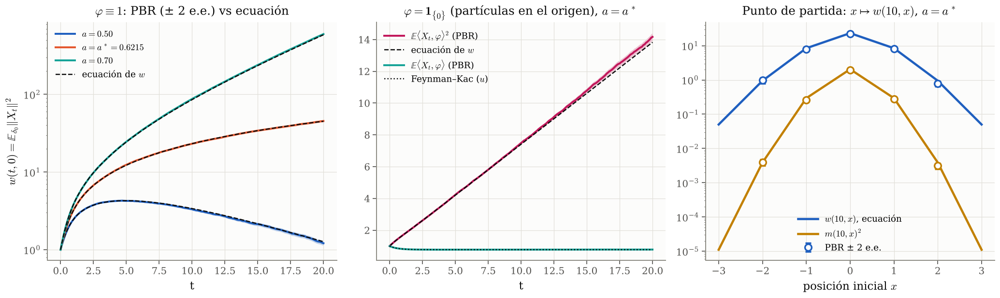

z = (PBR - ecuación)/e.e. del segundo momento en 10 corridas independientes de N=500000:


  φ = 1      t=10: media -0.09, desv. 0.82   |   t=20: media -0.41, desv. 0.91,  valores: -0.1 +0.7 -2.6 +0.5 -0.3 +0.1 -0.4 -0.7 -0.4 -0.9


  φ = 1_{0}  t=10: media -0.32, desv. 0.75   |   t=20: media -0.21, desv. 0.86,  valores: -0.8 +1.3 +0.0 -0.5 +0.3 -0.2 -0.6 -0.5 -1.8 +0.6
tiempo: 42.1 s


In [ ]:
# ecuaciones del primer y segundo momento en la caja |x| <= ell (Dirichlet):
# ∂t u = L u + (a - p) u,              u(0) = φ
# ∂t w = L w + (a - p) w + 2a u²,      w(0) = φ²
# el sistema es triangular: u no depende de w, y w lleva como fuente 2a u²
# devuelve (x, U, W) con U[:, k] = u(ts[k], ·) y W[:, k] = w(ts[k], ·)
def segundo_momento(ts, a, phi=None, p=p_cuadrado, lam=1.0, ell=15.0, h=1.0, rtol=1e-10, atol=1e-12):
    x, L1, P = matrices_caja(ell, p, h); n = len(x)
    A = (lam * L1 + sp.diags(a - P)).tocsr(); Ad = A.toarray()
    # funcion test φ evaluada en la red (por defecto φ = 1, o sea el numero de particulas)
    f0 = np.ones(n) if phi is None else np.array([phi(float(v)) for v in x])
    def rhs(t, y):
        u, w = y[:n], y[n:]
        # se resuelven juntas: y = (u, w)
        return np.concatenate([A @ u, A @ w + 2 * a * u * u])
    def jac(t, y):
        J = np.zeros((2 * n, 2 * n))
        J[:n, :n] = Ad; J[n:, n:] = Ad; J[n:, :n] = np.diag(4 * a * y[:n])
        return J
    ts = np.asarray(ts, float)
    sol = solve_ivp(rhs, (0.0, ts[-1]), np.concatenate([f0, f0**2]), method="LSODA", jac=jac, t_eval=ts, rtol=rtol, atol=atol)
    return x, sol.y[:n], sol.y[n:]

# funciones test: φ = 1 (cuenta todas las particulas) y φ = 1_{0} (cuenta las que estan en el origen)
@njit
def phi_uno(x): return 1.0
@njit
def phi_origen(x): return 1.0 if x == 0.0 else 0.0

_KERNELS_M2 = {}
# simulacion del PBR 1D (la misma de la seccion 1) que en cada tiempo de la grilla acumula
# S = <X_t, φ>, S², S⁴ (para el error estandar de S²) y si quedan particulas vivas
def kernels_momentos(pfun, phifun):
    if (pfun, phifun) in _KERNELS_M2:
        return _KERNELS_M2[(pfun, phifun)]

    @njit
    def una(T, a, lam, h, mu0, ts, out):
        n0 = mu0.shape[0]; cap = max(512, 4 * n0)
        pos = np.empty(cap); w = np.empty(cap)
        n = n0; tasa_p = 0.0
        for j in range(n0):
            pos[j] = mu0[j]; w[j] = pfun(mu0[j]); tasa_p += w[j]
        t = 0.0; k = 0; nts = ts.shape[0]
        while n > 0 and t <= T:
            tasa_alpha = a * n + tasa_p
            rate = tasa_alpha + lam * n
            t += np.random.exponential() / rate
            while k < nts and t >= ts[k]:
                # S = suma de φ sobre las particulas vivas
                S = 0.0
                for j in range(n):
                    S += phifun(pos[j])
                out[0, k] += S; out[1, k] += S * S; out[2, k] += S**4; out[3, k] += 1.0
                k += 1
            if np.random.random() < lam * n / rate:
                i = np.random.randint(n)
                y = pos[i] + (h if np.random.random() < 0.5 else -h)
                py = pfun(y); tasa_p += py - w[i]; pos[i] = y; w[i] = py
            else:
                u = np.random.random() * tasa_alpha; acc = 0.0; i = n - 1
                for j in range(n):
                    acc += w[j] + a
                    if acc >= u:
                        i = j; break
                px = w[i]
                if np.random.random() < px / (a + px):
                    pos[i] = pos[n - 1]; w[i] = w[n - 1]; n -= 1; tasa_p -= px
                else:
                    if n == cap:
                        cap *= 2
                        pos2 = np.empty(cap); w2 = np.empty(cap)
                        pos2[:n] = pos[:n]; w2[:n] = w[:n]; pos = pos2; w = w2
                    pos[n] = pos[i]; w[n] = px; n += 1; tasa_p += px

    # promedio de N realizaciones en bloques paralelos
    @njit(parallel=True)
    def lote(N, T, a, lam, h, mu0, ts, nchunks, seed):
        acc = np.zeros((nchunks, 4, ts.shape[0]))
        per = N // nchunks
        for c in prange(nchunks):
            np.random.seed(seed + c)
            m = per + (1 if c < N - per * nchunks else 0)
            for r in range(m):
                una(T, a, lam, h, mu0, ts, acc[c])
        return acc.sum(axis=0) / N

    _KERNELS_M2[(pfun, phifun)] = lote
    return lote

# Monte Carlo de los dos primeros momentos de <X_t, φ> partiendo de δ_x0
# devuelve un dict con m1, se1, m2, se2 (medias y errores estandar) y surv = P(|X_t| > 0)
def momentos_mc(N, T, a, x0, ts, phi=phi_uno, p=p_cuadrado, lam=1.0, h=1.0, seed=0):
    ts = np.asarray(ts, float)
    M = kernels_momentos(p, phi)(int(N), float(T), float(a), float(lam), float(h), np.array([float(x0)]), ts, NCHUNKS, seed)
    m1, m2, m4, sv = M
    return dict(m1=m1, se1=np.sqrt(np.maximum(m2 - m1**2, 0) / N), m2=m2, se2=np.sqrt(np.maximum(m4 - m2**2, 0) / N), surv=sv)

# comparacion de la ecuacion del segundo momento con el sistema de particulas
a_cr = -Lam_p                                  # a* = 0.62151...
T = 20.0; ts = np.linspace(0, T, 201); N = NN(200_000)
fig, axs = plt.subplots(1, 3, figsize=(19, 5.8))
t0 = time.time()

# (A) φ = 1: segundo momento del numero de particulas, tres valores de a
ax = axs[0]
for j, a_ in enumerate([0.50, a_cr, 0.70]):
    x, U, W = segundo_momento(ts, a_)
    i0 = int(np.argmin(np.abs(x)))
    mc = momentos_mc(N, T, a_, 0.0, ts, seed=2_000_000 + 10_000 * j)
    ax.fill_between(ts, mc["m2"] - 2 * mc["se2"], mc["m2"] + 2 * mc["se2"], color=C[j], alpha=0.25, lw=0)
    ax.plot(ts, mc["m2"], color=C[j], lw=2.6, label=(rf"$a={a_:.2f}$" if j != 1 else rf"$a=a^*={a_:.4f}$"))
    ax.plot(ts, W[i0], color=TINTA, lw=1.6, ls="--")
    # z = diferencia PBR - ecuacion en unidades de error estandar
    z = (mc["m2"][-1] - W[i0, -1]) / mc["se2"][-1]
    print(f"φ=1, a={a_:.4f}:  E|X_T|² a T={T:.0f}:  PBR = {mc['m2'][-1]:.3f} ± {2*mc['se2'][-1]:.3f},  ecuación = {W[i0,-1]:.3f}  (z = {z:+.2f});"
          f"   media: PBR = {mc['m1'][-1]:.3f}, FK = {U[i0,-1]:.3f}")
ax.plot([], [], color=TINTA, lw=1.6, ls="--", label=r"ecuación de $w$")
ax.set(yscale="log", xlabel="t", ylabel=r"$w(t,0)=\mathbb{E}_{\delta_0}\|X_t\|^2$", title=r"$\varphi\equiv1$: PBR (± 2 e.e.) vs ecuación")
ax.legend(loc="upper left", fontsize=12)

# (B) φ = 1_{0}: numero de particulas en el origen, a = a*
ax = axs[1]
x, U, W = segundo_momento(ts, a_cr, phi=phi_origen)
Nb = NN(1_000_000)                      # S² tiene cola pesada: mas muestras para este panel
mc = momentos_mc(Nb, T, a_cr, 0.0, ts, phi=phi_origen, seed=2_100_000)
ax.fill_between(ts, mc["m2"] - 2 * mc["se2"], mc["m2"] + 2 * mc["se2"], color=C[4], alpha=0.25, lw=0)
ax.plot(ts, mc["m2"], color=C[4], lw=2.6, label=r"$\mathbb{E}\langle X_t,\varphi\rangle^2$ (PBR)")
ax.plot(ts, W[i0], color=TINTA, lw=1.6, ls="--", label=r"ecuación de $w$")
ax.fill_between(ts, mc["m1"] - 2 * mc["se1"], mc["m1"] + 2 * mc["se1"], color=C[2], alpha=0.25, lw=0)
ax.plot(ts, mc["m1"], color=C[2], lw=2.6, label=r"$\mathbb{E}\langle X_t,\varphi\rangle$ (PBR)")
ax.plot(ts, U[i0], color=TINTA, lw=1.6, ls=":", label=r"Feynman–Kac ($u$)")
ax.set(xlabel="t", title=r"$\varphi=\mathbf{1}_{\{0\}}$ (partículas en el origen), $a=a^*$")
ax.legend(loc="upper left", fontsize=12)
print(f"φ=1_0, a=a* (N={Nb}):  PBR = {mc['m2'][-1]:.3f} ± {2*mc['se2'][-1]:.3f},  ecuación = {W[i0,-1]:.3f}  (z = {(mc['m2'][-1]-W[i0,-1])/mc['se2'][-1]:+.2f})")

# (C) dependencia en el punto de partida: x -> w(T, x), a = a*
ax = axs[2]
Tx = 10.0; tx = np.linspace(0, Tx, 11)
x, U, W = segundo_momento(tx, a_cr)
sel = np.abs(x) <= 3
ax.plot(x[sel], W[sel, -1], "-", color=C[0], lw=3, label=rf"$w({Tx:.0f},x)$, ecuación")
ax.plot(x[sel], U[sel, -1]**2, "-", color=C[3], lw=3, label=rf"$m({Tx:.0f},x)^2$")
# la ecuacion da todos los x de una vez; el Monte Carlo se corre para cinco puntos de partida
xs_mc = np.arange(-2, 3)
w_mc = np.array([momentos_mc(NN(100_000), Tx, a_cr, float(v), np.array([Tx]), seed=2_200_000 + 1000 * int(v + 2)) for v in xs_mc])
ax.errorbar(xs_mc, [r["m2"][0] for r in w_mc], yerr=[2 * r["se2"][0] for r in w_mc], fmt="o", color=C[0], ms=9, capsize=4,
            mfc="white", mew=2.2, label="PBR ± 2 e.e.")
ax.errorbar(xs_mc, [r["m1"][0]**2 for r in w_mc], yerr=[4 * r["m1"][0] * r["se1"][0] for r in w_mc], fmt="o", color=C[3], ms=9, capsize=4,
            mfc="white", mew=2.2)
ax.set(yscale="log", xlabel="posición inicial $x$", title=rf"Punto de partida: $x\mapsto w({Tx:.0f},x)$, $a=a^*$")
ax.legend(loc="lower center", fontsize=12)
fig.tight_layout()
guardar(fig, "fig18_segundo_momento_validacion"); plt.show()

# repeticion con semillas independientes: ¿las desviaciones PBR - ecuacion son ruido o sesgo?
# (S² tiene cola pesada y la curva esta muy correlacionada en el tiempo, asi que una sola corrida puede quedar a 2-3 e.e.)
Nr, R = NN(500_000), 10; t_rep = np.array([0.0, 10.0, 20.0])
print(f"z = (PBR - ecuación)/e.e. del segundo momento en {R} corridas independientes de N={Nr}:")
for nombre, phi_ in [("φ = 1    ", phi_uno), ("φ = 1_{0}", phi_origen)]:
    xr, Ur, Wr = segundo_momento(t_rep, a_cr, phi=phi_)
    zs = []
    for r in range(R):
        mr = momentos_mc(Nr, T, a_cr, 0.0, t_rep, phi=phi_, seed=3_000_000 + 100_003 * r + (0 if phi_ is phi_uno else 50_000))
        zs.append((mr["m2"][1:] - Wr[i0, 1:]) / mr["se2"][1:])
    zs = np.array(zs)
    print(f"  {nombre}  t=10: media {zs[:, 0].mean():+.2f}, desv. {zs[:, 0].std(ddof=1):.2f}   |   "
          f"t=20: media {zs[:, 1].mean():+.2f}, desv. {zs[:, 1].std(ddof=1):.2f},  valores: " + " ".join(f"{v:+.1f}" for v in zs[:, 1]))
print(f"tiempo: {time.time()-t0:.1f} s")

El sistema de partículas coincide con la ecuación en los tres valores de $a$ y con las dos $\varphi$. La corrida del panel central termina a $2.9$ errores estándar, pero repitiendo con 10 semillas la desviación tiene media cerca de $0$ y dispersión cerca de $1$, o sea es ruido. Ya se ve lo principal: con $a=a^*$ la media está quieta y el segundo momento sigue creciendo.

### 5.3 ¿Hay un $a$ crítico para la varianza?

Con $\varphi\equiv1$, de la ecuación sale:

- $a<a^*$: $w$ decae con tasa $a-a^*$, la misma de $m$;
- $a>a^*$: $w$ crece con tasa $2(a-a^*)$;
- $a=a^*$: $w(t,x)\approx\kappa(x)\,t$, con $\kappa(x)=2a^*\|\varphi_0\|_1^2\big(\sum_y\varphi_0(y)^3\big)\varphi_0(x)$.

El umbral es el mismo $a^*$ del promedio, pero como $w\to0$ para $a<a^*$ y $w\to\infty$ para $a\ge a^*$, **ningún $a$ estabiliza el segundo momento**. En el crítico la media se queda fija y la varianza crece linealmente.

Esto calza con que la población crítica se extingue: por Cauchy–Schwarz $\mathbb P(\|X_t\|>0)\ge m^2/w\approx c/t$, así que sobrevivir es cada vez más raro, y las que sobreviven tienen del orden de $t$ partículas.

a* = 0.621511,  c(0) = 1.4328,  κ(0) = 2.1925
  a - a* = -0.03:  tasa de m = -0.0300,  tasa de w = -0.0298   (predicción: -0.0300 y -0.0300)
  a - a* = +0.00:  tasa de m = -0.0000,  tasa de w = +0.0057   (predicción: +0.0000 y +0.0000; el resto es el crecimiento lineal, ~1/t)
  a - a* = +0.03:  tasa de m = +0.0300,  tasa de w = +0.0602   (predicción: +0.0300 y +0.0600)


  pendiente de w(t,0) en a=a* (ecuación, t>30): 2.1925;  κ(0) = 2.1925;  PBR en T=60: 136.12 ± 5.99 vs 132.83


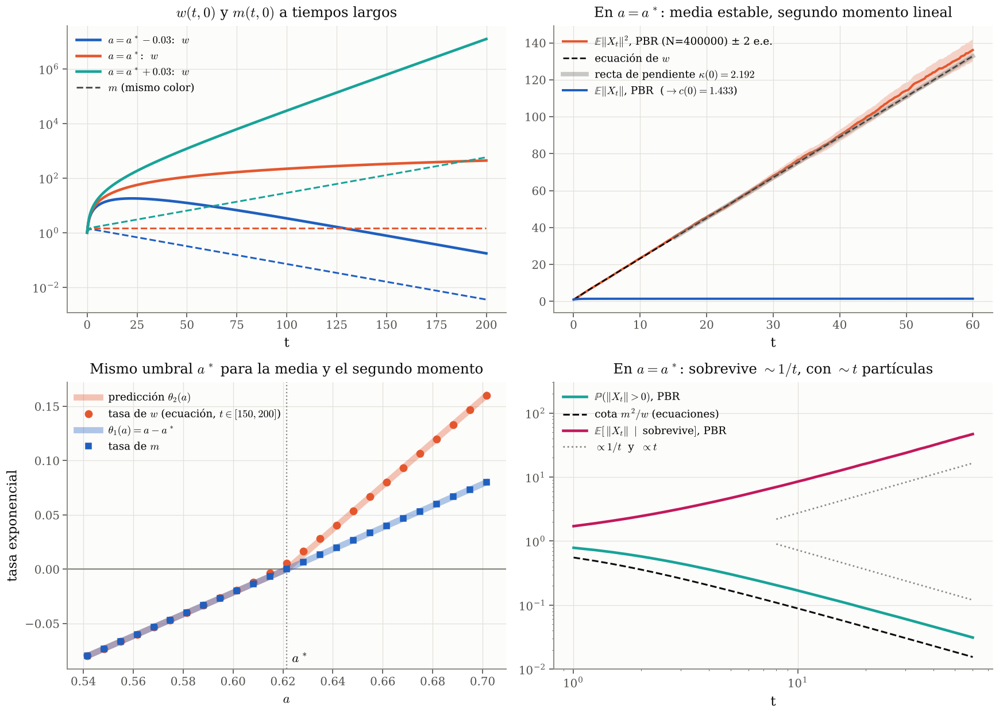

tiempo: 6.1 s


In [ ]:
# predicciones en a = a* a partir del estado fundamental φ0
_, phi0c, xc = autopar_principal(p_cuadrado, L=15.0)
i0c = int(np.argmin(np.abs(xc)))
c0 = phi0c[i0c] * phi0c.sum()                                             # limite de m(t,0) en a = a*
kappa0 = 2 * a_cr * phi0c.sum()**2 * (phi0c**3).sum() * phi0c[i0c]        # pendiente de w(t,0) en a = a*
print(f"a* = {a_cr:.6f},  c(0) = {c0:.4f},  κ(0) = {kappa0:.4f}")

fig, axs = plt.subplots(2, 2, figsize=(16, 11.5))
t0 = time.time()

# (A) tiempos largos: tres regimenes
ax = axs[0, 0]
Tl = 200.0; tl = np.linspace(0, Tl, 801); da = 0.03
for j, a_ in enumerate([a_cr - da, a_cr, a_cr + da]):
    x, U, W = segundo_momento(tl, a_)
    i0 = int(np.argmin(np.abs(x)))
    et = ["$a=a^*-0.03$", "$a=a^*$", "$a=a^*+0.03$"][j]
    ax.plot(tl, W[i0], color=C[j], lw=3, label=et + ":  $w$")
    ax.plot(tl, U[i0], color=C[j], lw=2, ls="--")
    # tasa exponencial medida entre t = 150 y t = 200
    k1, k2 = np.searchsorted(tl, 150.0), len(tl) - 1
    th2 = np.log(W[i0, k2] / W[i0, k1]) / (tl[k2] - tl[k1]); th1 = np.log(U[i0, k2] / U[i0, k1]) / (tl[k2] - tl[k1])
    print(f"  a - a* = {a_-a_cr:+.2f}:  tasa de m = {th1:+.4f},  tasa de w = {th2:+.4f}   (predicción: {a_-a_cr:+.4f} y {(a_-a_cr) * (2 if a_ > a_cr else 1):+.4f}{"; el resto es el crecimiento lineal, ~1/t" if j == 1 else ""})")
ax.plot([], [], color=TINTA2, lw=2, ls="--", label="$m$ (mismo color)")
ax.set(yscale="log", xlabel="t", title=r"$w(t,0)$ y $m(t,0)$ a tiempos largos")
ax.legend(loc="upper left", fontsize=12)

# (B) en a = a*: media plana, segundo momento lineal
ax = axs[0, 1]
Tc = 60.0; tc = np.linspace(0, Tc, 241); Nc = NN(400_000)
x, Uc, Wc = segundo_momento(tc, a_cr); i0 = int(np.argmin(np.abs(x)))
mc = momentos_mc(Nc, Tc, a_cr, 0.0, tc, seed=2_300_000)
ax.fill_between(tc, mc["m2"] - 2 * mc["se2"], mc["m2"] + 2 * mc["se2"], color=C[1], alpha=0.25, lw=0)
ax.plot(tc, mc["m2"], color=C[1], lw=2.6, label=rf"$\mathbb{{E}}\|X_t\|^2$, PBR (N={Nc}) ± 2 e.e.")
ax.plot(tc, Wc[i0], color=TINTA, lw=1.8, ls="--", label="ecuación de $w$")
# recta con la pendiente predicha κ(0), ajustada para pasar por el ultimo punto
b0 = Wc[i0, -1] - kappa0 * Tc
ax.plot(tc[tc > 15], kappa0 * tc[tc > 15] + b0, color=GRIS, lw=5, alpha=0.45, label=rf"recta de pendiente $\kappa(0)={kappa0:.3f}$")
ax.fill_between(tc, mc["m1"] - 2 * mc["se1"], mc["m1"] + 2 * mc["se1"], color=C[0], alpha=0.25, lw=0)
ax.plot(tc, mc["m1"], color=C[0], lw=2.6, label=rf"$\mathbb{{E}}\|X_t\|$, PBR  ($\to c(0)={c0:.3f}$)")
ax.set(xlabel="t", title=r"En $a=a^*$: media estable, segundo momento lineal")
ax.legend(loc="upper left", fontsize=12)
pend = np.polyfit(tc[tc > 30], Wc[i0][tc > 30], 1)[0]
print(f"  pendiente de w(t,0) en a=a* (ecuación, t>30): {pend:.4f};  κ(0) = {kappa0:.4f};  "
      f"PBR en T={Tc:.0f}: {mc['m2'][-1]:.2f} ± {2*mc['se2'][-1]:.2f} vs {Wc[i0,-1]:.2f}")

# (C) tasa exponencial del segundo momento en funcion de a: mismo umbral, con quiebre
ax = axs[1, 0]
a_grid = np.linspace(a_cr - 0.08, a_cr + 0.08, 25); T1, T2 = 150.0, 200.0
th1, th2 = [], []
# para cada a se mide la tasa exponencial de m y de w a tiempos largos
for a_ in a_grid:
    x, U, W = segundo_momento(np.array([0.0, T1, T2]), a_)
    th1.append(np.log(U[i0, 2] / U[i0, 1]) / (T2 - T1)); th2.append(np.log(W[i0, 2] / W[i0, 1]) / (T2 - T1))
ax.axhline(0, color=GRIS, lw=1.5); ax.axvline(a_cr, color=GRIS, lw=1.5, ls=":")
ax.plot(a_grid, np.where(a_grid < a_cr, a_grid - a_cr, 2 * (a_grid - a_cr)), color=C[1], lw=7, alpha=0.35, label=r"predicción $\theta_2(a)$")
ax.plot(a_grid, th2, "o", color=C[1], ms=8, label=r"tasa de $w$ (ecuación, $t\in[150,200]$)")
ax.plot(a_grid, a_grid - a_cr, color=C[0], lw=7, alpha=0.35, label=r"$\theta_1(a)=a-a^*$")
ax.plot(a_grid, th1, "s", color=C[0], ms=7, label=r"tasa de $m$")
ax.annotate(r"$a^*$", (a_cr, ax.get_ylim()[0]), xytext=(6, 8), textcoords="offset points", fontsize=15)
ax.set(xlabel="$a$", ylabel="tasa exponencial", title="Mismo umbral $a^*$ para la media y el segundo momento")
ax.legend(loc="upper left", fontsize=12)

# (D) supervivencia en a = a*: ~1/t
ax = axs[1, 1]
sel = tc >= 1.0
# probabilidad de seguir vivo, su cota inferior m²/w (Cauchy-Schwarz) y el tamaño medio de las que sobreviven
ax.plot(tc[sel], mc["surv"][sel], color=C[2], lw=3, label=r"$\mathbb{P}(\|X_t\|>0)$, PBR")
ax.plot(tc[sel], Uc[i0][sel]**2 / Wc[i0][sel], color=TINTA, lw=2, ls="--", label=r"cota $m^2/w$ (ecuaciones)")
ax.plot(tc[sel], mc["m1"][sel] / np.maximum(mc["surv"][sel], 1e-12), color=C[4], lw=3, label=r"$\mathbb{E}[\,\|X_t\|\ \mid$ sobrevive$]$, PBR")
ax.plot(tc[tc >= 8], 0.9 * tc[tc >= 8]**-1.0 * 8, color=GRIS, lw=1.8, ls=":", label=r"$\propto 1/t$  y  $\propto t$")
ax.plot(tc[tc >= 8], 2.2 * tc[tc >= 8] / 8, color=GRIS, lw=1.8, ls=":")
ax.set(xscale="log", yscale="log", xlabel="t", ylim=(1e-2, 300), title=r"En $a=a^*$: sobrevive $\sim 1/t$, con $\sim t$ partículas")
ax.legend(loc="upper left", fontsize=12)
fig.tight_layout()
guardar(fig, "fig19_segundo_momento_critico"); plt.show()
print(f"tiempo: {time.time()-t0:.1f} s")

- Las tasas medidas son $-0.030$ y $+0.060$ para $a-a^*=\mp0.03$, como se esperaba.
- En $a=a^*$ la pendiente de $w$ es $2.1925$, igual a $\kappa(0)$, y el Monte Carlo sigue a la ecuación ($136\pm6$ contra $133$ en $T=60$).
- La tasa de $w$ en función de $a$ cambia de signo en el mismo $a^*$ que la de $m$, con un quiebre.
- La probabilidad de supervivencia decae como $1/t$ y el tamaño de las que sobreviven crece como $t$.

### 5.4 Respuesta a la Pregunta 4

- $w=\mathbb E_{\delta_x}\langle X_t,\varphi\rangle^2$ cumple $\partial_tw=Lw+(a-x^2)w+2a\,u^2$, $w_0=\varphi^2$.
- Es Feynman–Kac con una fuente igual a $2a$ por el cuadrado del primer momento, que aparece porque al ramificar quedan dos copias independientes.
- El umbral es el mismo $a^*=0.6215$, pero ningún $a$ estabiliza la varianza: en $a=a^*$ crece linealmente.

---
## 6. Resumen

- **Port:** se reproduce $a^*=0.621510778735887$ y las figuras del notebook de Julia. Many-to-one falla a tiempos largos porque la esperanza la sostienen trayectorias raras de peso $e^{at}$; con la transformada de Doob se arregla.
- **Pregunta 1:** Many-to-one y Feynman–Kac valen para toda $p\ge0$. El crítico es $a^*(p)=-\sup\operatorname{spec}(L-p)$ y estabiliza el promedio si $p$ confina, tiene un pozo o es periódica. $p=\frac{1}{1+1/x^2}$ tiene $a^*=0.4227$.
- **Pregunta 2:** con $\lambda(t)$ Feynman–Kac pasa a ser un problema con condición final. La backward, su versión revertida y la forward coinciden entre sí y con el Monte Carlo hasta $T=50$; la EDO ingenua no. Siempre hay un $a(t)$ que estabiliza.
- **Pregunta 3:** $a^*_d=d\,a^*_1(\lambda/d)$, que crece con la dimensión hacia $\lambda$. Las tres vías coinciden en $d=2$ y $d=3$.
- **Pregunta 4:** el segundo momento cumple Feynman–Kac con la fuente $2a\,u^2$. El umbral es el mismo $a^*$, pero ningún $a$ estabiliza la varianza.

### Referencias

* S. C. Harris, M. I. Roberts. *The many-to-few lemma and multiple spines.* Ann. Inst. H. Poincaré Probab. Statist. 53 (2017).
* K. B. Athreya, P. E. Ney. *Branching Processes.* Springer (1972).
* B. Simon. *Schrödinger semigroups.* Bull. AMS 7 (1982).
* P. A. W. Lewis, G. S. Shedler. *Simulation of nonhomogeneous Poisson processes by thinning.* Naval Res. Logist. Quart. 26 (1979).